In [42]:
import logging

import numpy as np
import optimistix as optx
from atmodeller import (
    EquilibriumModel,
    Planet,
    ChemicalSpecies,
    SpeciesNetwork,
    debug_logger,
    earth_oceans_to_hydrogen_mass,
    SolverParameters,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer
from atmodeller.interfaces import FugacityConstraintProtocol, ThermodynamicStateProtocol
from atmodeller import debug_logger
from atmodeller.classes import EquilibriumModel
from atmodeller.containers import (
    ChemicalSpecies,
    FixedFugacityConstraint,
    SpeciesNetwork,
    ThermodynamicState,
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch

from scipy.interpolate import interp1d
import os

from matplotlib.ticker import ScalarFormatter

formatter = ScalarFormatter(useMathText=False)
formatter.set_scientific(False)
formatter.set_useOffset(False)
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

logger = debug_logger() #you can dump it in file 
#logger.setLevel(logging.INFO) #you could set it to error

logger.setLevel(logging.DEBUG)  

#gamma 0.05 0.01 guillot 2010 f 1/4 tau compute 

# First Simulation

In [2]:
# Palme and O'Neill (2014) Treatise on Geochemistry - Table 3

SiO2_mantlemasspercent_palme14: float = 45.4
total_mantlemasspercent_palme14: float = 98.41
core_mass_fraction: float = 0.327  # typical values used are between 0.325 - 0.33
Si_massfraction_palme14: float = round(
    SiO2_mantlemasspercent_palme14
    / total_mantlemasspercent_palme14
    * (1 - core_mass_fraction)
    / (28.0855 + 2 * 15.999)
    * 28.0855,
    3,
)

O_massfraction_palme14: float = Si_massfraction_palme14 / 28.0855 * 2 * 15.999
# Lodders et al. (2009) Springer Book Chapter - Table 8 (in wt%)

H_masspercent_lodders09: float = 73.9
He_masspercent_lodders09: float = 24.69
C_masspercent_lodders09: float = 0.22
N_masspercent_lodders09: float = 0.07
O_masspercent_lodders09: float = 0.63
Si_masspercent_lodders09: float = 0.07
Mg_masspercent_lodders09: float = 0.06

# Lodders et al. (2009) Springer Book Chapter - Table 6 (log-normalalized abundances relative to H)

H_logN: float = 12
He_logN: float = 10.93
C_logN: float = 8.39
N_logN: float = 7.86
O_logN: float = 8.73
Si_logN: float = 7.53
Mg_logN: float = 7.54 

In [3]:
eos_models = get_eos_models()
sol_models = get_solubility_models()

H2O_g = ChemicalSpecies.create_gas("H2O")
H2O_gs = ChemicalSpecies.create_gas("H2O", solubility=sol_models["H2O_peridotite_sossi23"])
H2O_rgs = ChemicalSpecies.create_gas(
    "H2O",
    activity=eos_models["H2O_cork_holland98"],
    solubility=sol_models["H2O_peridotite_sossi23"],
)

H2_g = ChemicalSpecies.create_gas("H2")
H2_gs = ChemicalSpecies.create_gas("H2", solubility=sol_models["H2_basalt_hirschmann12"])
H2_rgs = ChemicalSpecies.create_gas(
    "H2", activity=eos_models["H2_chabrier21"], solubility=sol_models["H2_basalt_hirschmann12"]
)

O2_g = ChemicalSpecies.create_gas("O2")
O2_rg = ChemicalSpecies.create_gas("O2", activity=eos_models["O2_cs_shi92"])

OSi_g = ChemicalSpecies.create_gas("OSi")
OSi_rg = ChemicalSpecies.create_gas("OSi", activity=eos_models["OSi_rk49_connolly16"])

H4Si_g = ChemicalSpecies.create_gas("H4Si")
H4Si_rg = ChemicalSpecies.create_gas("H4Si", activity=eos_models["H4Si_wang18"])

O2Si_cd = ChemicalSpecies.create_condensed("O2Si", state="cd")
H2O_cd = ChemicalSpecies.create_condensed("H2O", state="cd")


C_cd = ChemicalSpecies.create_condensed("C", state="cd")
CSi_cd = ChemicalSpecies.create_condensed("CSi", state="cd")
Si_cd = ChemicalSpecies.create_condensed("Si", state="cd")
N4Si3_cd = ChemicalSpecies.create_condensed("N4Si3", state="cd")

CO2_g = ChemicalSpecies.create_gas("CO2")
CO2_gs = ChemicalSpecies.create_gas("CO2", solubility=sol_models["CO2_basalt_dixon95"])
CO2_rgs = ChemicalSpecies.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"], activity=eos_models["CO2_cs_shi92"]
)

CO_g = ChemicalSpecies.create_gas("CO")
CO_gs = ChemicalSpecies.create_gas("CO", solubility=sol_models["CO_basalt_yoshioka19"])
CO_rgs = ChemicalSpecies.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"], activity=eos_models["CO_cs_shi92"]
)

CH4_g = ChemicalSpecies.create_gas("CH4")
CH4_gs = ChemicalSpecies.create_gas("CH4", solubility=sol_models["CH4_basalt_ardia13"])
CH4_rgs = ChemicalSpecies.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"], activity=eos_models["CH4_cs_shi92"]
)

N2_g = ChemicalSpecies.create_gas("N2")
N2_gs = ChemicalSpecies.create_gas("N2", solubility=sol_models["N2_basalt_libourel03"])
N2_rgs = ChemicalSpecies.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"], activity=eos_models["N2_cs_saxena87"]
)

NH3_g = ChemicalSpecies.create_gas("H3N")
NH3_rg = ChemicalSpecies.create_gas("H3N", activity=eos_models["H3N_rk49_reid87"])

He_g = ChemicalSpecies.create_gas("He")
He_gs = ChemicalSpecies.create_gas("He", solubility=sol_models["He_basalt_jambon86"])
He_rgs = ChemicalSpecies.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"], activity=eos_models["He_chabrier21"]
)


species_HOSi_magma_nosol_ideal = SpeciesNetwork((H2O_g, H2_g, O2_g, OSi_g, H4Si_g, O2Si_cd))
species_HOSi_magma_sol_ideal = SpeciesNetwork((H2O_gs,H2_gs, O2_g, OSi_g, H4Si_g, O2Si_cd))
species_HOSi_magma_sol_real = SpeciesNetwork((H2O_rgs,H2_rgs, O2_rg, OSi_rg, H4Si_rg, O2Si_cd))


species_HHeCNOSi_magma_nosol_ideal = SpeciesNetwork(
    (H2O_g, H2_g, O2_g, OSi_g, H4Si_g, O2Si_cd, CO2_g, CO_g, CH4_g, N2_g, NH3_g, He_g)
)
species_HHeCNOSi_magma_sol_ideal = SpeciesNetwork(
    (H2O_gs, H2_gs, O2_g, OSi_g, H4Si_g, O2Si_cd, CO2_gs, CO_gs, CH4_gs, N2_gs, NH3_g, He_gs)
)
species_HHeCNOSi_magma_sol_real = SpeciesNetwork(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        OSi_rg,
        H4Si_rg,
        O2Si_cd,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
        N2_rgs,
        NH3_rg,
        He_rgs,
    )
)

species_HHeCNOSi_atmosphere = SpeciesNetwork(
    (H2O_g, H2_g, O2_g, OSi_g, H4Si_g, O2Si_cd, C_cd, CSi_cd, Si_cd, N4Si3_cd,
     CO2_g, CO_g, CH4_g, N2_g, NH3_g, He_g)
)

In [5]:
number_of_realisations = 100

# Overall structure 
R_earth = 6.371e6
R_uranus = 3.939 * R_earth
M_earth = 5.972e24 #kg
M_uranus = 14.536 * M_earth

#fO2_log10_shifts = [-1]
fO2_log10_shifts = np.linspace(-6, 0, num=number_of_realisations)  # IW-6 to IW
hmps = np.logspace(-1,0, num=number_of_realisations)  # wt% H
print(hmps)
h_kgs = hmps / 100 * M_uranus  # kg

si_kgs_solar = h_kgs * Si_masspercent_lodders09 / H_masspercent_lodders09
mg_kgs_solar = h_kgs * Mg_masspercent_lodders09 / H_masspercent_lodders09
o_kgs_solar = h_kgs * O_masspercent_lodders09 / H_masspercent_lodders09
c_kgs_solar = h_kgs * C_masspercent_lodders09 / H_masspercent_lodders09
n_kgs_solar = h_kgs * N_masspercent_lodders09 / H_masspercent_lodders09
he_kgs_solar = h_kgs * He_masspercent_lodders09 / H_masspercent_lodders09


rho_centre = 2e3
R_core = 0.7*R_uranus
Lowerbound_M_core = 4*np.pi*(R_core**(3))*rho_centre/3
M_core = Lowerbound_M_core
print(M_core)
si_kg_magma = M_core * Si_massfraction_palme14

[0.1               0.102353102189903 0.104761575278966 0.107226722201032
 0.109749876549306 0.112332403297803 0.114975699539774 0.1176811952435
 0.120450354025878 0.123284673944207 0.126185688306602 0.129154966501488
 0.132194114846603 0.135304777457981 0.138488637139387 0.141747416292681
 0.145082877849594 0.148496826225446 0.151991108295293 0.155567614393047
 0.159228279334109 0.162975083462064 0.166810053720006 0.170735264747069
 0.174752840000768 0.178864952905744 0.183073828029537 0.187381742286038
 0.191791026167249 0.196304065004027 0.200923300256505 0.205651230834865
 0.210490414451202 0.215443469003188 0.220513073990305 0.225701971963392
 0.231012970008316 0.236448941264541 0.242012826479438 0.247707635599171
 0.253536449397011 0.259502421139974 0.265608778294669 0.271858824273294
 0.278255940220712 0.28480358684358  0.291505306282518 0.298364724028334
 0.305385550883342 0.312571584968824 0.319926713779738 0.327454916287773
 0.335160265093884 0.343046928631492 0.35111917342151

In [6]:
# Initialize EquilibriumModel objects 
model_magma_nosol_ideal = EquilibriumModel(species_HOSi_magma_nosol_ideal)
model_magma_sol_ideal = EquilibriumModel(species_HOSi_magma_sol_ideal)
model_magma_sol_real = EquilibriumModel(species_HOSi_magma_sol_real)

mantle_melt_fraction = 1
init_metallicitys = [1]

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}
for fO2_log10_shift in fO2_log10_shifts:
    shift = f"{fO2_log10_shift:.2g}"
    planet = Planet(
        temperature=3000,
        planet_mass=M_core,
        mantle_melt_fraction=1,
        surface_radius=0.7*R_uranus,
    )

    for init_metallicity in init_metallicitys:
        mass_constraints = {
            "H": h_kgs,
            "Si": init_metallicity * si_kgs_solar + mantle_melt_fraction * si_kg_magma,
        }
        # Magma - No solubility - Ideal Gas
        model_magma_nosol_ideal.solve(
            state=planet,
            mass_constraints=mass_constraints,
            fugacity_constraints={O2_rg.name: IronWustiteBuffer(np.full(number_of_realisations, fO2_log10_shift))},
            solver_parameters=SolverParameters(multistart=20)
        )
        output_magma_nosol_ideal = model_magma_nosol_ideal.output
        # output_magma_nosol_ideal.quick_look()
        output_magma_nosol_ideal.to_excel(
            f"./excel_Uranus_solar_3000K/HOSi_magma_nosol_ideal_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_{rho_centre}"
        )

        # Magma - Solubility - Ideal Gas
        initial_log_number_moles = output_magma_nosol_ideal.log_number_moles
        model_magma_sol_ideal.solve(
            state=planet,
            mass_constraints=mass_constraints,
            initial_log_number_moles=initial_log_number_moles,
            fugacity_constraints={O2_rg.name: IronWustiteBuffer(np.full(number_of_realisations, fO2_log10_shift))},
            solver_parameters=SolverParameters(multistart=20)
        )
        output_magma_sol_ideal = model_magma_sol_ideal.output
        # output_magma_sol_ideal.quick_look()
        output_magma_sol_ideal.to_excel(
            f"./excel_Uranus_solar_3000K/HOSi_magma_sol_ideal_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_{rho_centre}"
        )

        # Magma - Solubility - Real Gas
        initial_log_number_moles = output_magma_sol_ideal.log_number_moles
        model_magma_sol_real.solve(
            state=planet,
            mass_constraints=mass_constraints,
            initial_log_number_moles=initial_log_number_moles,
            fugacity_constraints={O2_rg.name: IronWustiteBuffer(np.full(number_of_realisations, fO2_log10_shift))},
            solver_parameters=SolverParameters(multistart=20)
        )
        output_magma_sol_real = model_magma_sol_real.output
        output_magma_sol_real.quick_look()
        output_magma_sol_real.to_excel(
            f"./excel_Uranus_solar_3000K/HOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_{rho_centre}"
        )

[19:41:17 - atmodeller.classes             - INFO     ] - species_network = ('H2O_g: IdealGas, NoSolubility', 'H2_g: IdealGas, NoSolubility', 'O2_g: IdealGas, NoSolubility', 'OSi_g: IdealGas, NoSolubility', 'H4Si_g: IdealGas, NoSolubility', 'O2Si_cd: CondensateActivity, NoSolubility')
[19:41:17 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[19:41:17 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2O_g = 2.0 H2_g + 1.0 O2_g',
 1: '3.0 H2_g + 1.0 OSi_g = 1.0 H2O_g + 1.0 H4Si_g',
 2: '1.0 H2O_g + 1.0 OSi_g = 1.0 H2_g + 1.0 O2Si_cd'}
[19:41:17 - atmodeller.classes             - INFO     ] - species_network = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'OSi_g: IdealGas, NoSolubility', 'H4Si_g: IdealGas, NoSolubility', 'O2Si_cd: CondensateActivity, NoSolubility')
[19:41:17 - atmodeller.classes             - INFO     ] - Thermodynamic

In [37]:
# Initialize EquilibriumModel objects 
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver, multistart=50)

model_magma_nosol_ideal = EquilibriumModel(species_HOSi_magma_nosol_ideal)
model_magma_sol_ideal = EquilibriumModel(species_HOSi_magma_sol_ideal)
model_magma_sol_real = EquilibriumModel(species_HOSi_magma_sol_real)

mantle_melt_fraction = 1
init_metallicitys = [1]
hmps = np.logspace(-1,0, num=number_of_realisations) 
hmps = [0.001]
fO2_log10_shifts = np.linspace(-6, 0, number_of_realisations)

fugacity_constraints = {O2_rg.name: IronWustiteBuffer(fO2_log10_shifts)}
for hm in hmps:
    hmp = np.full(number_of_realisations, hm)
    hmp_text = f"{hm:.2g}"
    h_kgs = hmp / 100 * M_uranus  # kg
    si_kgs_solar = h_kgs * Si_masspercent_lodders09 / H_masspercent_lodders09
    mg_kgs_solar = h_kgs * Mg_masspercent_lodders09 / H_masspercent_lodders09
    o_kgs_solar = h_kgs * O_masspercent_lodders09 / H_masspercent_lodders09
    c_kgs_solar = h_kgs * C_masspercent_lodders09 / H_masspercent_lodders09
    n_kgs_solar = h_kgs * N_masspercent_lodders09 / H_masspercent_lodders09
    he_kgs_solar = h_kgs * He_masspercent_lodders09 / H_masspercent_lodders09
    print(h_kgs)
    planet = Planet(
        temperature=3000,
        planet_mass=M_core,
        mantle_melt_fraction=1,
        surface_radius=0.7*R_uranus,
    )

    for init_metallicity in init_metallicitys:
        mass_constraints = {
            "H": h_kgs,
            "Si": init_metallicity * si_kgs_solar + mantle_melt_fraction * si_kg_magma,
        }
        # Magma - No solubility - Ideal Gas
        model_magma_nosol_ideal.solve(
            state=planet,
            mass_constraints=mass_constraints,
            fugacity_constraints=fO2_log10_shifts,
            solver_parameters=solver_parameters
        )
        output_magma_nosol_ideal = model_magma_nosol_ideal.output
        # output_magma_nosol_ideal.quick_look()
        output_magma_nosol_ideal.to_excel(
            f"./excel_Uranus_solar_3000K/HOSi_magma_nosol_ideal_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{hmp_text}"
        )

        # Magma - Solubility - Ideal Gas
        initial_log_number_moles = output_magma_nosol_ideal.log_number_moles
        model_magma_sol_ideal.solve(
            state=planet,
            mass_constraints=mass_constraints,
            initial_log_number_moles=initial_log_number_moles,
            fugacity_constraints=fO2_log10_shifts,
            solver_parameters=solver_parameters
        )
        output_magma_sol_ideal = model_magma_sol_ideal.output
        # output_magma_sol_ideal.quick_look()
        output_magma_sol_ideal.to_excel(
            f"./excel_Uranus_solar_3000K/HOSi_magma_sol_ideal_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{hmp_text}"
        )

        # Magma - Solubility - Real Gas
        initial_log_number_moles = output_magma_sol_ideal.log_number_moles
        model_magma_sol_real.solve(
            state=planet,
            mass_constraints=mass_constraints,
            initial_log_number_moles=initial_log_number_moles,
            fugacity_constraints=fO2_log10_shifts,
            solver_parameters=solver_parameters
        )
        output_magma_sol_real = model_magma_sol_real.output
        output_magma_sol_real.quick_look()
        output_magma_sol_real.to_excel(
            f"./excel_Uranus_solar_3000K/HOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{hmp_text}"
        )

[14:19:10 - atmodeller.classes             - INFO     ] - species_network = ('H2O_g: IdealGas, NoSolubility', 'H2_g: IdealGas, NoSolubility', 'O2_g: IdealGas, NoSolubility', 'OSi_g: IdealGas, NoSolubility', 'H4Si_g: IdealGas, NoSolubility', 'O2Si_cd: CondensateActivity, NoSolubility')
[14:19:10 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:19:10 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2O_g = 2.0 H2_g + 1.0 O2_g',
 1: '3.0 H2_g + 1.0 OSi_g = 1.0 H2O_g + 1.0 H4Si_g',
 2: '1.0 H2O_g + 1.0 OSi_g = 1.0 H2_g + 1.0 O2Si_cd'}
[14:19:10 - atmodeller.classes             - INFO     ] - species_network = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'OSi_g: IdealGas, NoSolubility', 'H4Si_g: IdealGas, NoSolubility', 'O2Si_cd: CondensateActivity, NoSolubility')
[14:19:10 - atmodeller.classes             - INFO     ] - Thermodynamic

[8.680899200000001e+20 8.680899200000001e+20 8.680899200000001e+20
 8.680899200000001e+20 8.680899200000001e+20 8.680899200000001e+20
 8.680899200000001e+20 8.680899200000001e+20 8.680899200000001e+20
 8.680899200000001e+20 8.680899200000001e+20 8.680899200000001e+20
 8.680899200000001e+20 8.680899200000001e+20 8.680899200000001e+20
 8.680899200000001e+20 8.680899200000001e+20 8.680899200000001e+20
 8.680899200000001e+20 8.680899200000001e+20 8.680899200000001e+20
 8.680899200000001e+20 8.680899200000001e+20 8.680899200000001e+20
 8.680899200000001e+20 8.680899200000001e+20 8.680899200000001e+20
 8.680899200000001e+20 8.680899200000001e+20 8.680899200000001e+20
 8.680899200000001e+20 8.680899200000001e+20 8.680899200000001e+20
 8.680899200000001e+20 8.680899200000001e+20 8.680899200000001e+20
 8.680899200000001e+20 8.680899200000001e+20 8.680899200000001e+20
 8.680899200000001e+20 8.680899200000001e+20 8.680899200000001e+20
 8.680899200000001e+20 8.680899200000001e+20 8.680899200000001

[14:19:30 - atmodeller.classes             - INFO     ] - Solve (robust) complete: 0 (0.00%) successful model(s)
[14:19:30 - atmodeller.classes             - WARNING  ] - 50 (100.00%) model(s) still failed
[14:19:30 - atmodeller.classes             - INFO     ] - Multistart summary: 50 (100.00%) models(s) required 0 attempt(s)


OverflowError: cannot convert float infinity to integer

In [17]:
color_tot = "black"
color_H2 = "orange"
color_H2O = "blue"
color_SiH4 = "red"
color_SiO2 = "yellow"
color_SiO = "brown"
color_O2 = "limegreen"
color_CO2 = "cyan"
color_CO = "magenta"
color_CH4 = "purple"
color_N2 = "green"
color_NH3 = "pink"
color_MgO = "darkred"
color_He = "gray"
color_H = "orange"
color_C = "cyan"
color_N = "green"
color_O = "blue"
color_Si = "red"
color_Mg = "lime"
color_MgH2 = "gold"
color_MgH = "teal"
color_MgOH = "indigo"
color_Ccr = "dimgray"

-6
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-6.xlsx


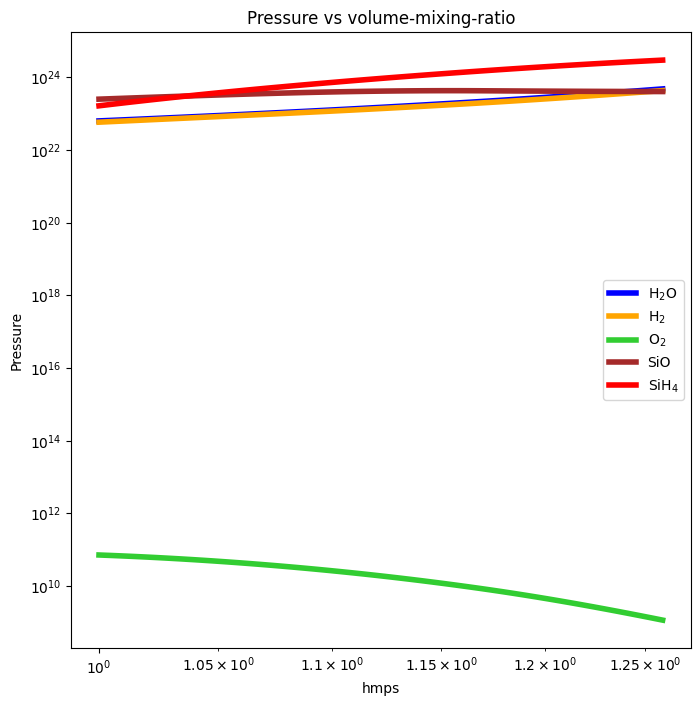

-5.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-5.8.xlsx


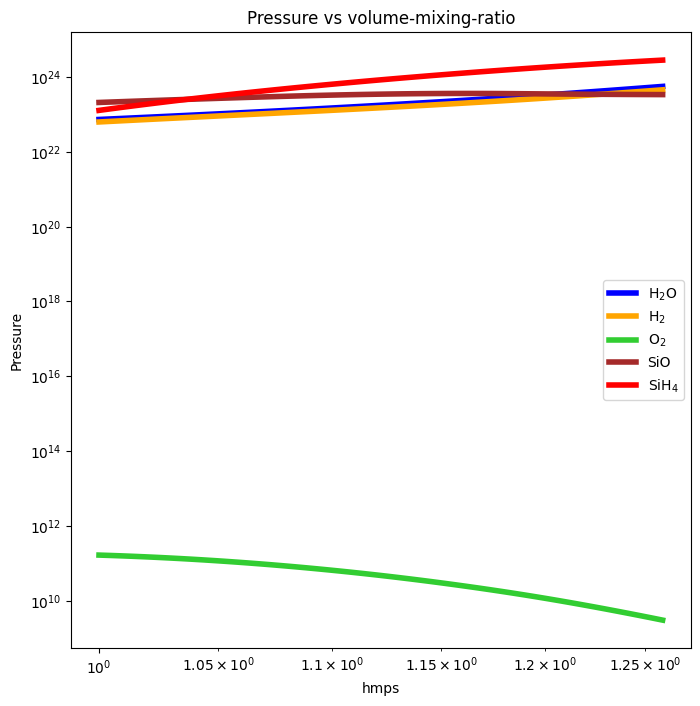

-5.5
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-5.5.xlsx


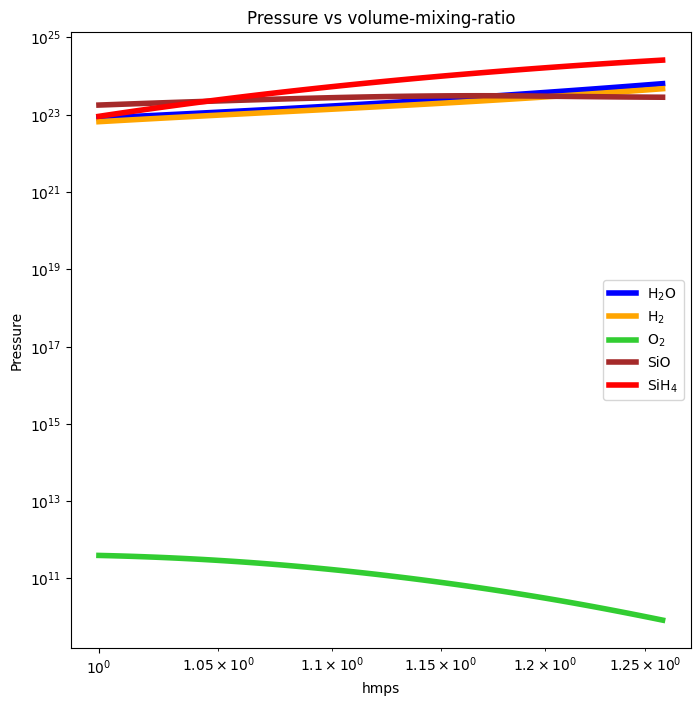

-5.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-5.3.xlsx


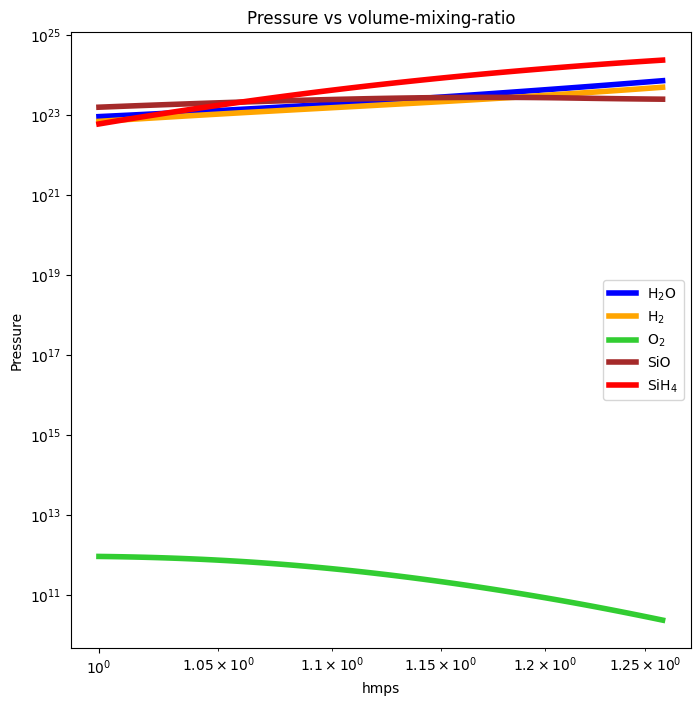

-5
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-5.xlsx


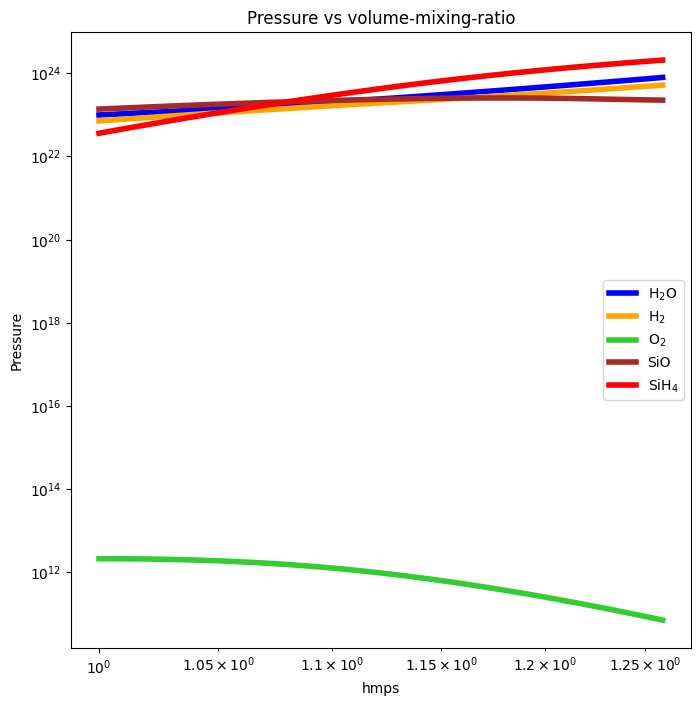

-4.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-4.8.xlsx


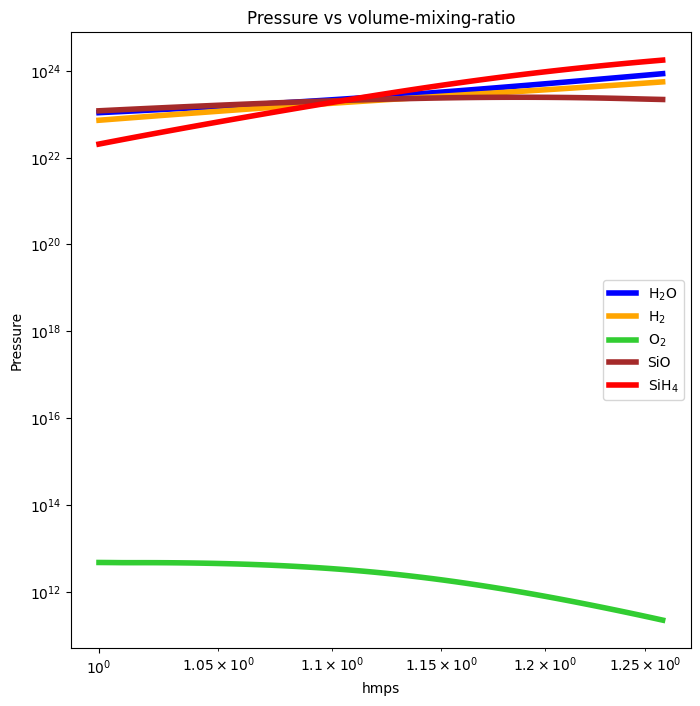

-4.5
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-4.5.xlsx


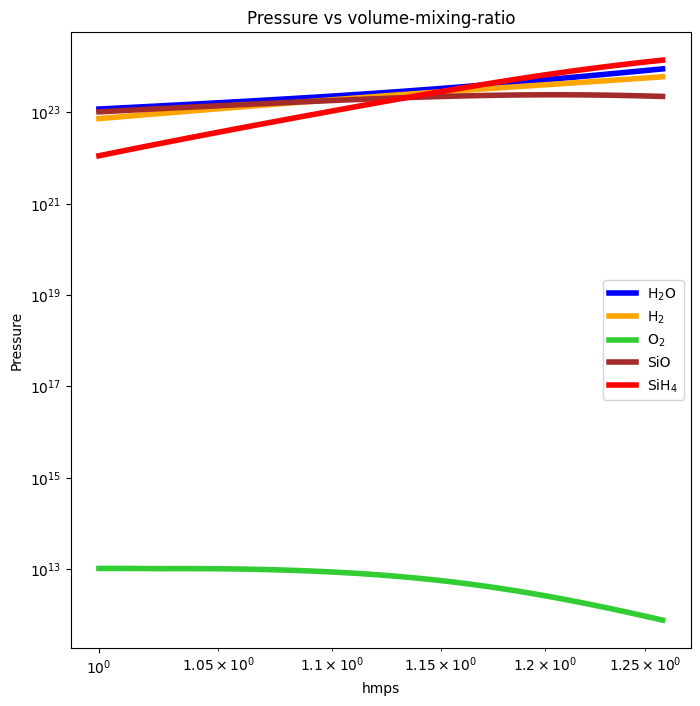

-4.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-4.3.xlsx


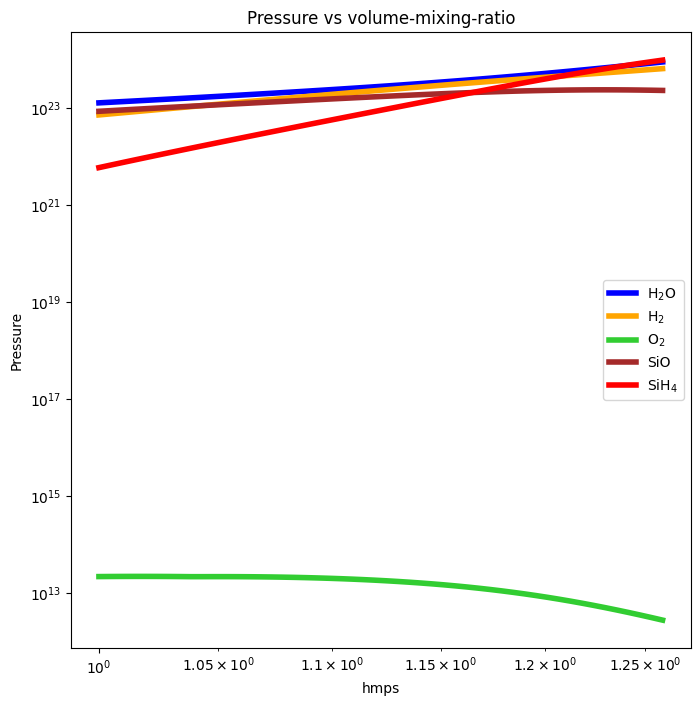

-4
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-4.xlsx


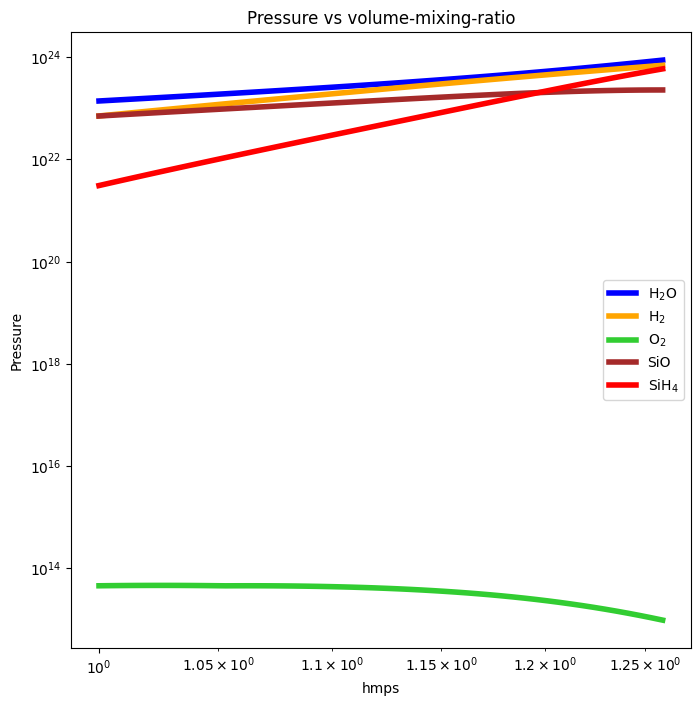

-3.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-3.8.xlsx


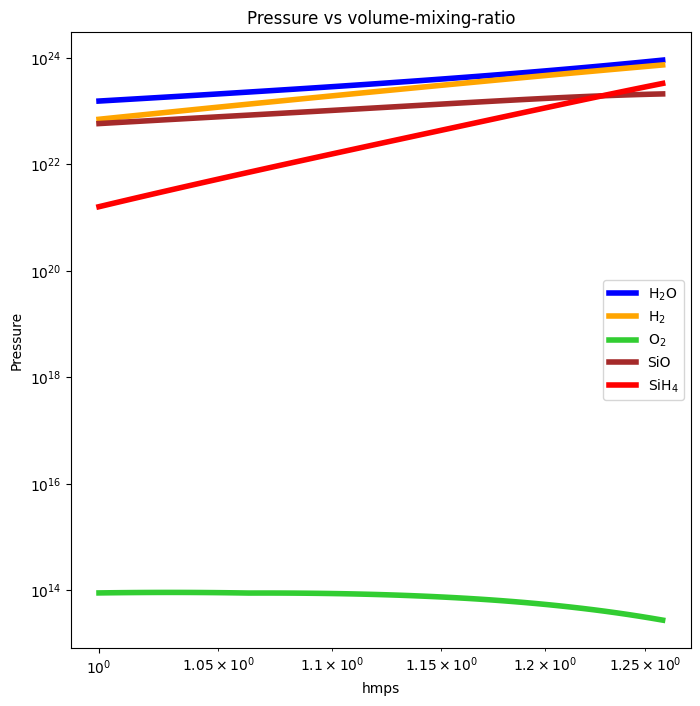

-3.6
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-3.6.xlsx


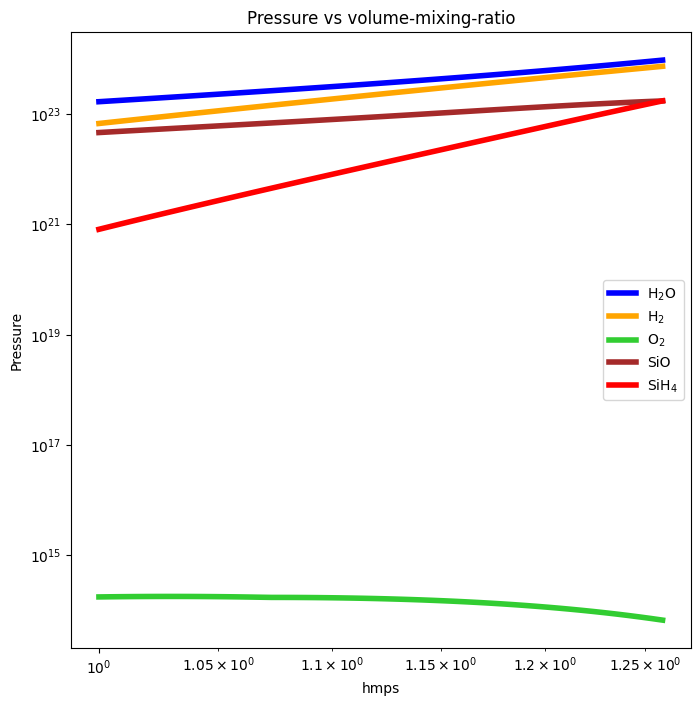

-3.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-3.3.xlsx


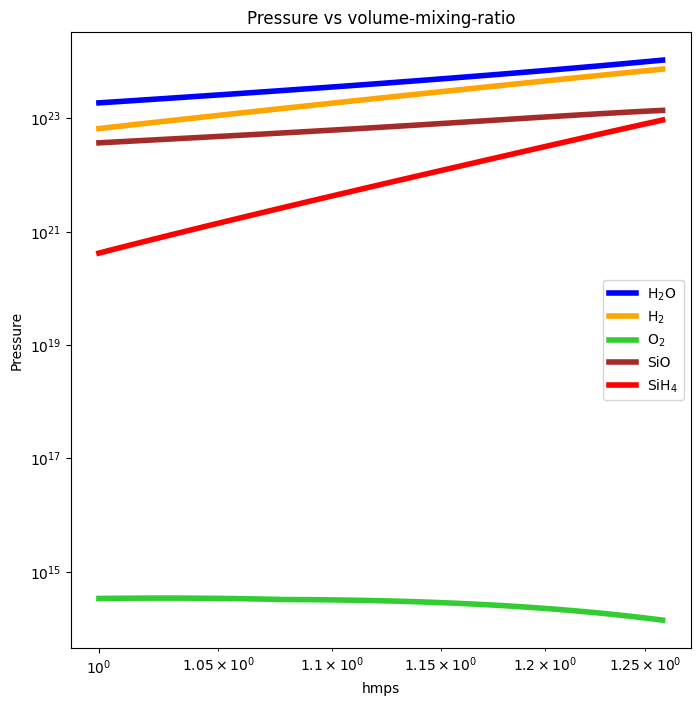

-3.1
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-3.1.xlsx


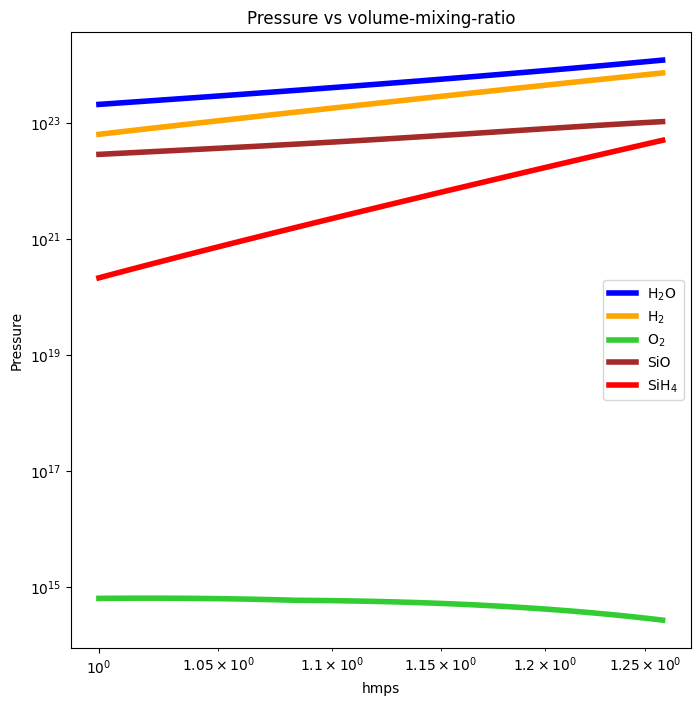

-2.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-2.8.xlsx


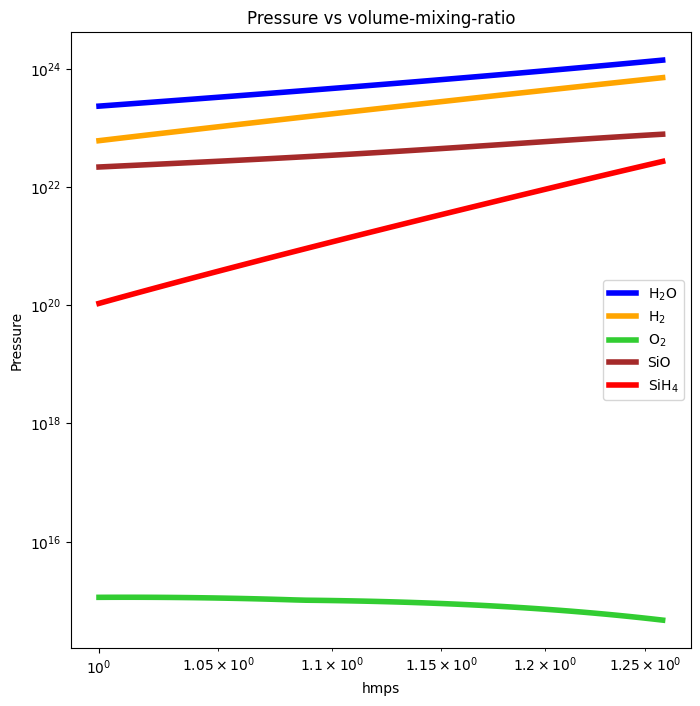

-2.6
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-2.6.xlsx


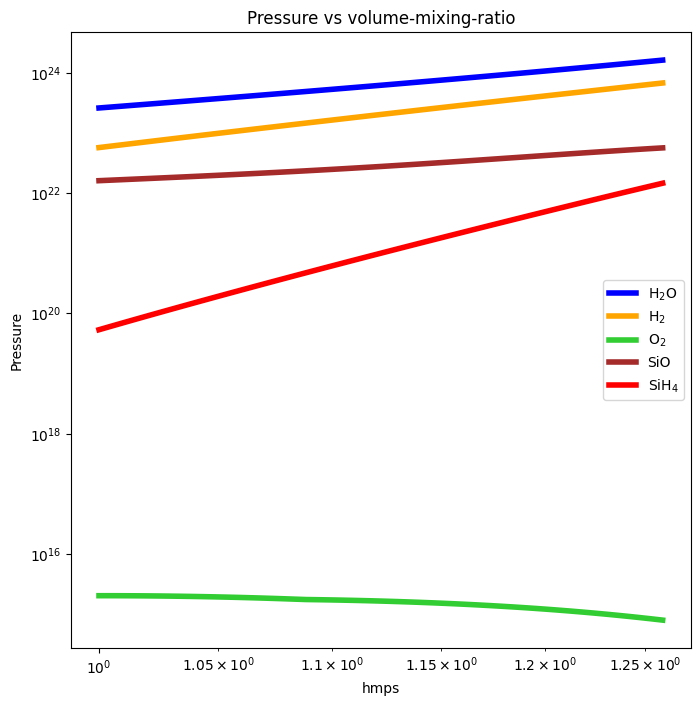

-2.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-2.3.xlsx


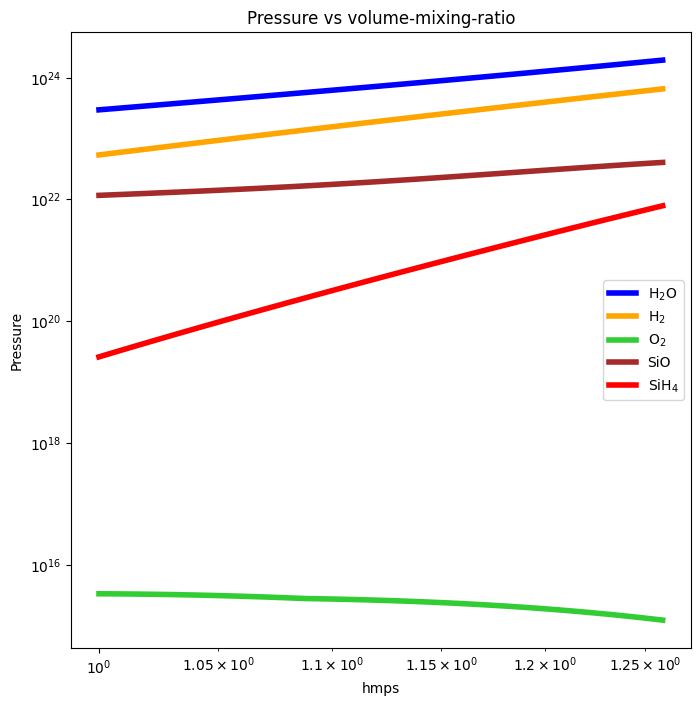

-2.1
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-2.1.xlsx


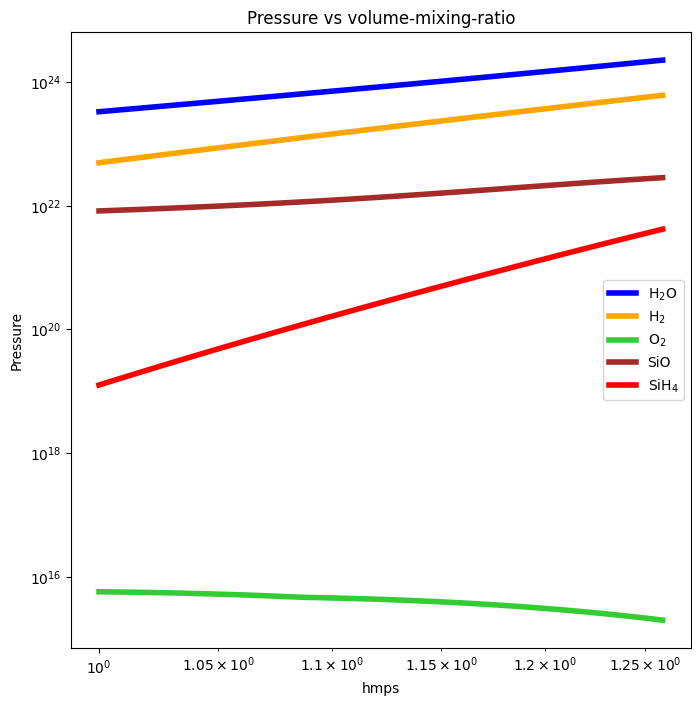

-1.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-1.8.xlsx


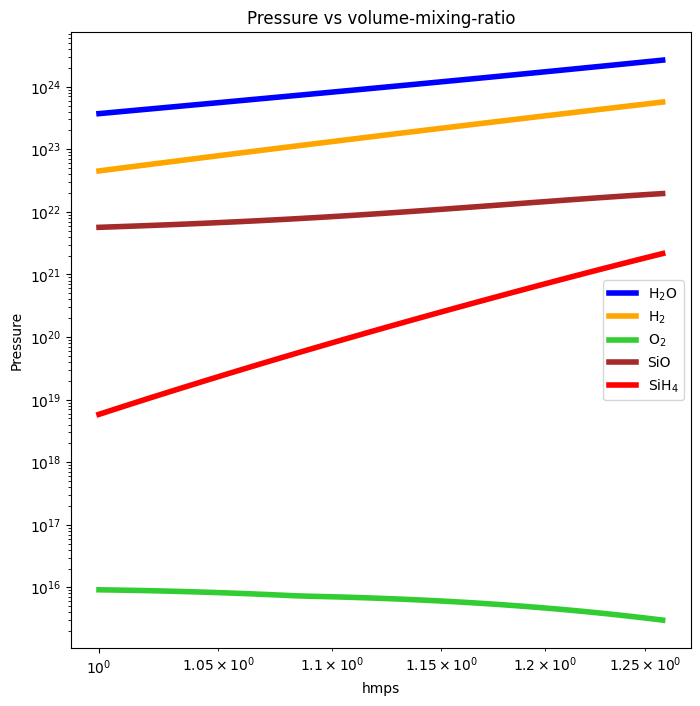

-1.6
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-1.6.xlsx


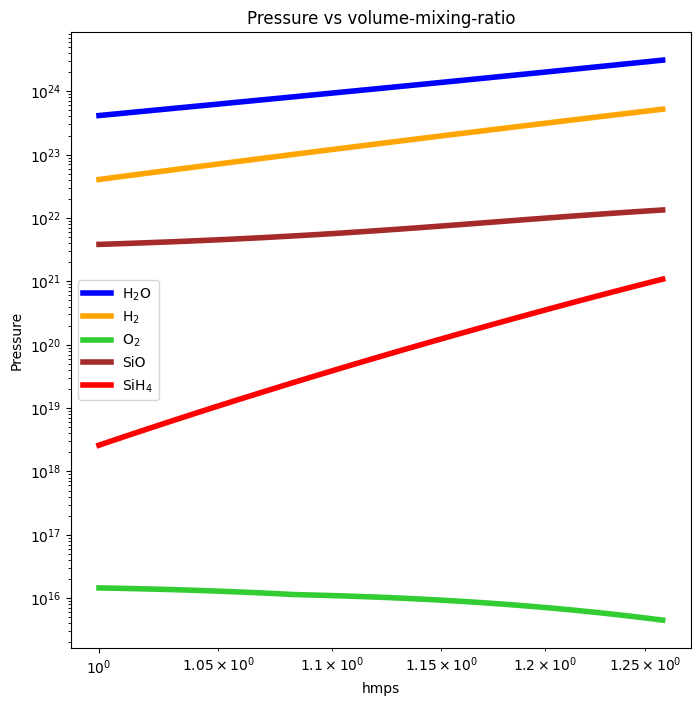

-1.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-1.3.xlsx


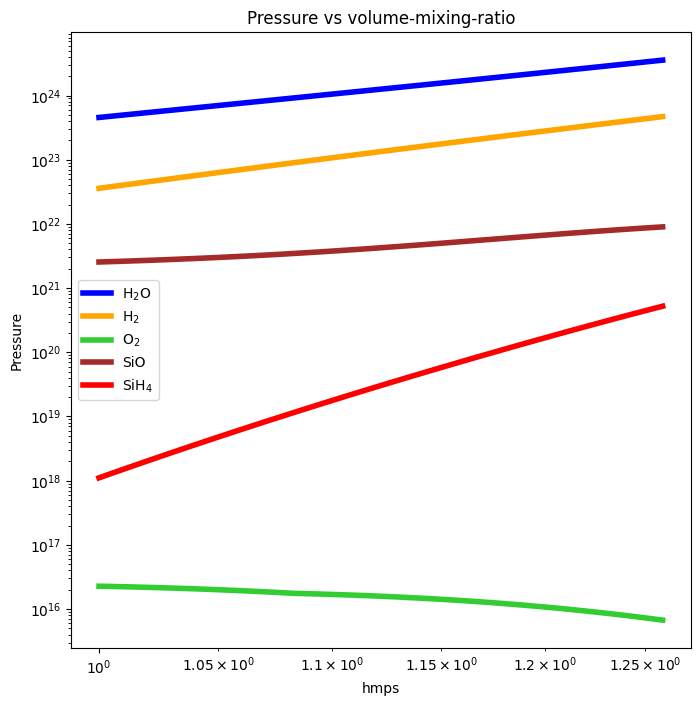

-1.1
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-1.1.xlsx


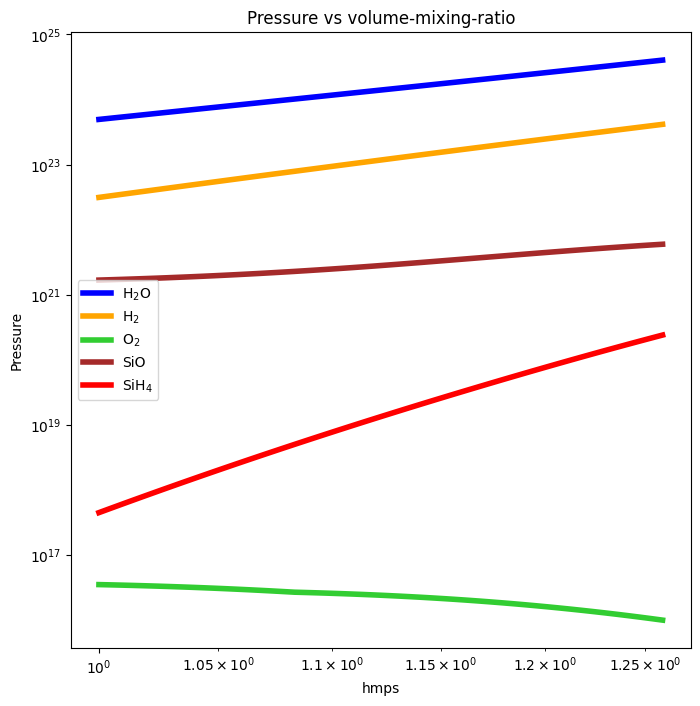

-0.86
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-0.86.xlsx


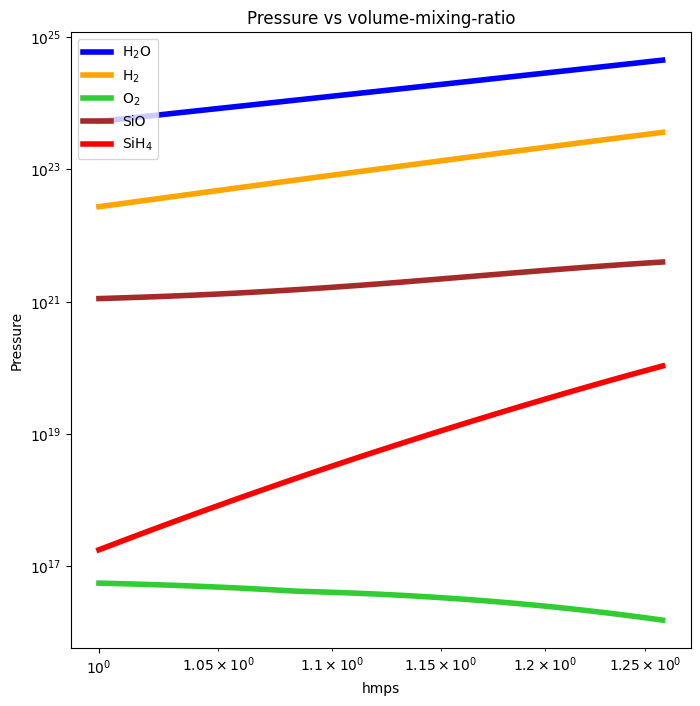

-0.61
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-0.61.xlsx


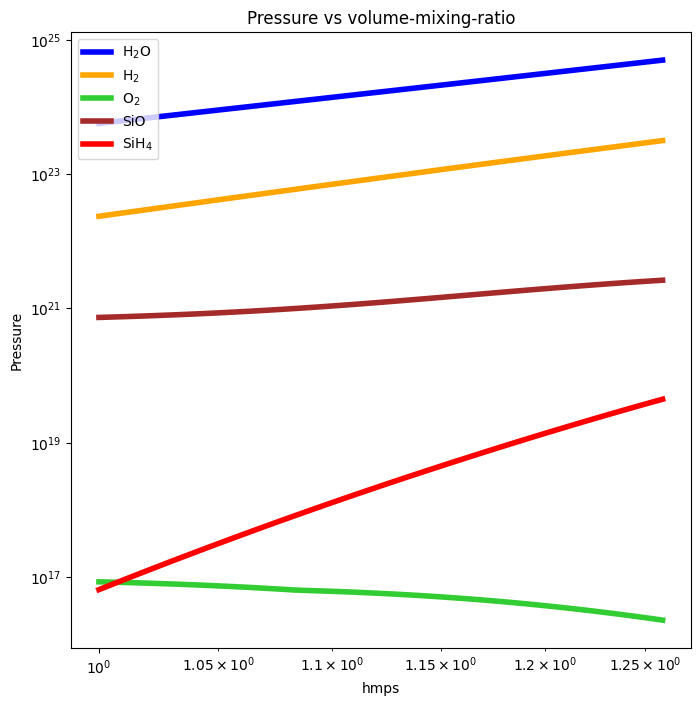

-0.37
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-0.37.xlsx


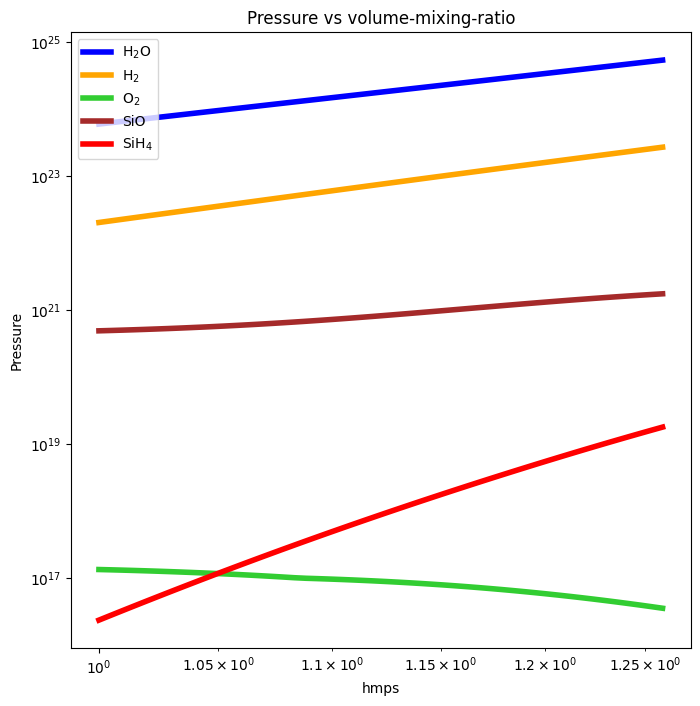

-0.12
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-0.12.xlsx


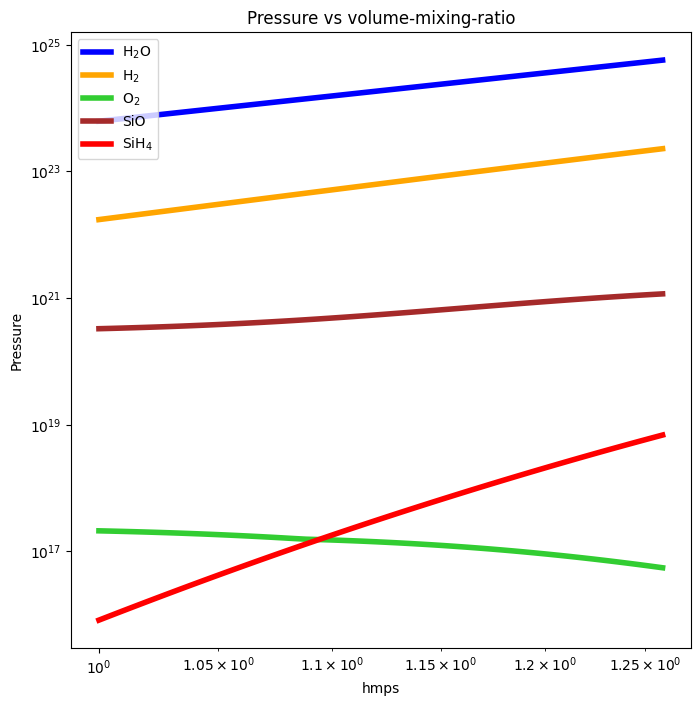

0.12
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO20.12.xlsx


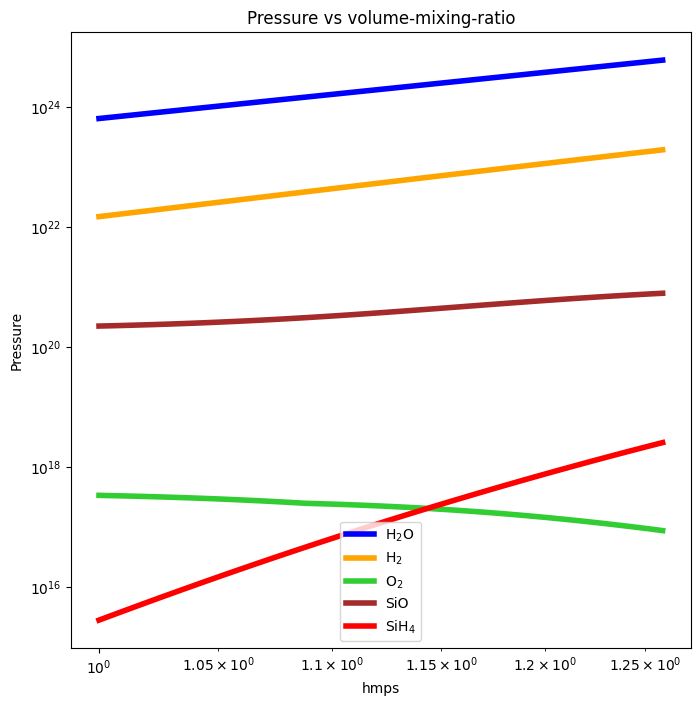

0.37
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO20.37.xlsx


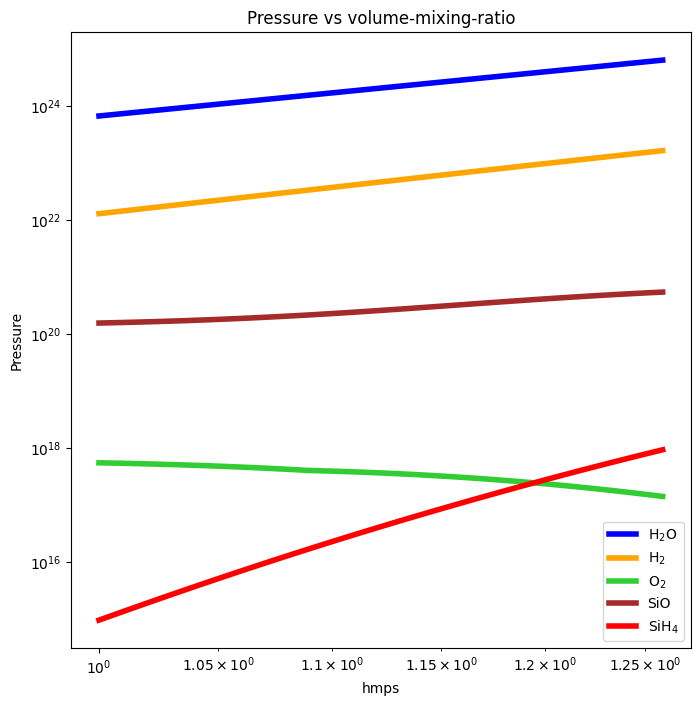

0.61
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO20.61.xlsx


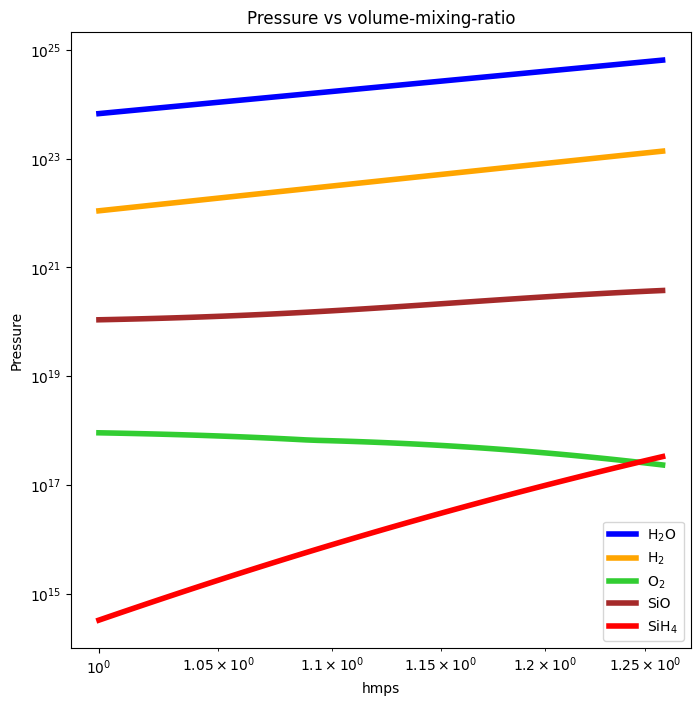

0.86
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO20.86.xlsx


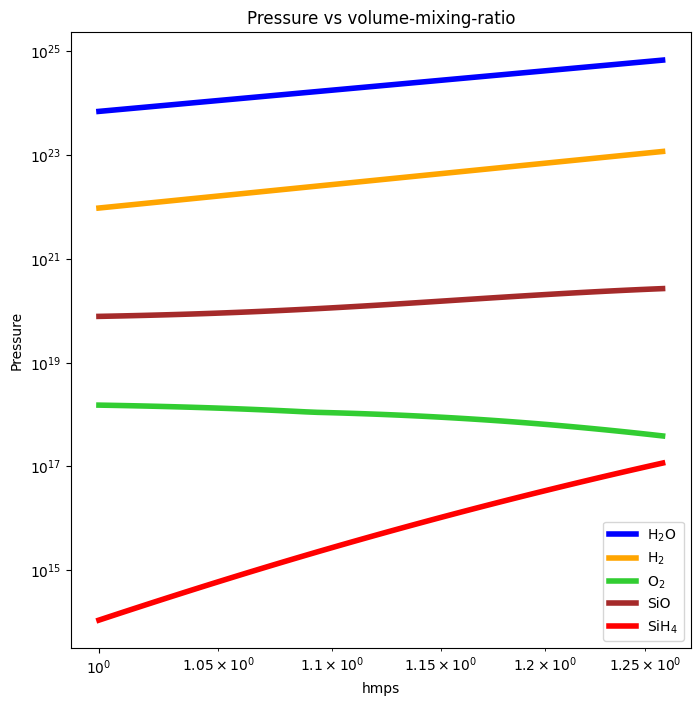

1.1
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO21.1.xlsx


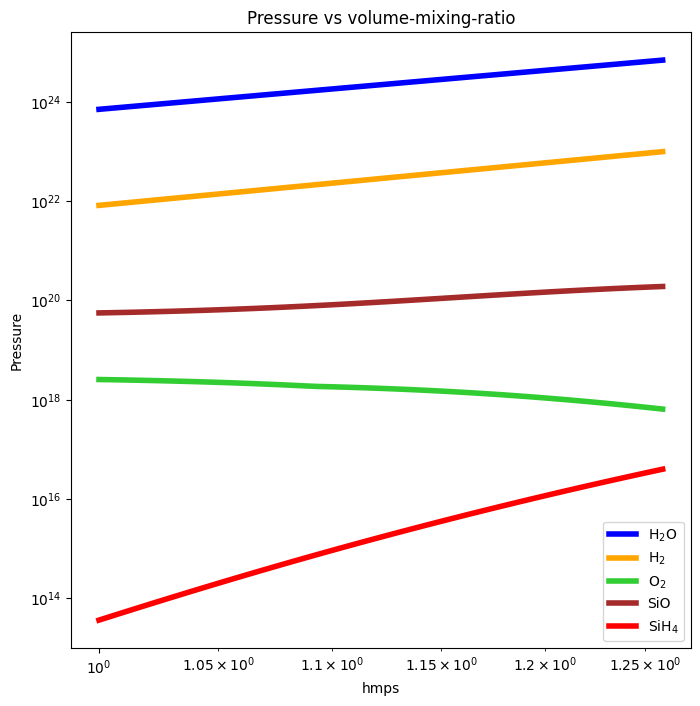

1.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO21.3.xlsx


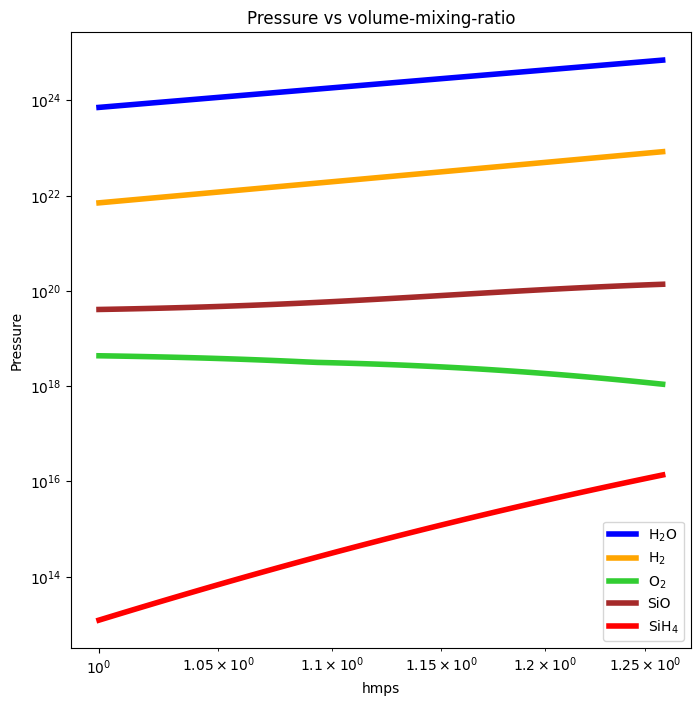

1.6
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO21.6.xlsx


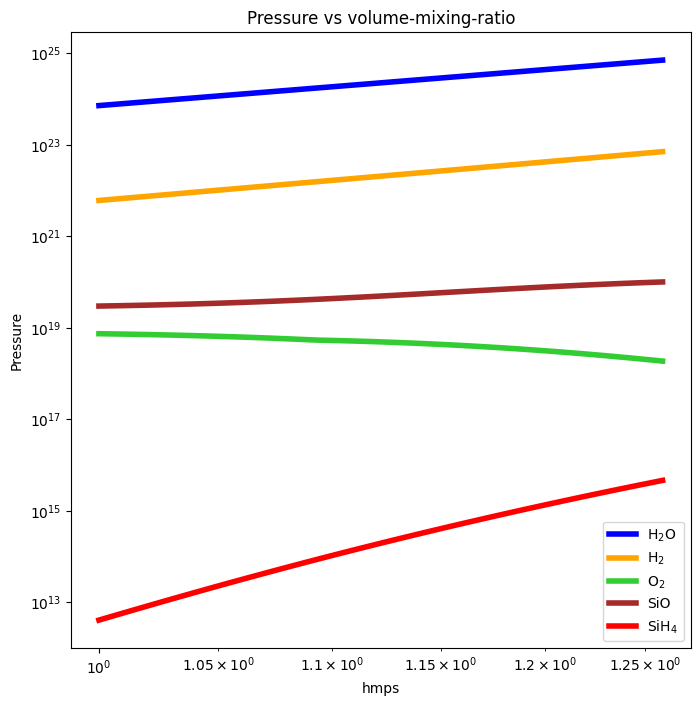

1.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO21.8.xlsx


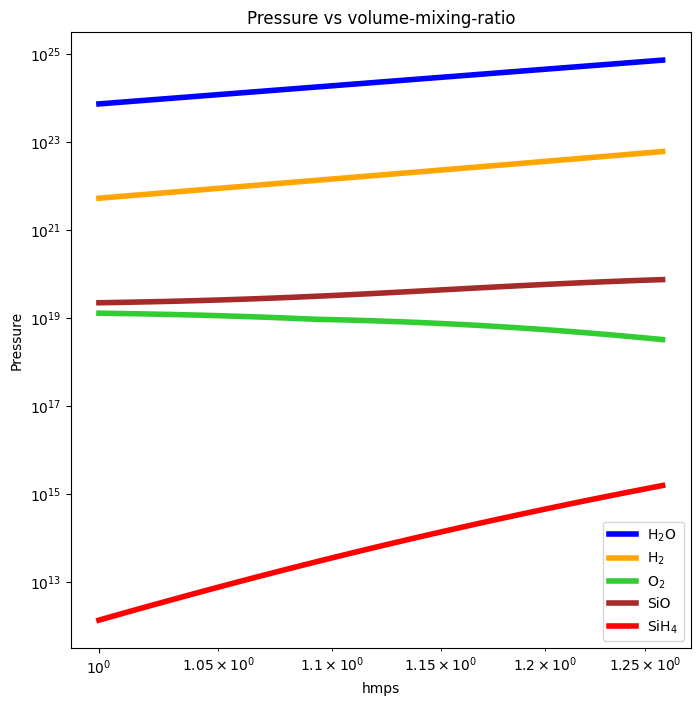

2.1
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO22.1.xlsx


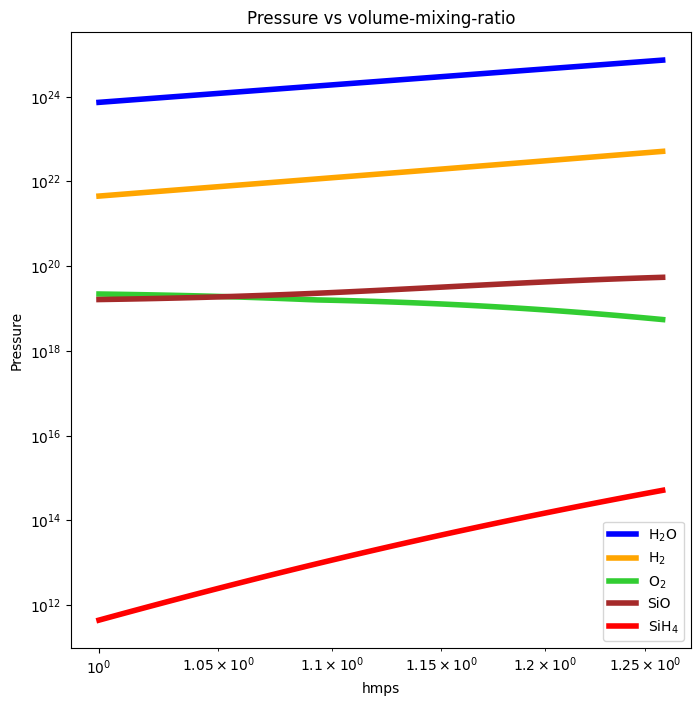

2.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO22.3.xlsx


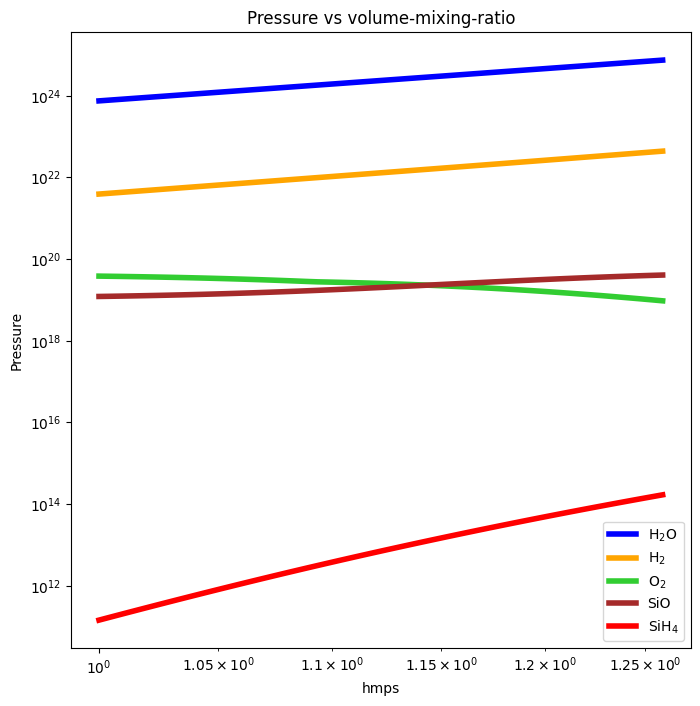

2.6
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO22.6.xlsx


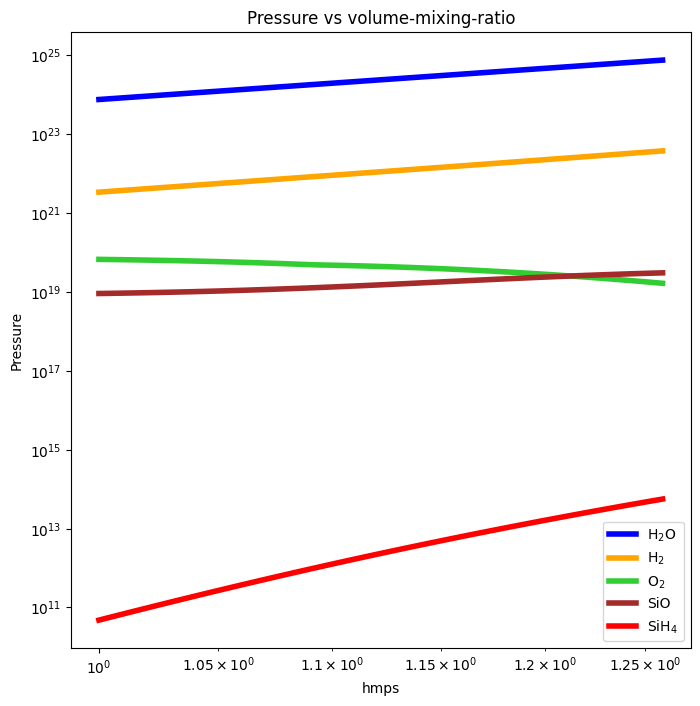

2.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO22.8.xlsx


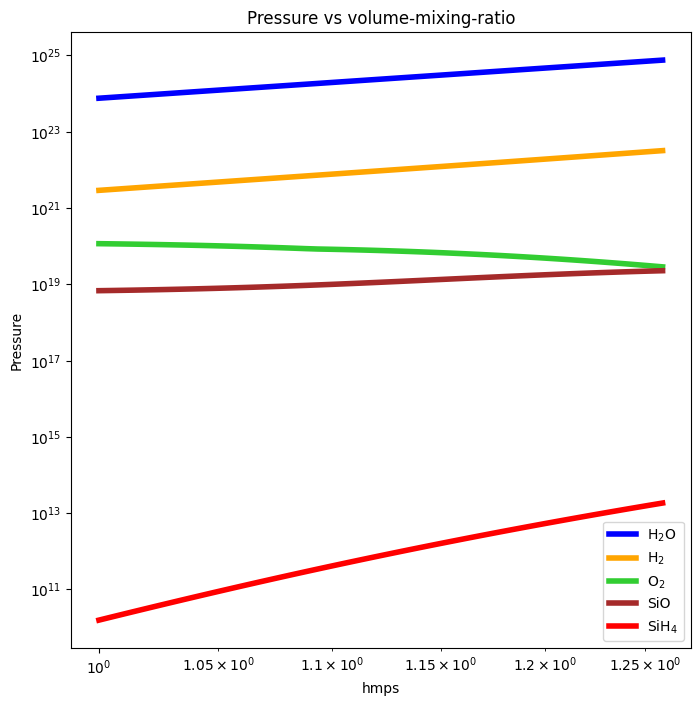

3.1
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO23.1.xlsx


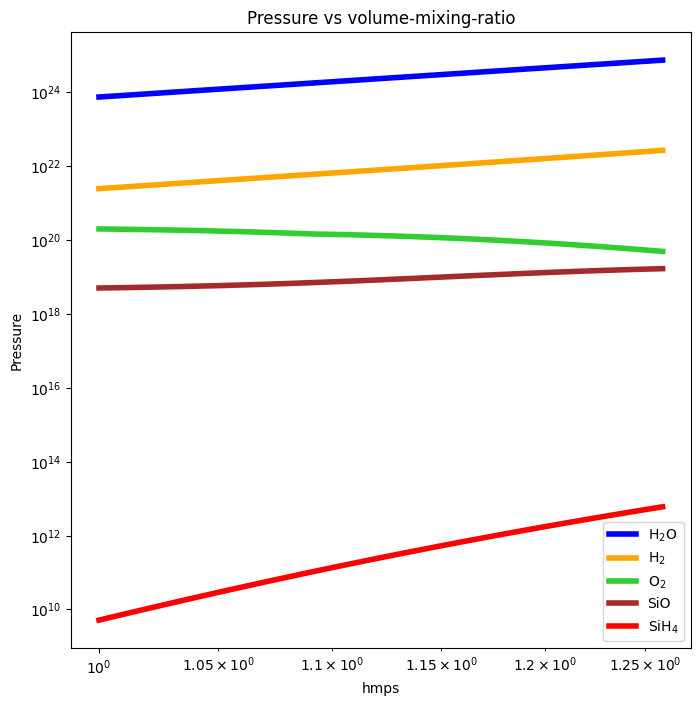

3.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO23.3.xlsx


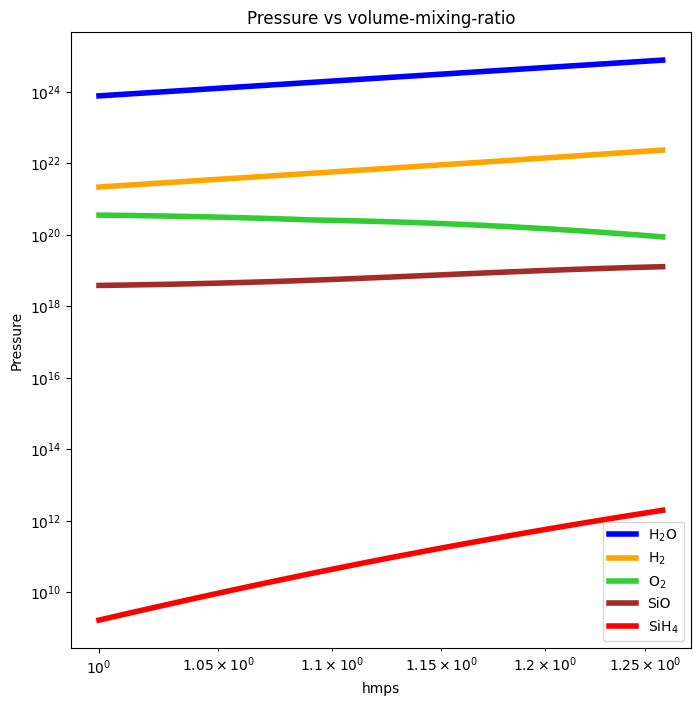

3.6
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO23.6.xlsx


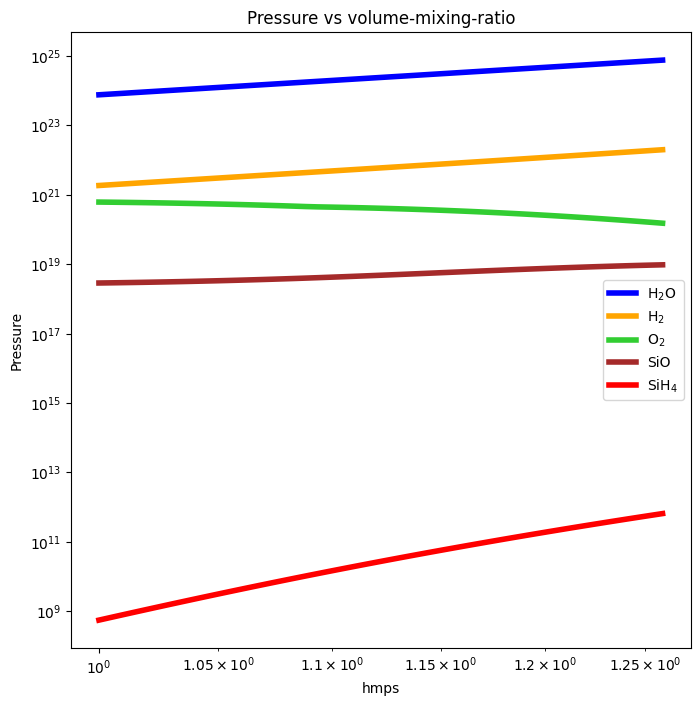

3.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO23.8.xlsx


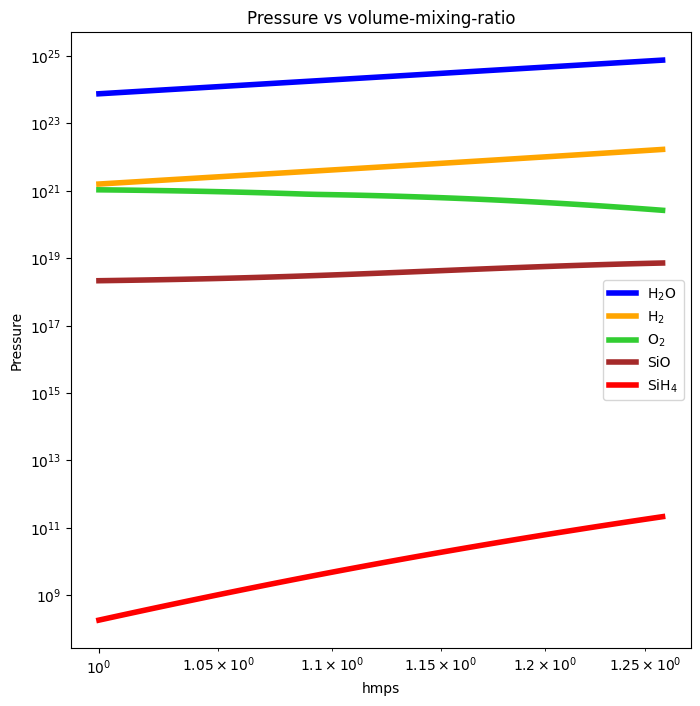

4
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO24.xlsx


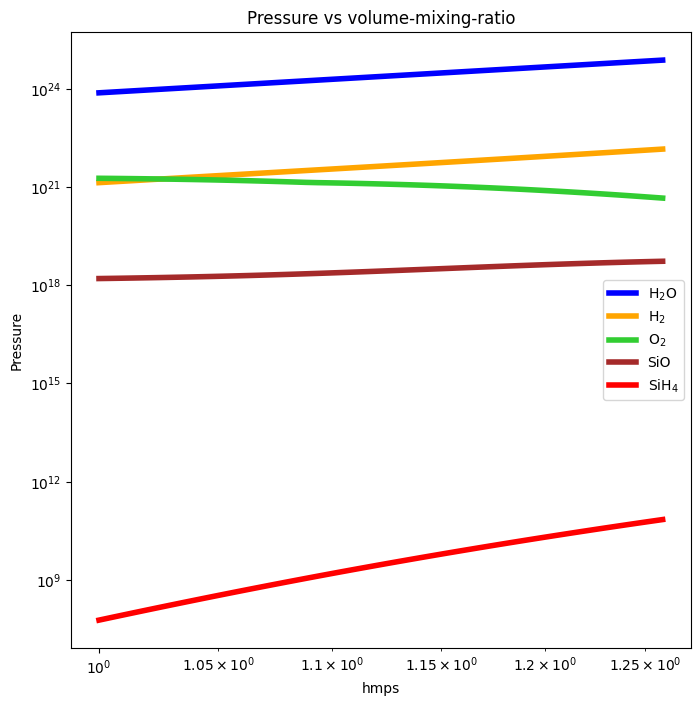

4.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO24.3.xlsx


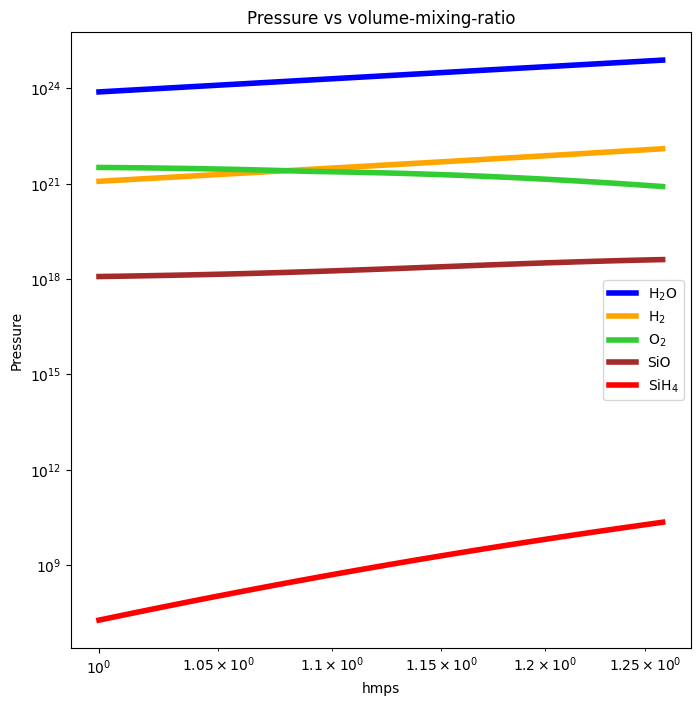

4.5
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO24.5.xlsx


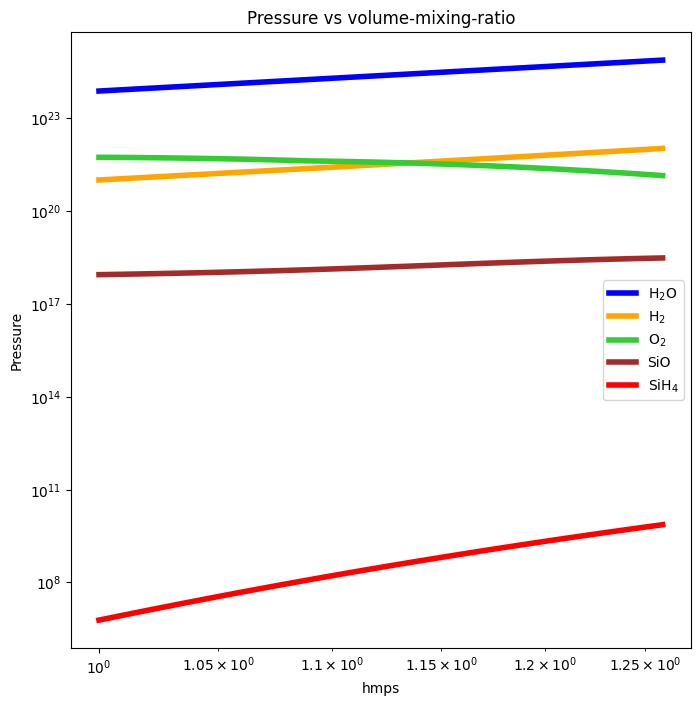

4.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO24.8.xlsx


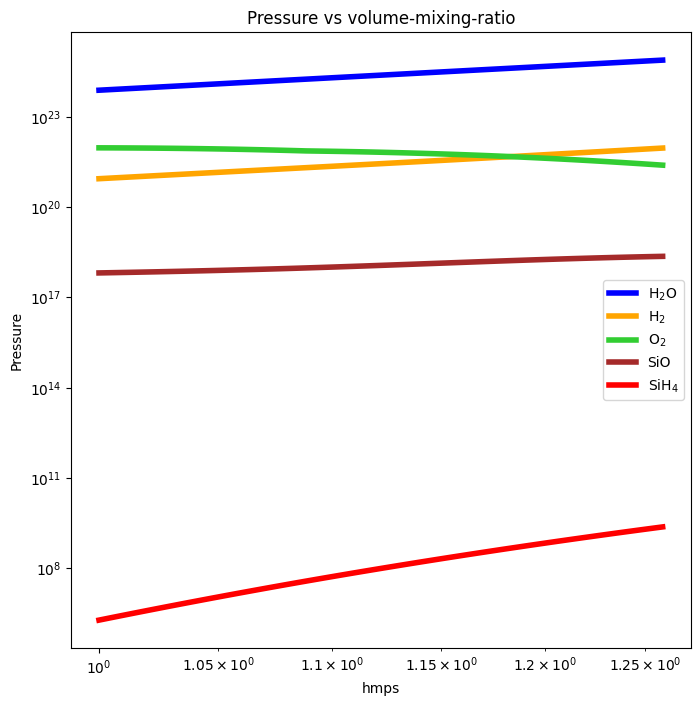

5
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO25.xlsx


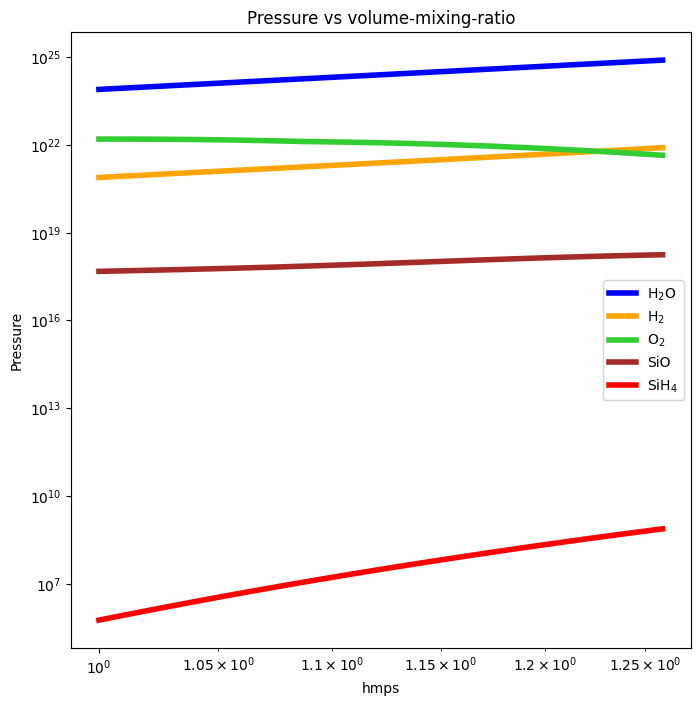

5.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO25.3.xlsx


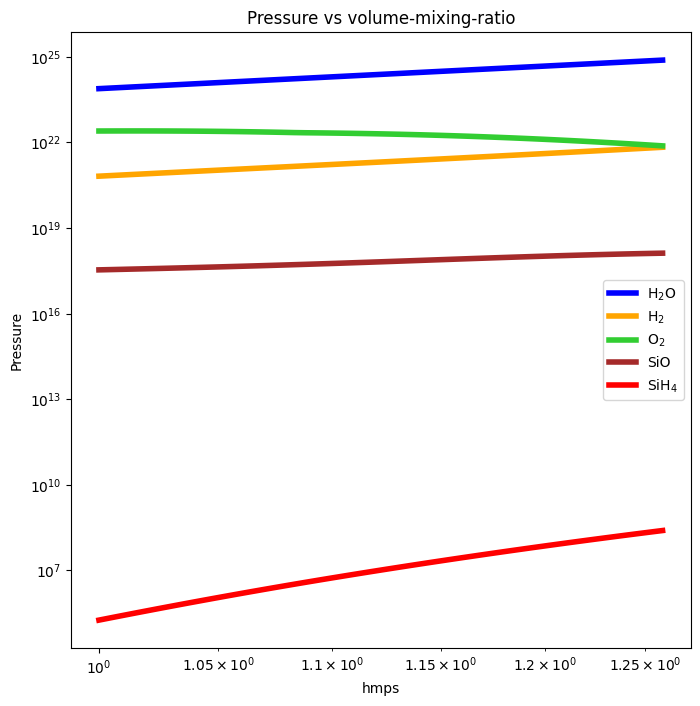

5.5
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO25.5.xlsx


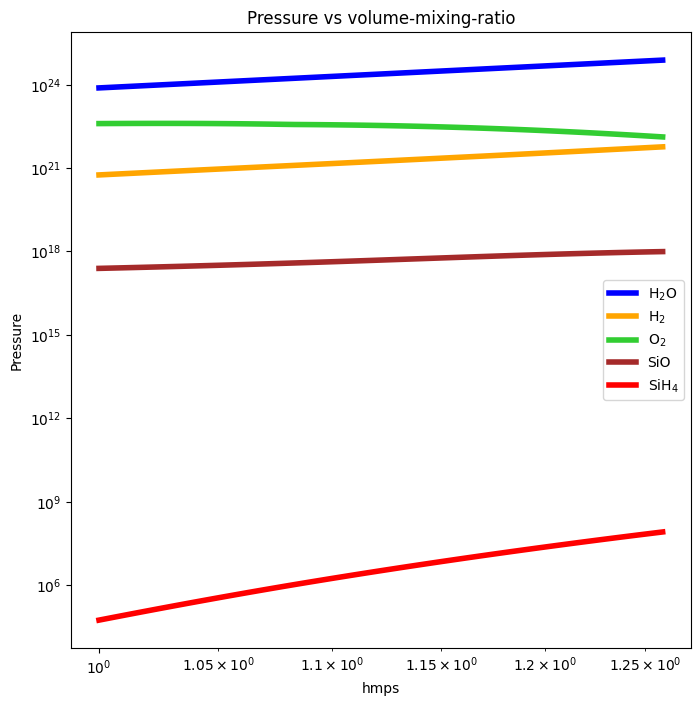

5.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO25.8.xlsx


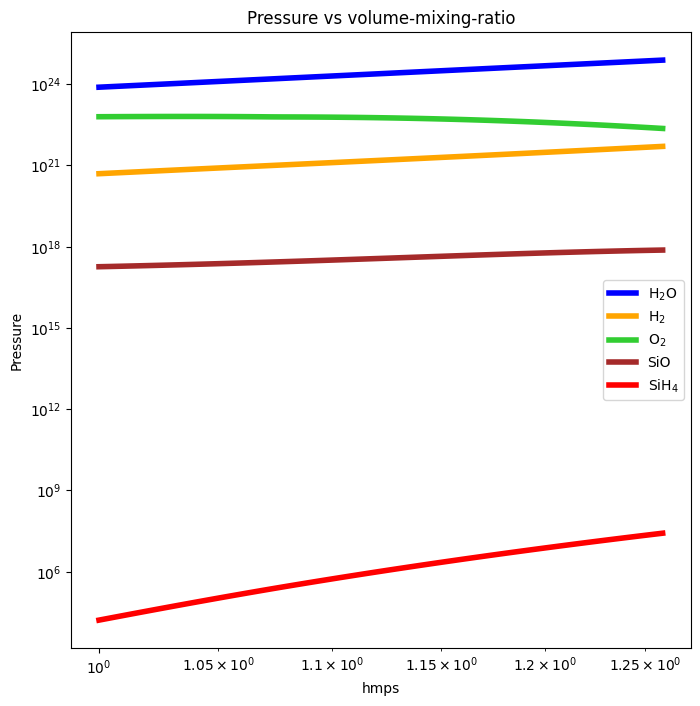

6
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO26.xlsx


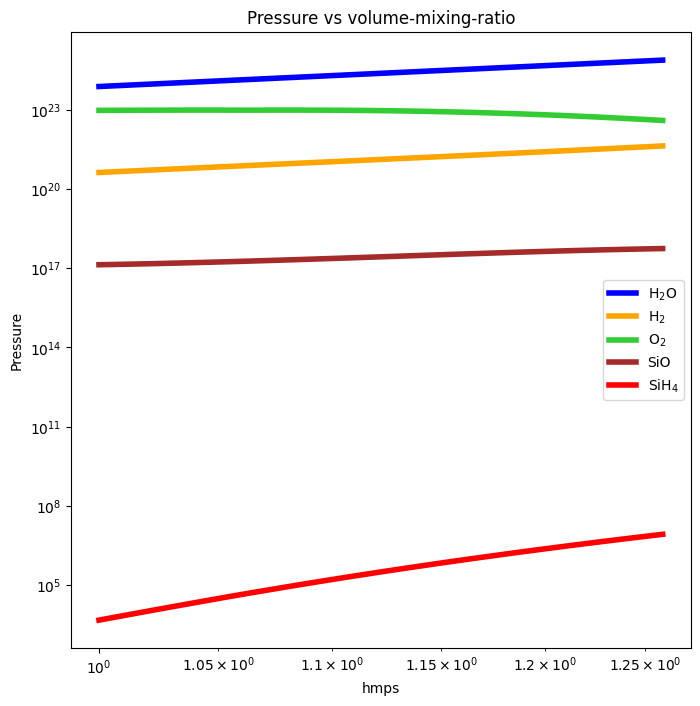

In [18]:
init_metallicity = 1
mantle_melt_fraction = 1

fO2_log10_shifts = np.linspace(-6, 6, number_of_realisations) 
for fO2_log10_shift in fO2_log10_shifts:
    shift = f"{fO2_log10_shift:.2g}"
    print(shift)
    filename = f"./excel_Uranus_solar_3000K/HOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}.xlsx"
    print(filename)
    # Pressures
    H2O_mass = pd.read_excel(filename, sheet_name="H2O_g")["total_mass"]
    H2_mass = pd.read_excel(filename, sheet_name="H2_g")["total_mass"]
    O2_mass = pd.read_excel(filename, sheet_name="O2_g")["total_mass"]
    SiO_mass = pd.read_excel(filename, sheet_name="OSi_g")["total_mass"]
    SiH4_mass = pd.read_excel(filename, sheet_name="H4Si_g")["total_mass"]
    tot_mass = pd.read_excel(filename, sheet_name="state")["mantle_melt_mass"]

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.plot(hmps,H2O_mass, color=color_H2O, lw=4, ls="-", label="H$_2$O")
    ax.plot(hmps,H2_mass, color=color_H2, lw=4, ls="-", label="H$_2$")
    ax.plot(hmps,O2_mass, color=color_O2, lw=4, ls="-", label="O$_2$")
    ax.plot(hmps,SiO_mass, color=color_SiO, lw=4, ls="-", label="SiO")
    ax.plot(hmps,SiH4_mass, color=color_SiH4, lw=4, ls="-", label="SiH$_4$")

    # Set labels and title
    ax.set_xlabel('hmps')
    ax.set_ylabel('Pressure')
    ax.set_title('Pressure vs volume-mixing-ratio')
    ax.set_yscale('log') 
    ax.set_xscale('log') 
    # Add a legend
    ax.legend()

    # Show the plot
    plt.show()
    plt.close
#fig.savefig(f"images_U2/pressure_volume_mixing_ratio/HHeCNOSi_magma_sol_real_{init_metallicity}_temp_{atmosphere_temperature}_pressure_volume_mixing_ratio.png", dpi=300, bbox_inches="tight")


-6
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-6.xlsx


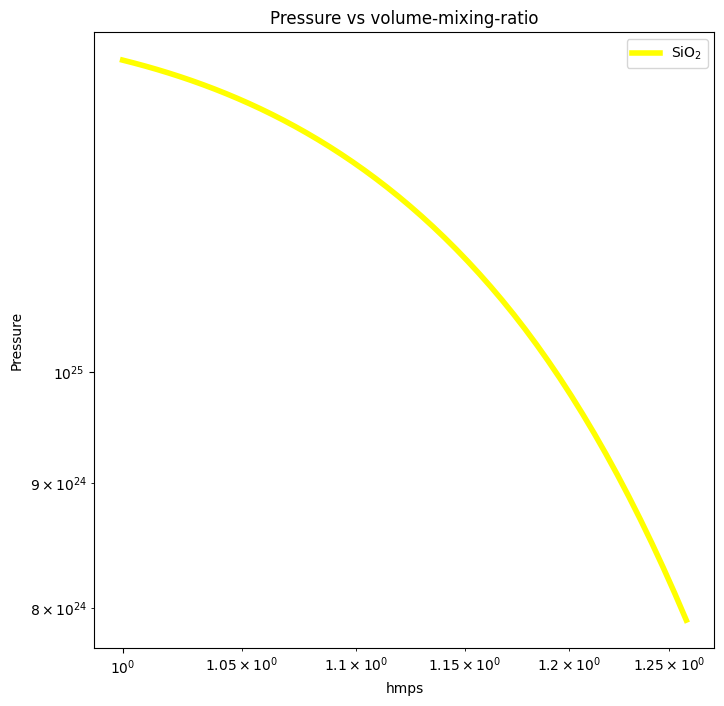

-5.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-5.8.xlsx


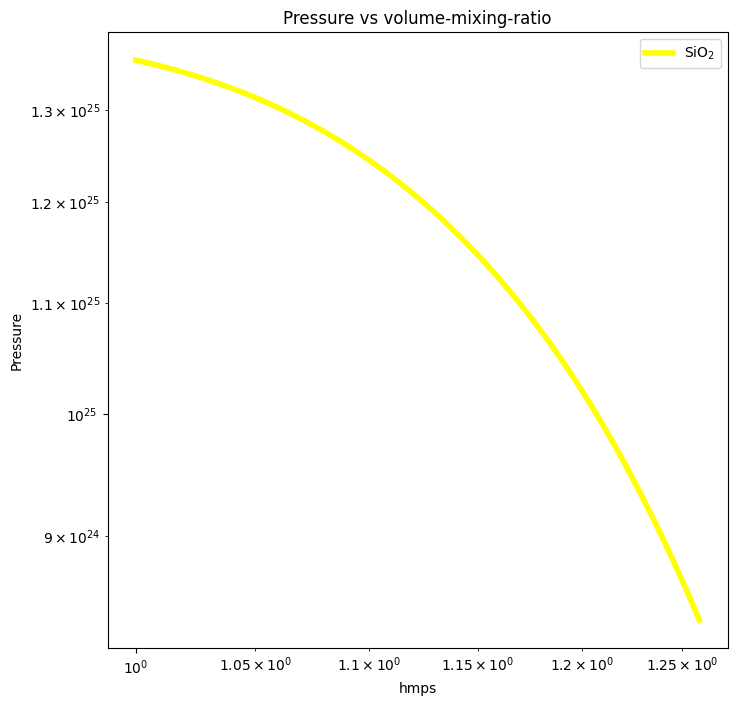

-5.5
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-5.5.xlsx


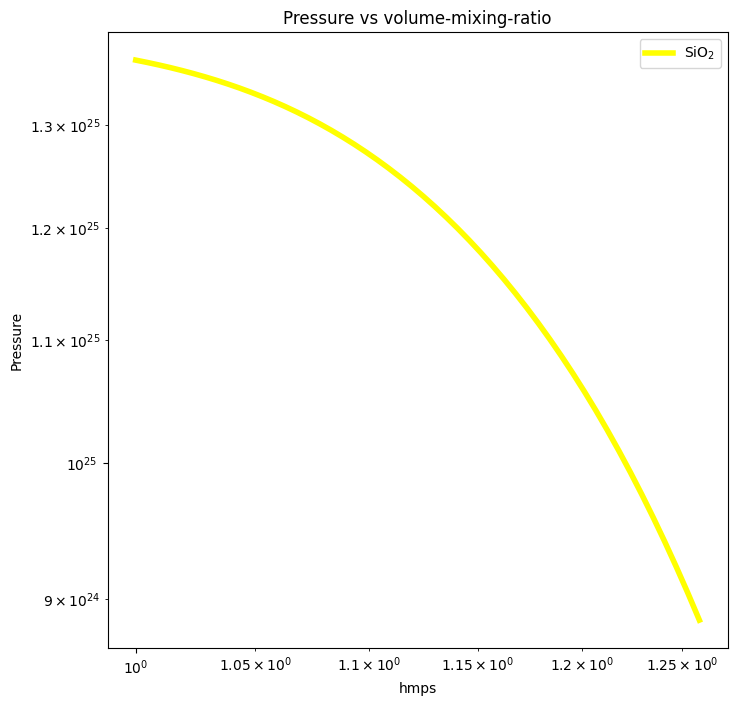

-5.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-5.3.xlsx


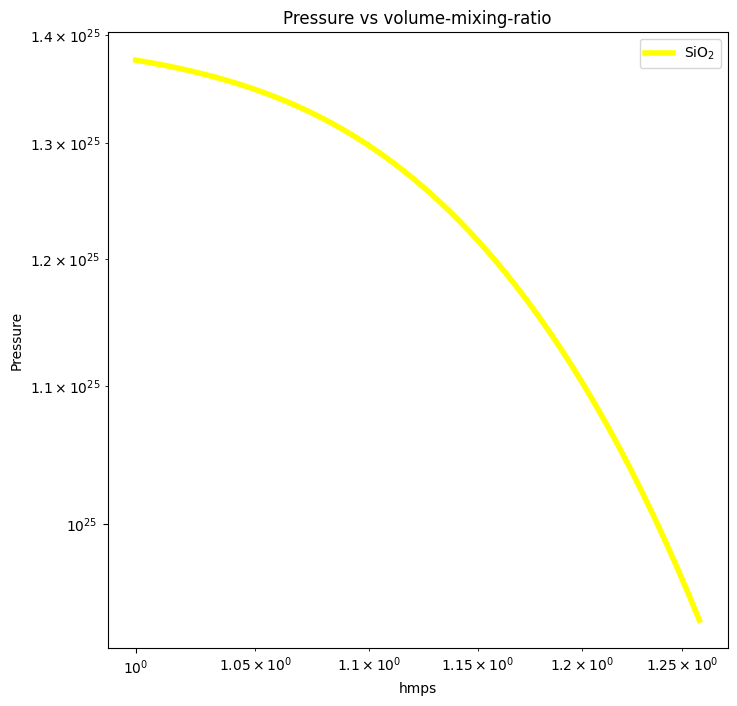

-5
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-5.xlsx


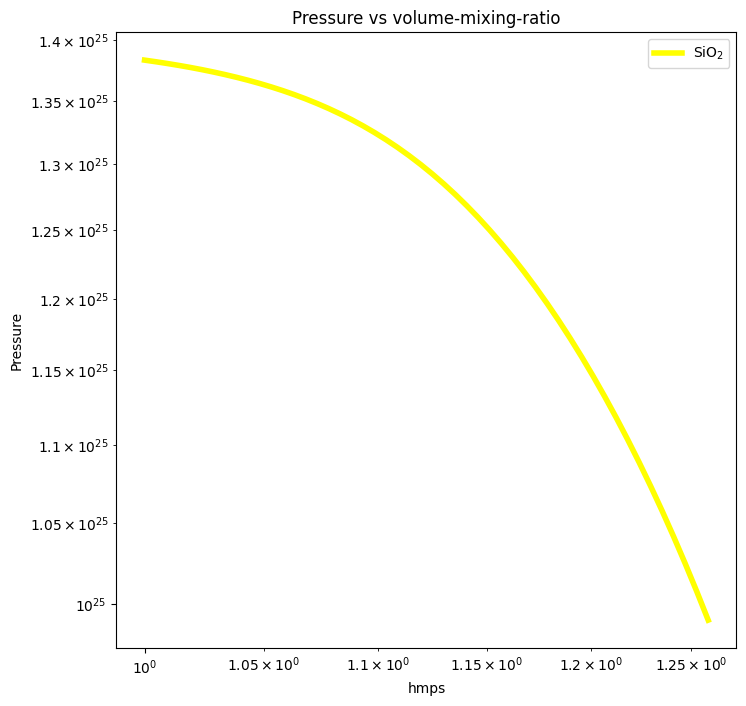

-4.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-4.8.xlsx


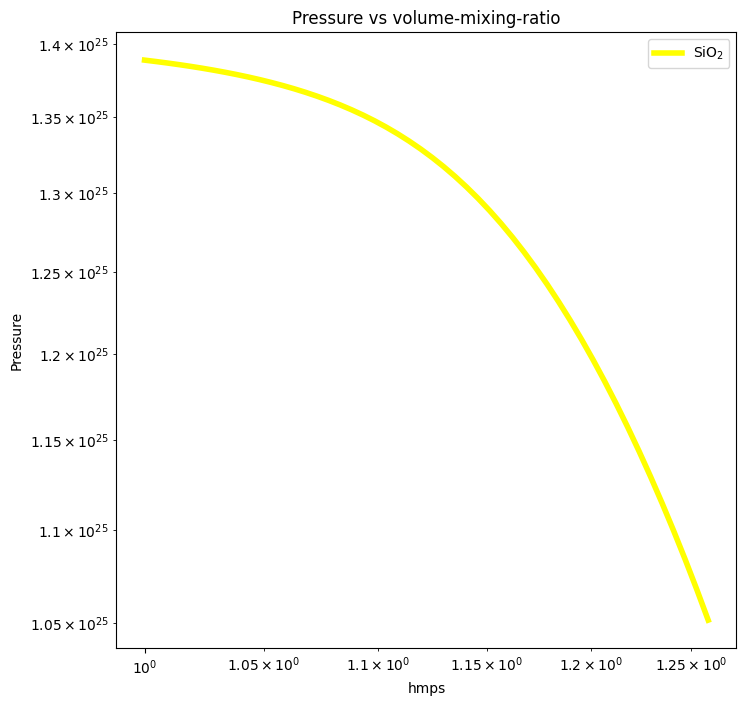

-4.5
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-4.5.xlsx


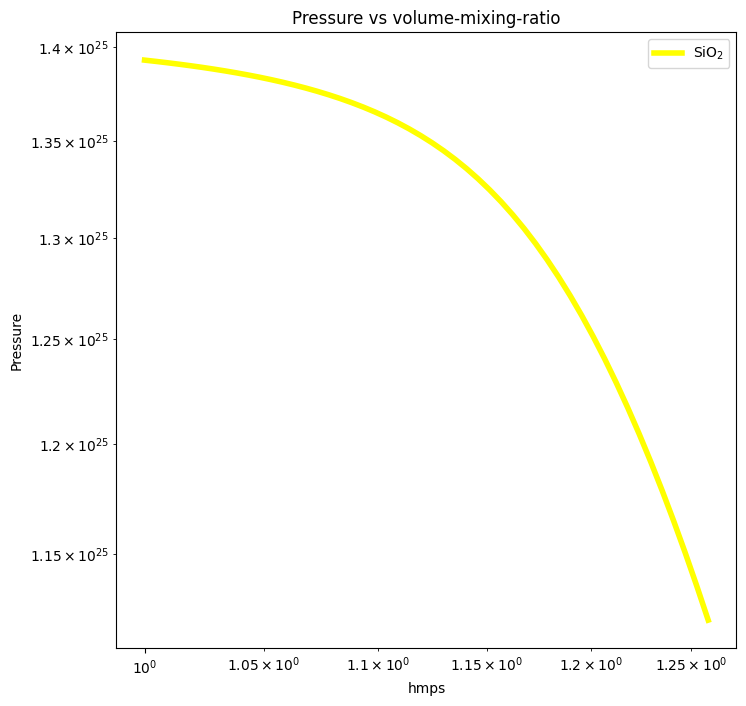

-4.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-4.3.xlsx


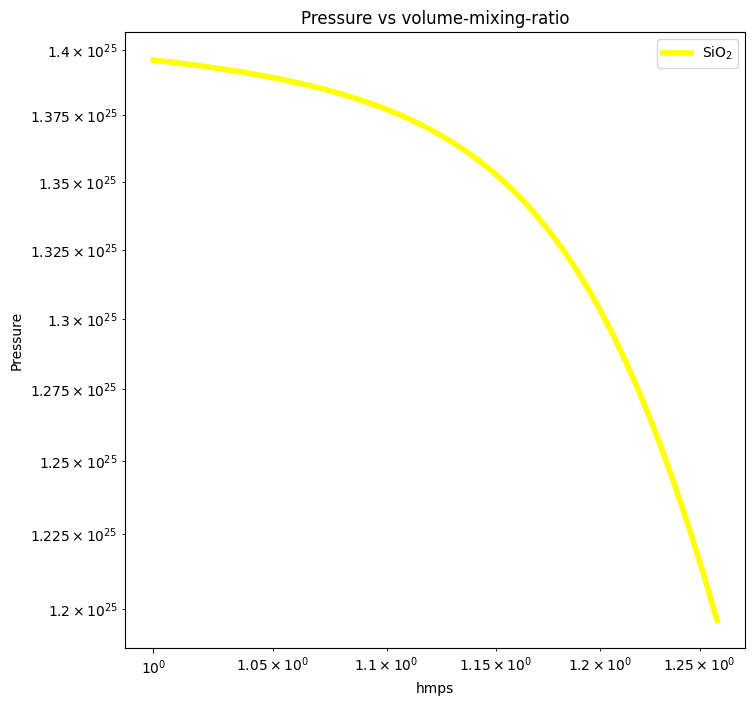

-4
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-4.xlsx


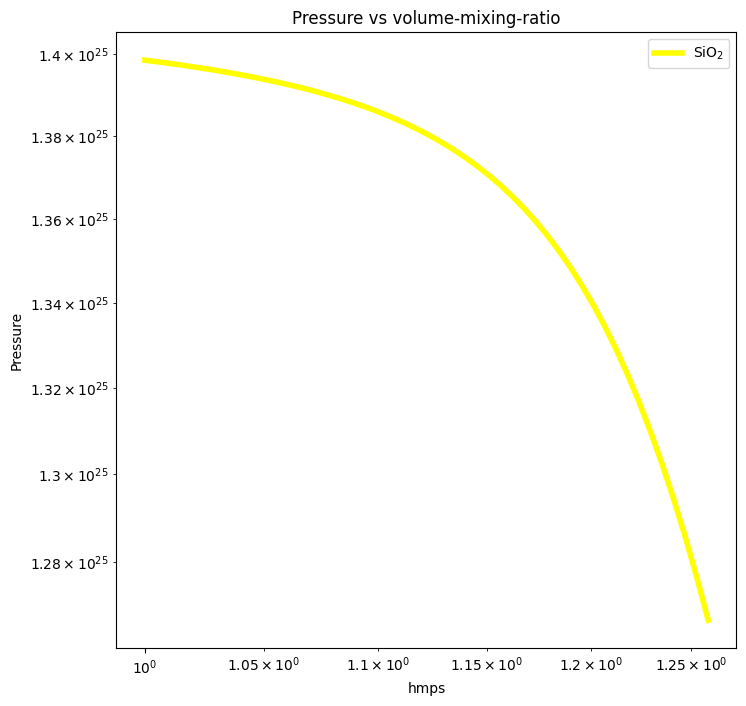

-3.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-3.8.xlsx


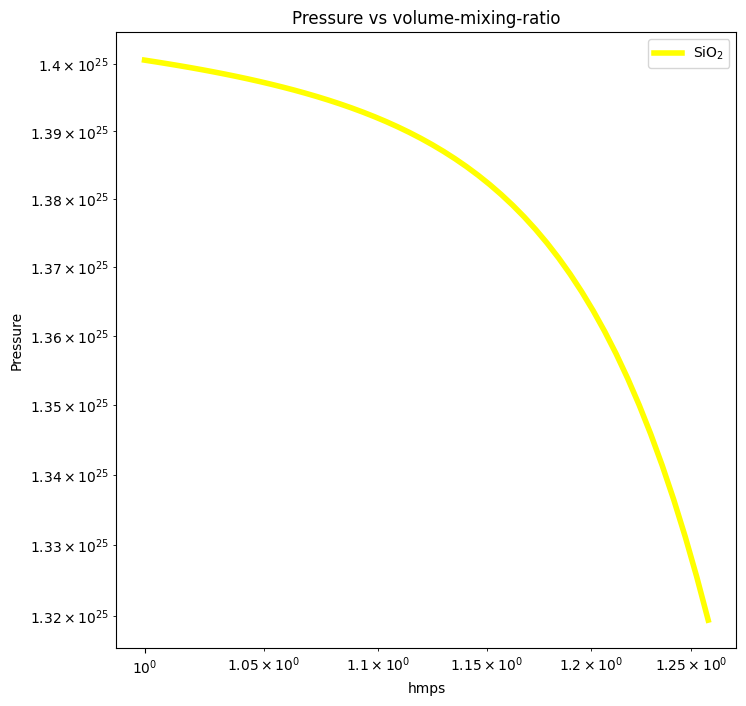

-3.6
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-3.6.xlsx


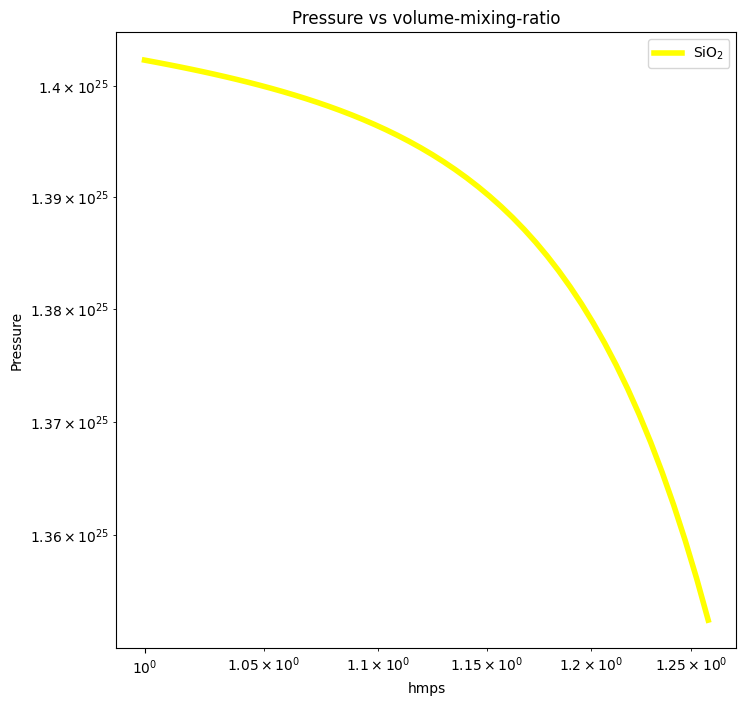

-3.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-3.3.xlsx


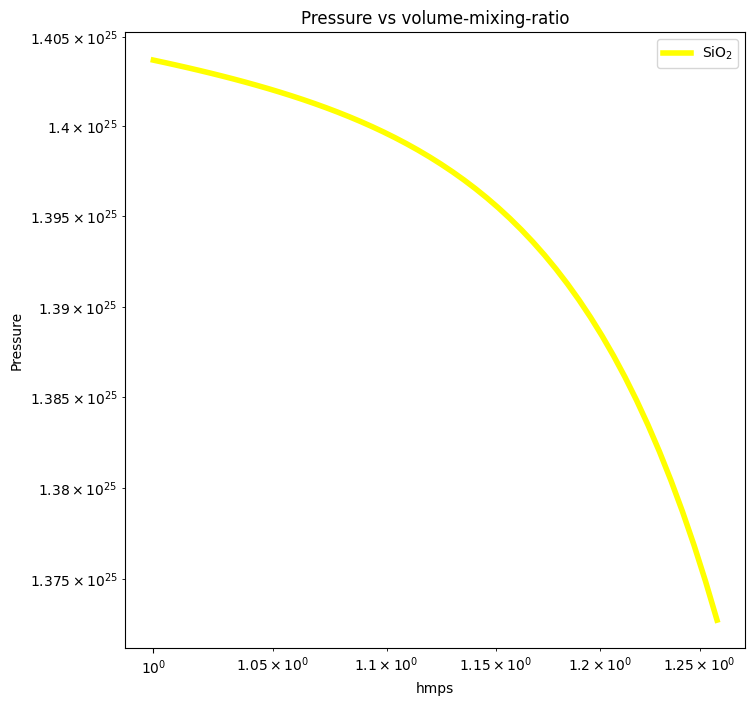

-3.1
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-3.1.xlsx


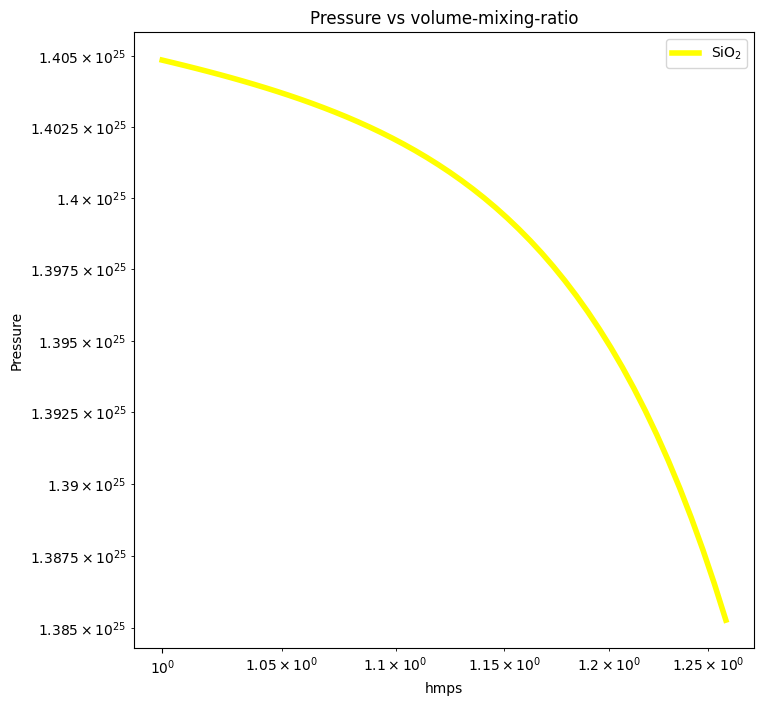

-2.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-2.8.xlsx


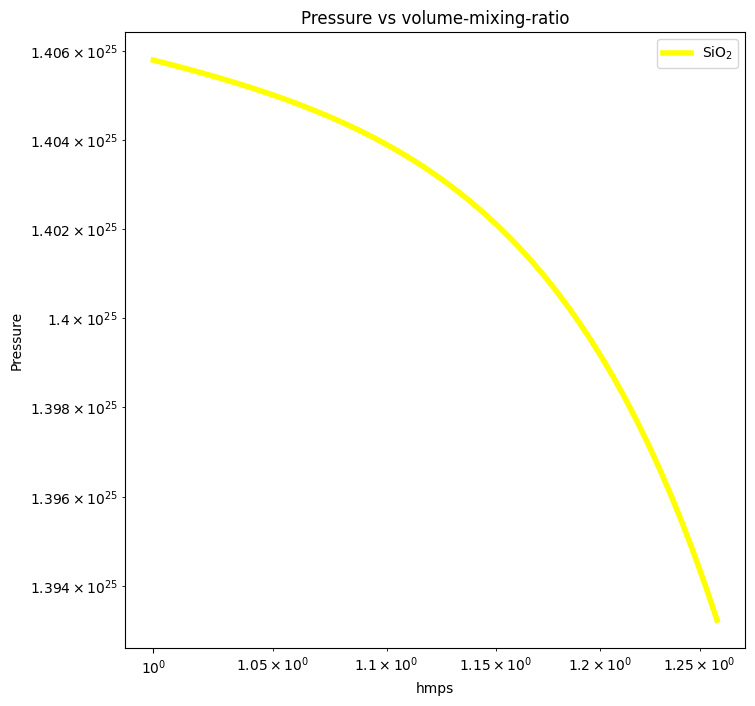

-2.6
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-2.6.xlsx


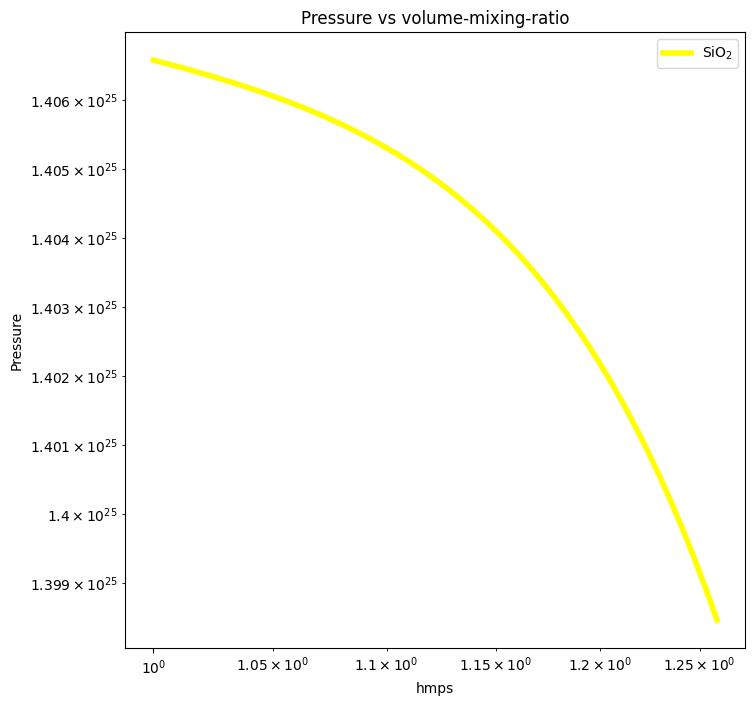

-2.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-2.3.xlsx


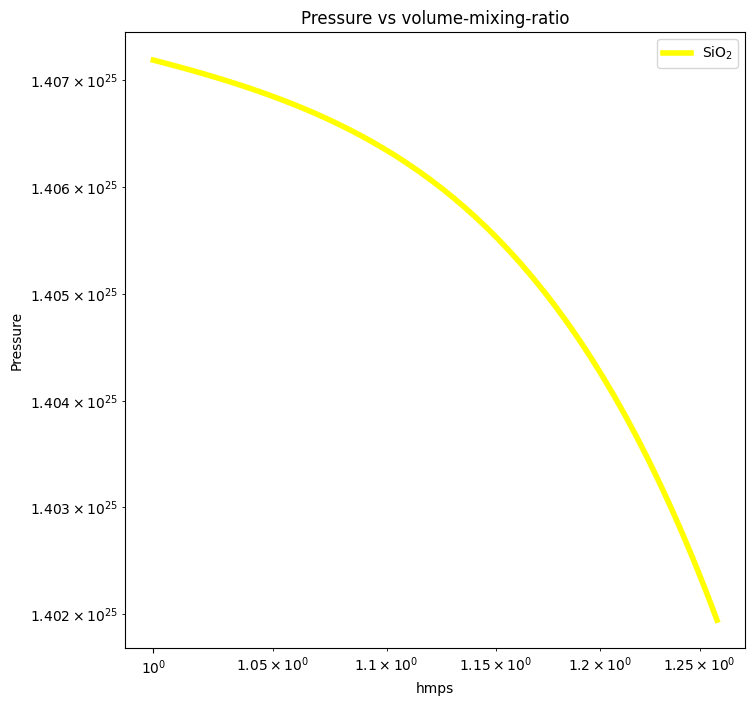

-2.1
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-2.1.xlsx


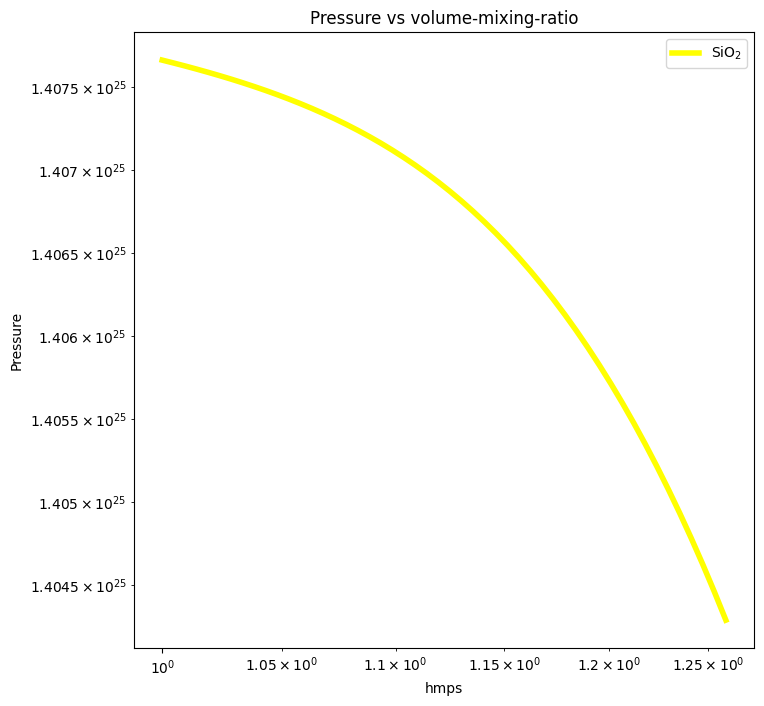

-1.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-1.8.xlsx


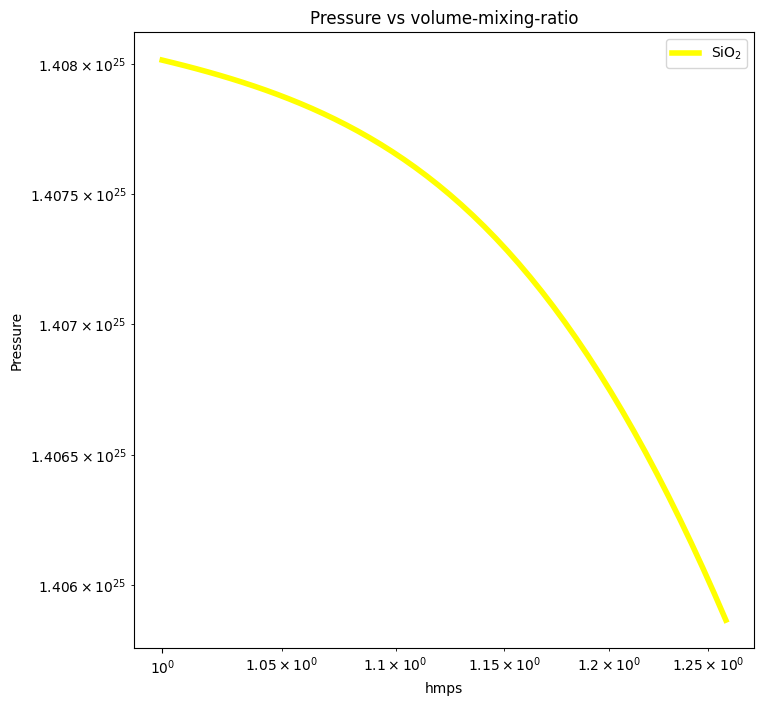

-1.6
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-1.6.xlsx


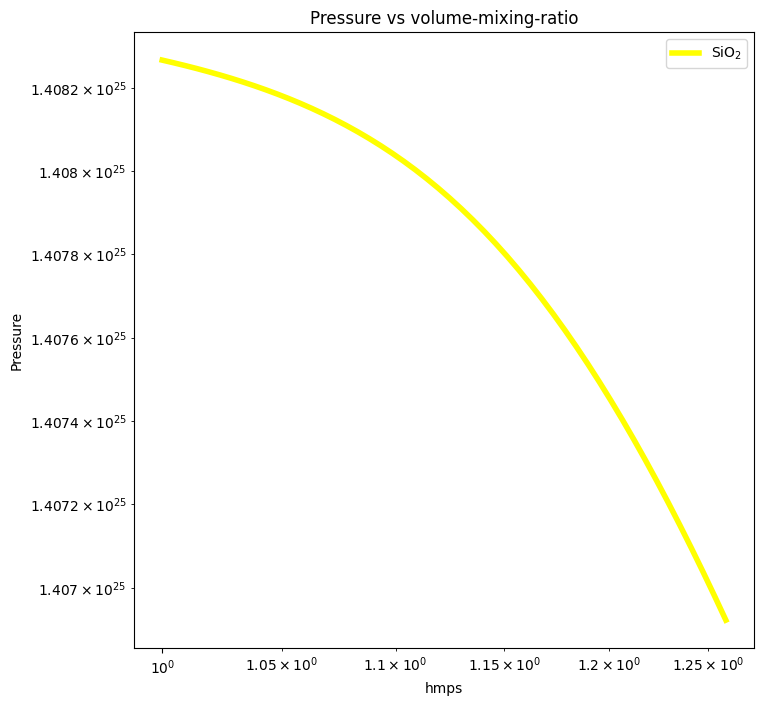

-1.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-1.3.xlsx


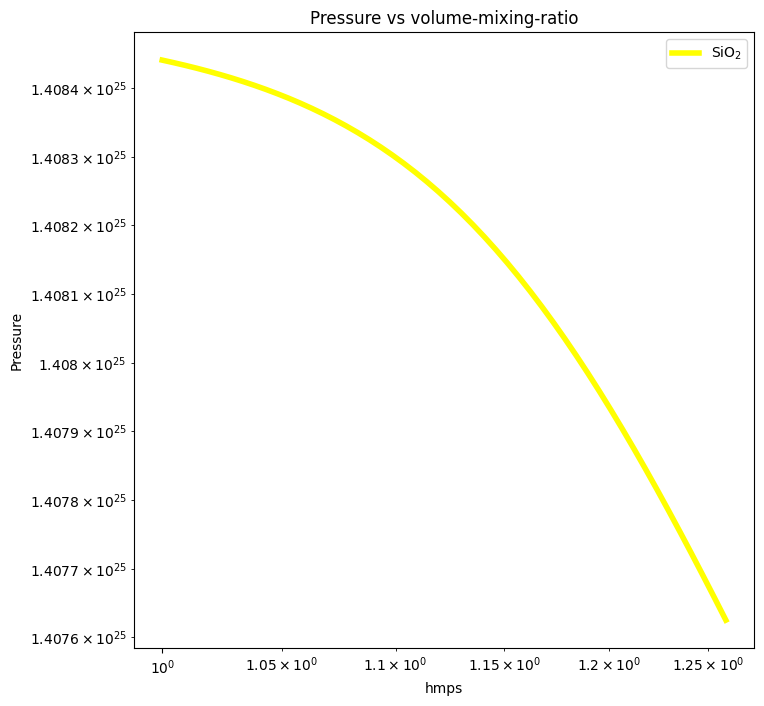

-1.1
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-1.1.xlsx


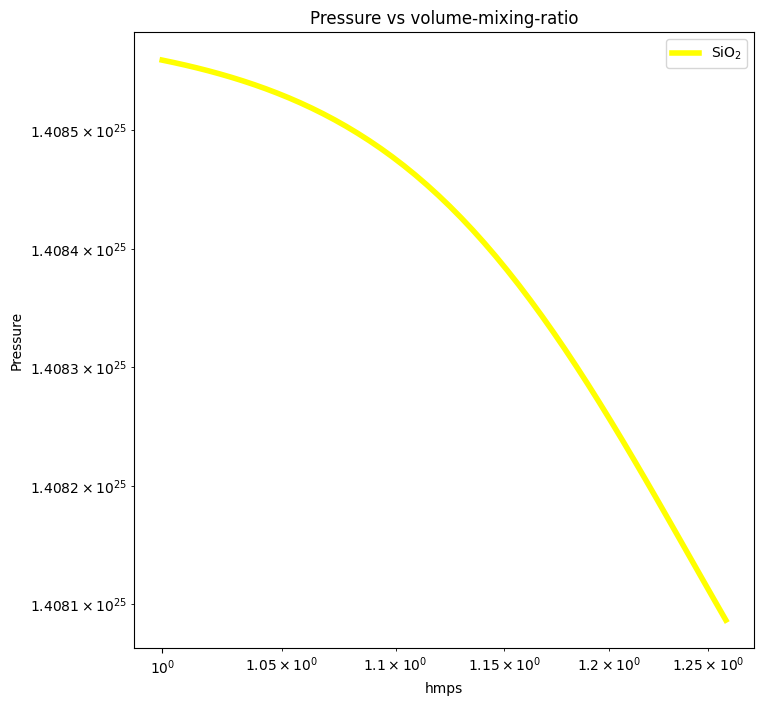

-0.86
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-0.86.xlsx


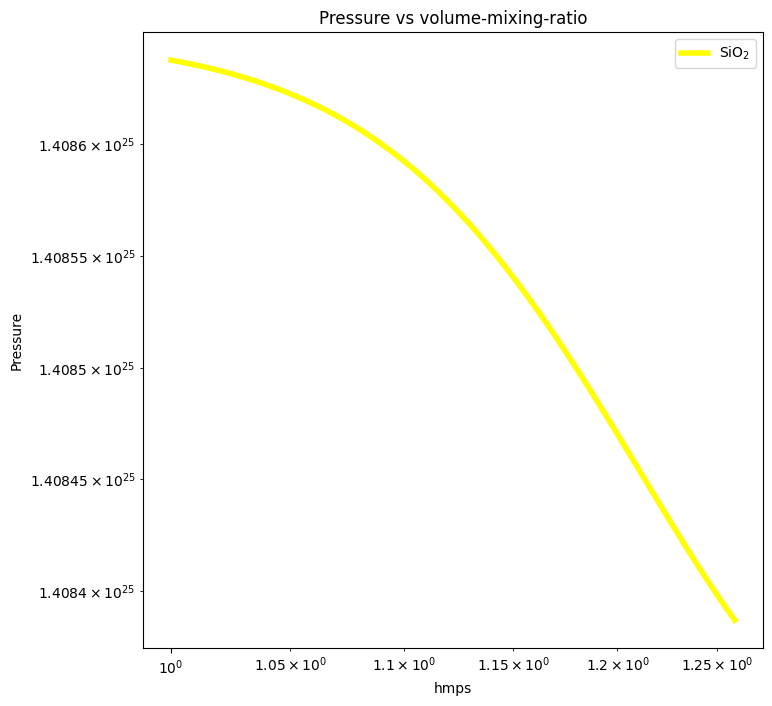

-0.61
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-0.61.xlsx


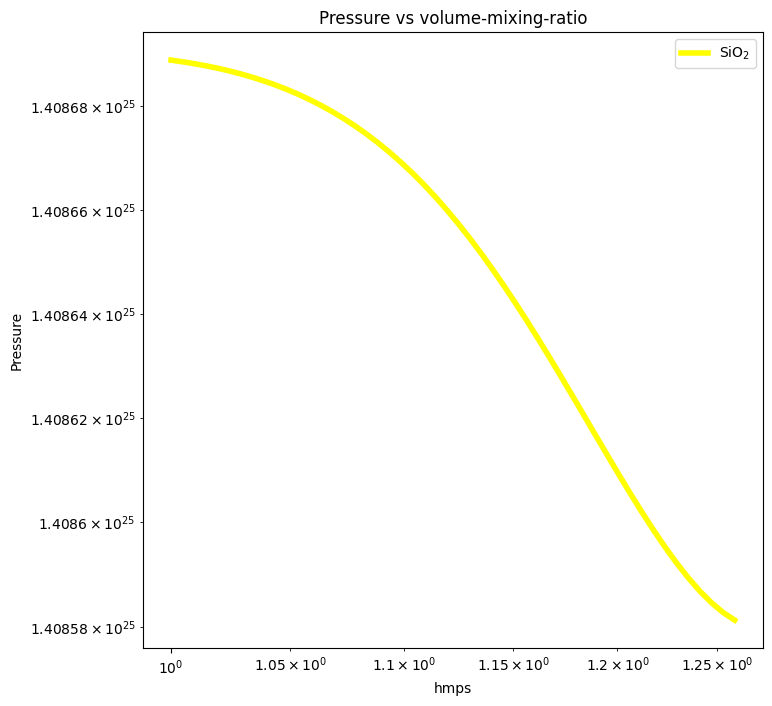

-0.37
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-0.37.xlsx


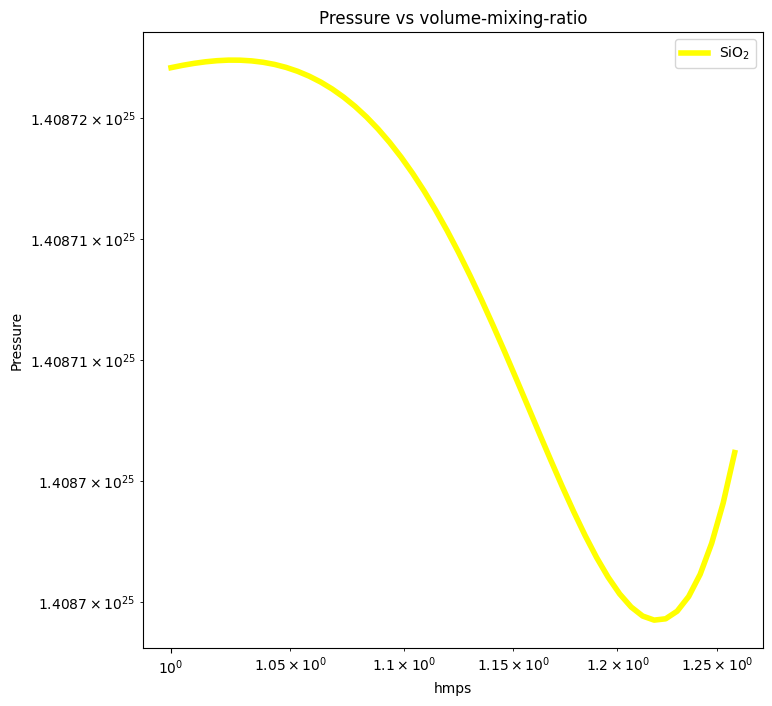

-0.12
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO2-0.12.xlsx


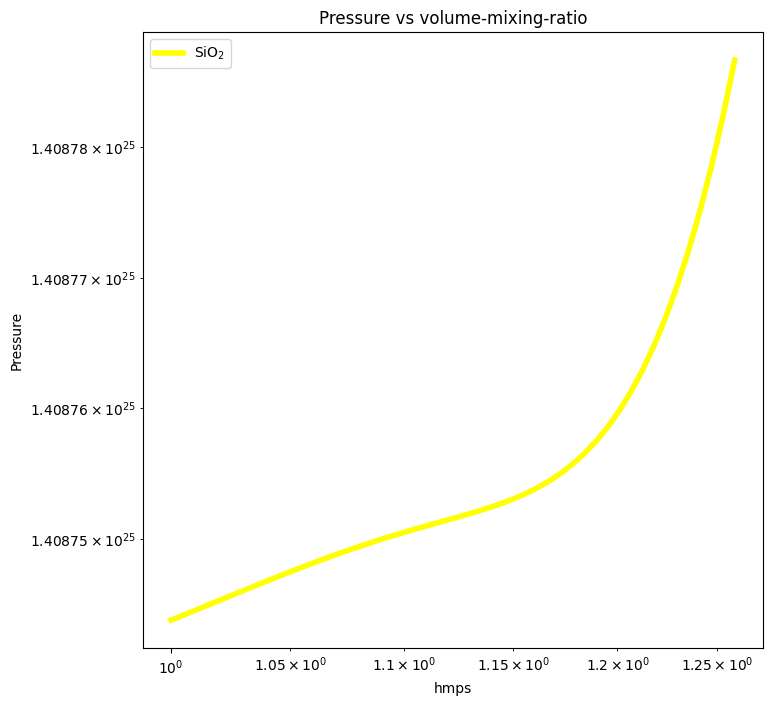

0.12
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO20.12.xlsx


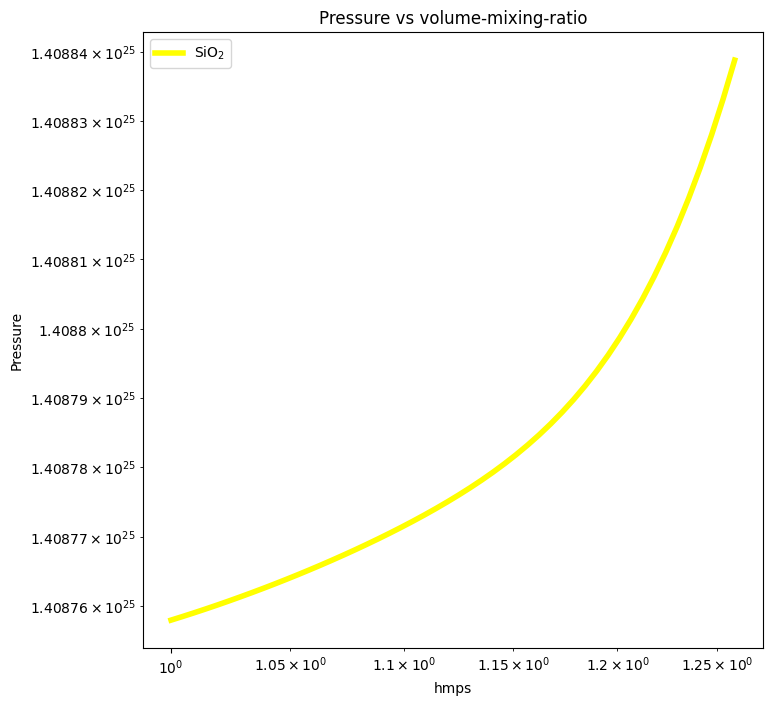

0.37
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO20.37.xlsx


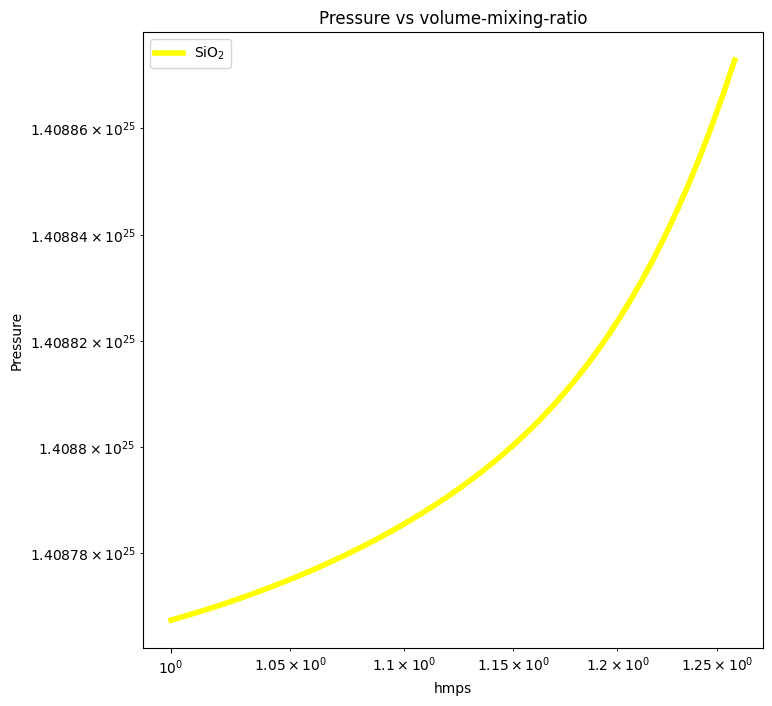

0.61
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO20.61.xlsx


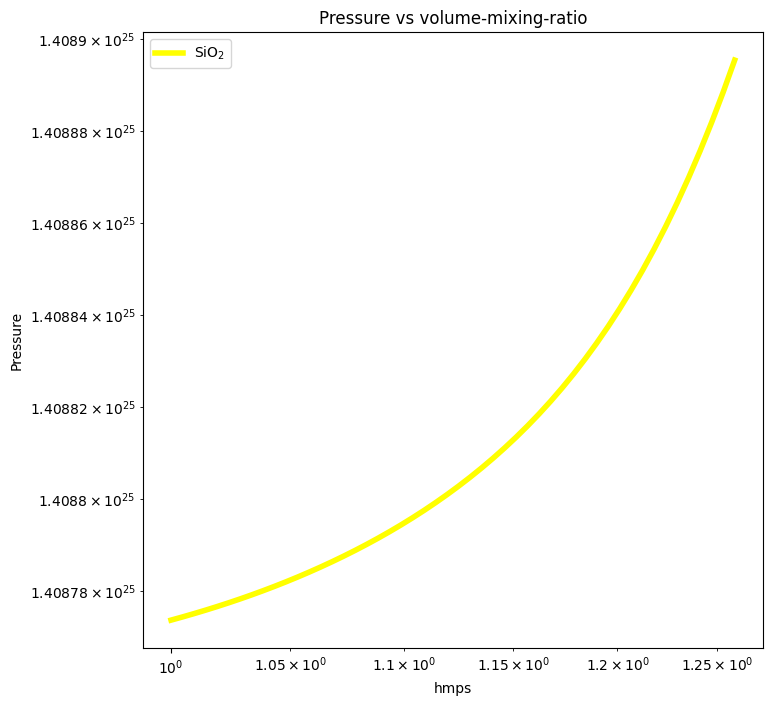

0.86
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO20.86.xlsx


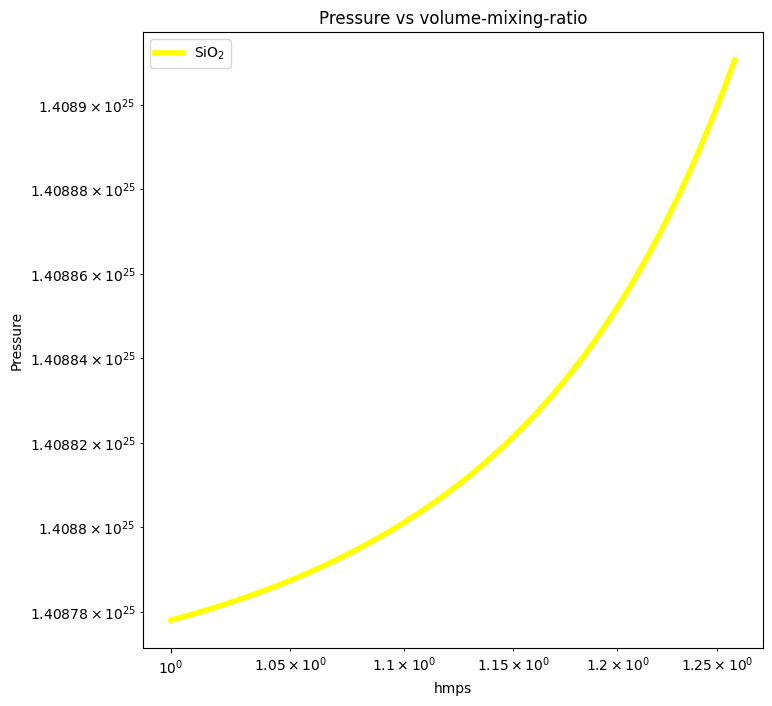

1.1
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO21.1.xlsx


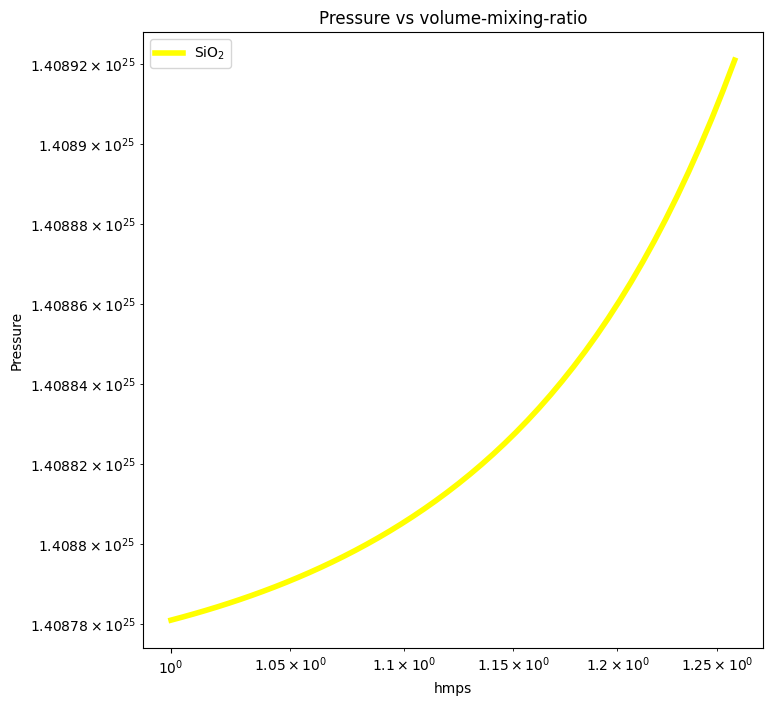

1.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO21.3.xlsx


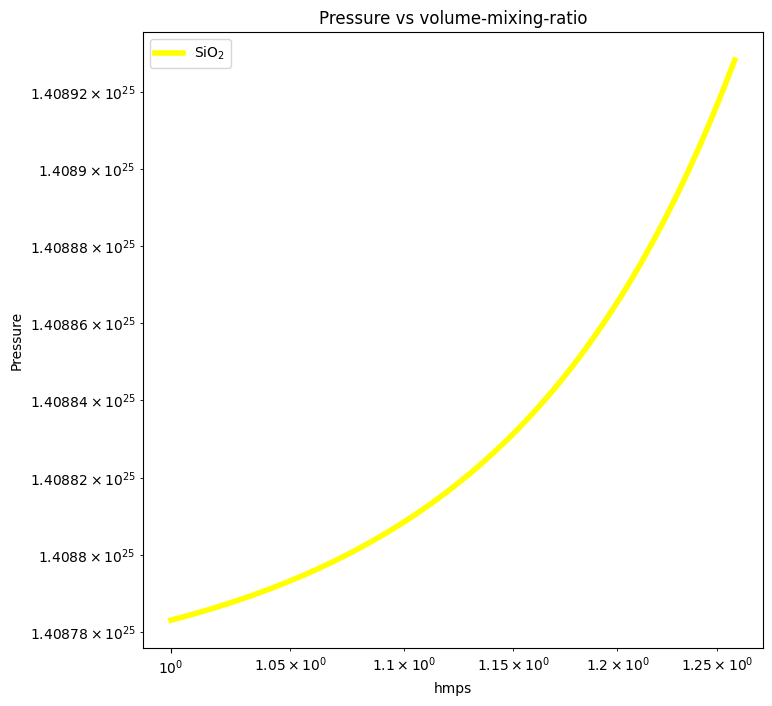

1.6
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO21.6.xlsx


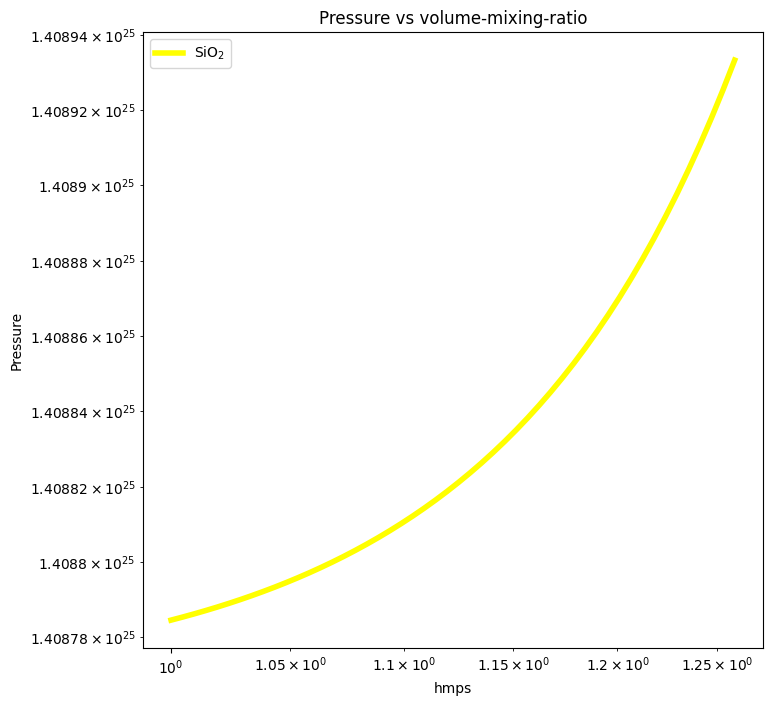

1.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO21.8.xlsx


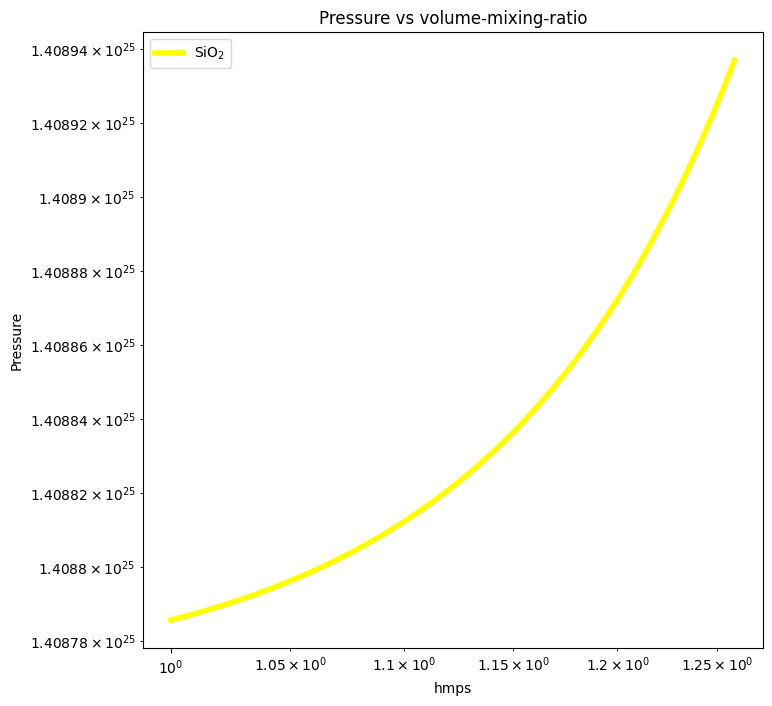

2.1
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO22.1.xlsx


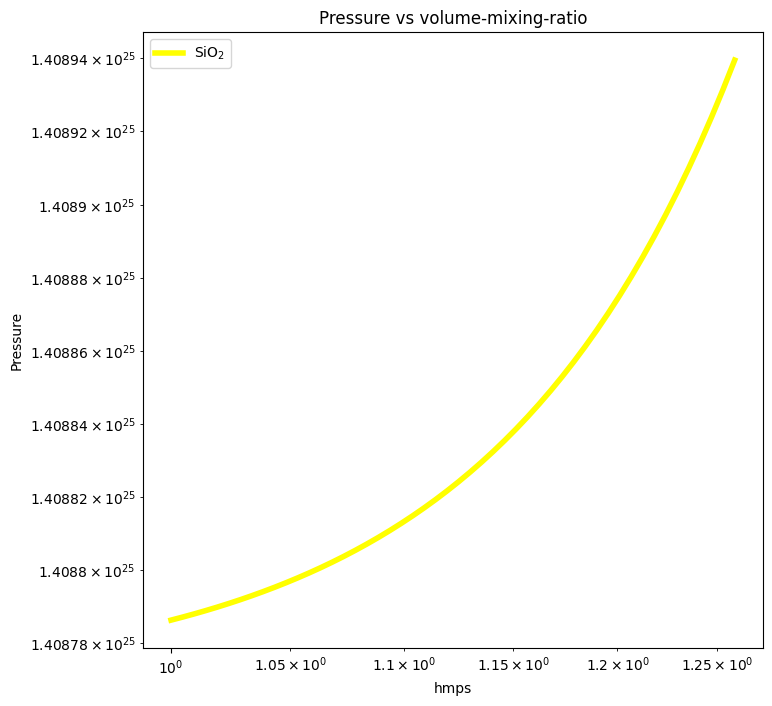

2.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO22.3.xlsx


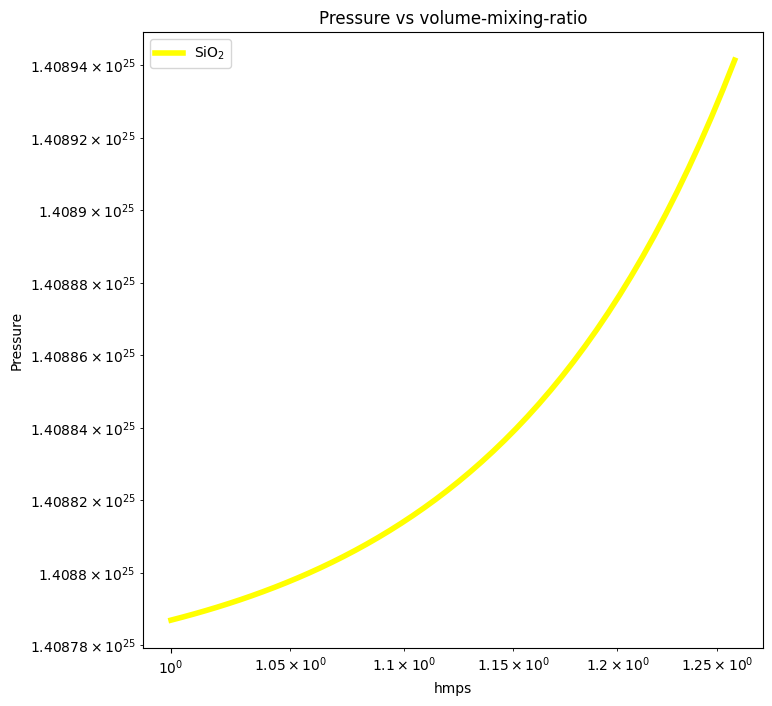

2.6
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO22.6.xlsx


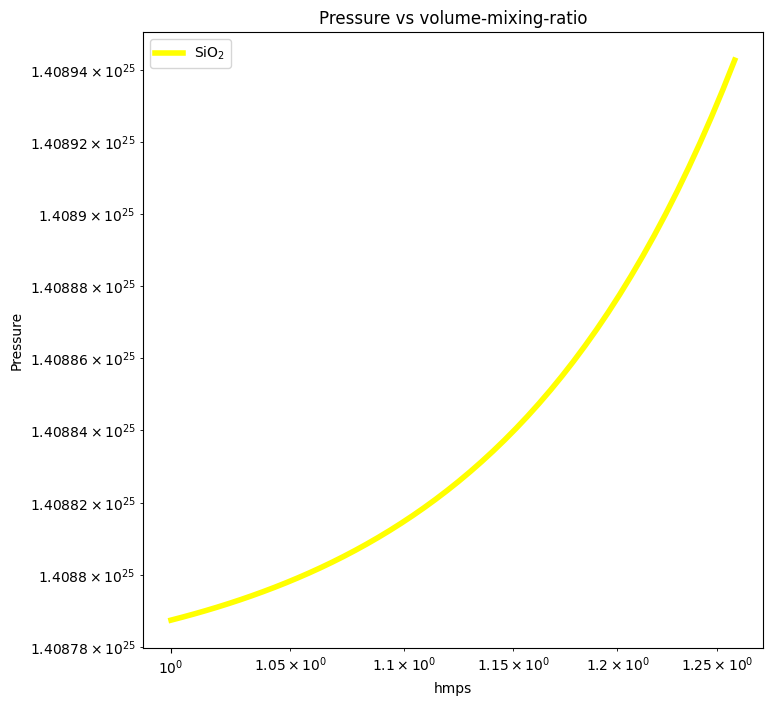

2.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO22.8.xlsx


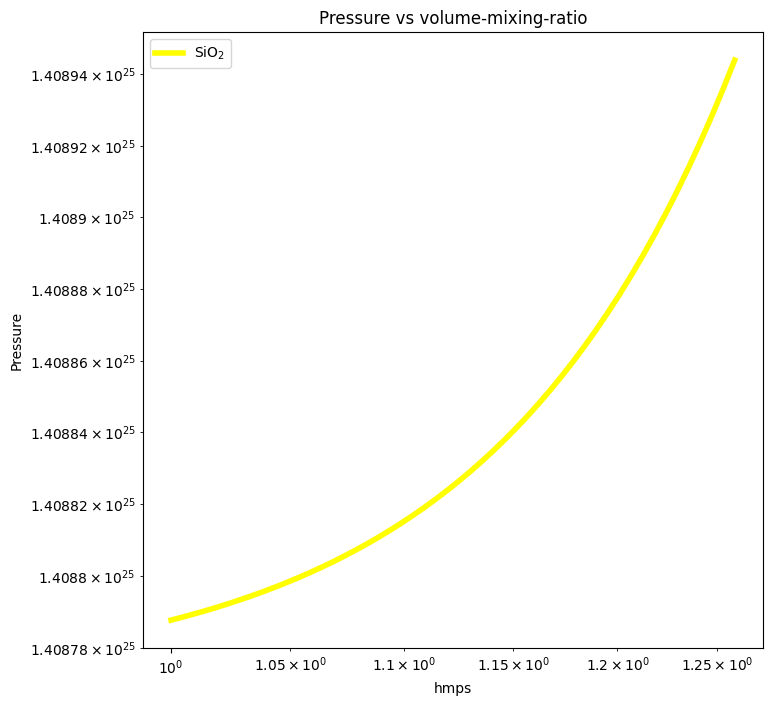

3.1
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO23.1.xlsx


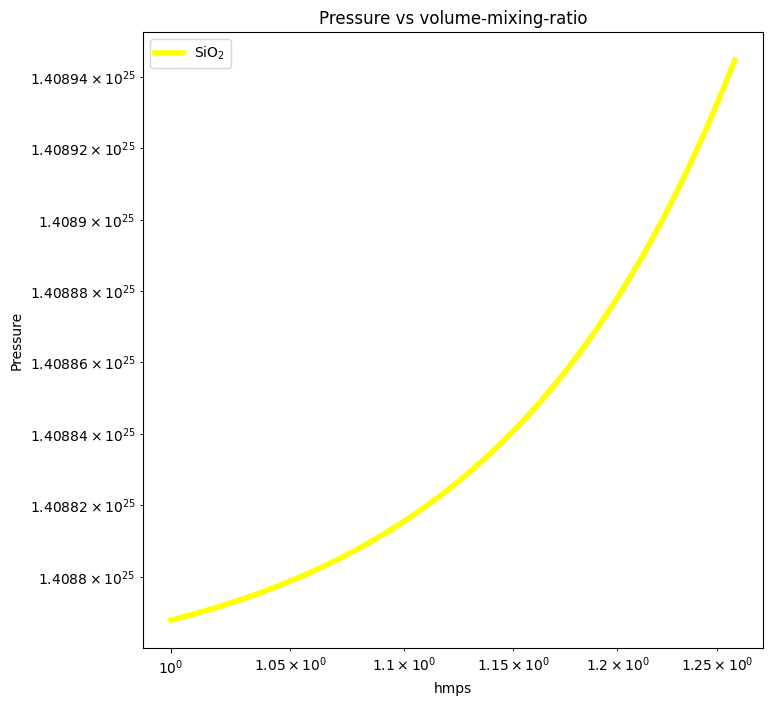

3.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO23.3.xlsx


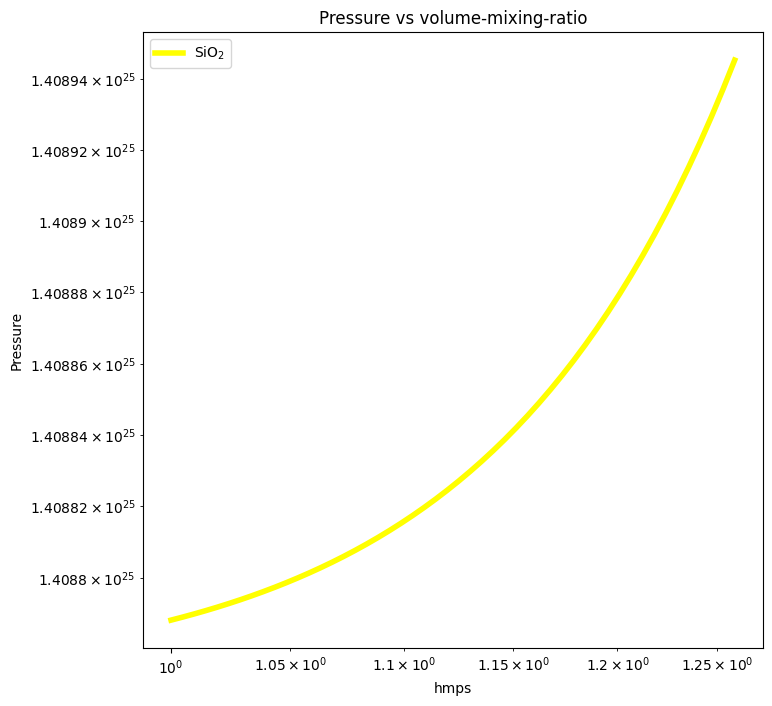

3.6
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO23.6.xlsx


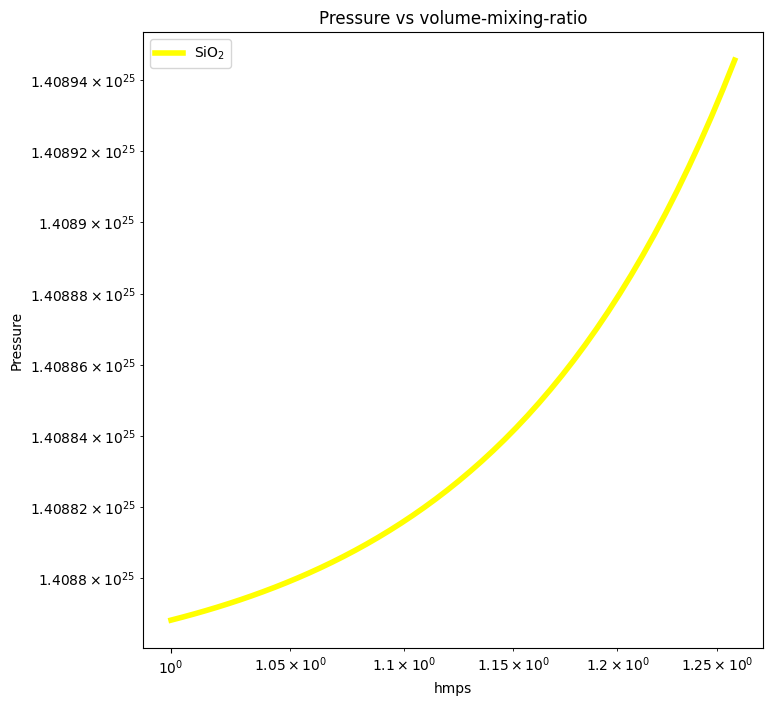

3.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO23.8.xlsx


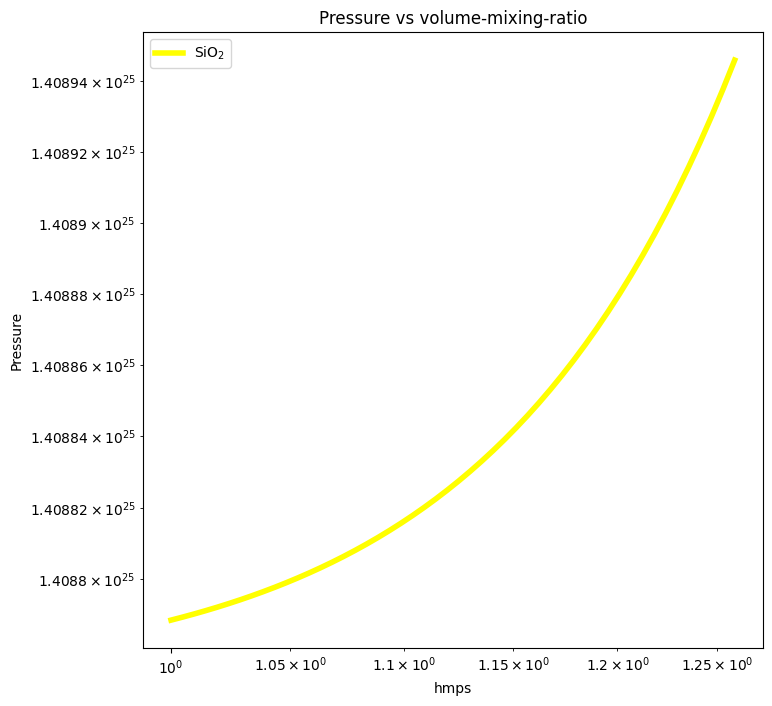

4
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO24.xlsx


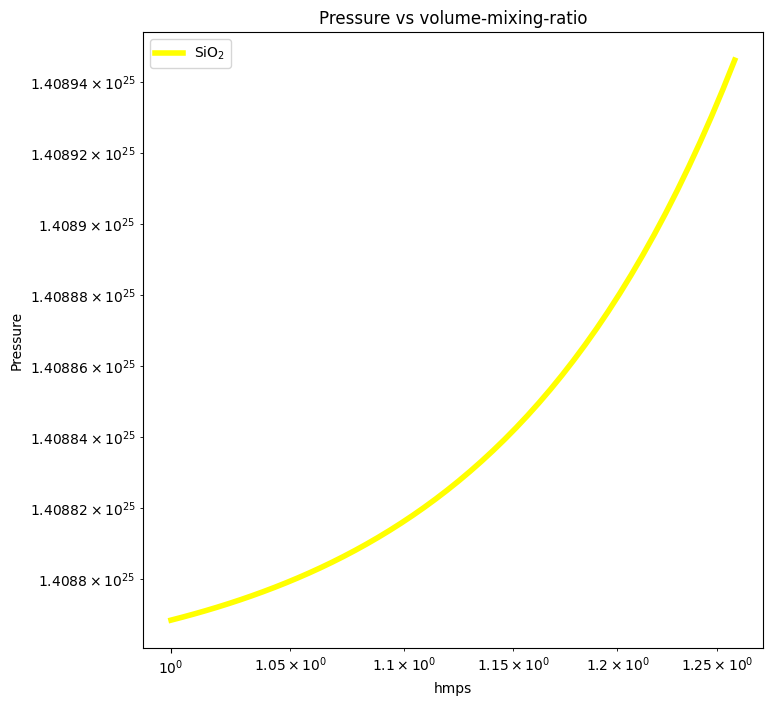

4.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO24.3.xlsx


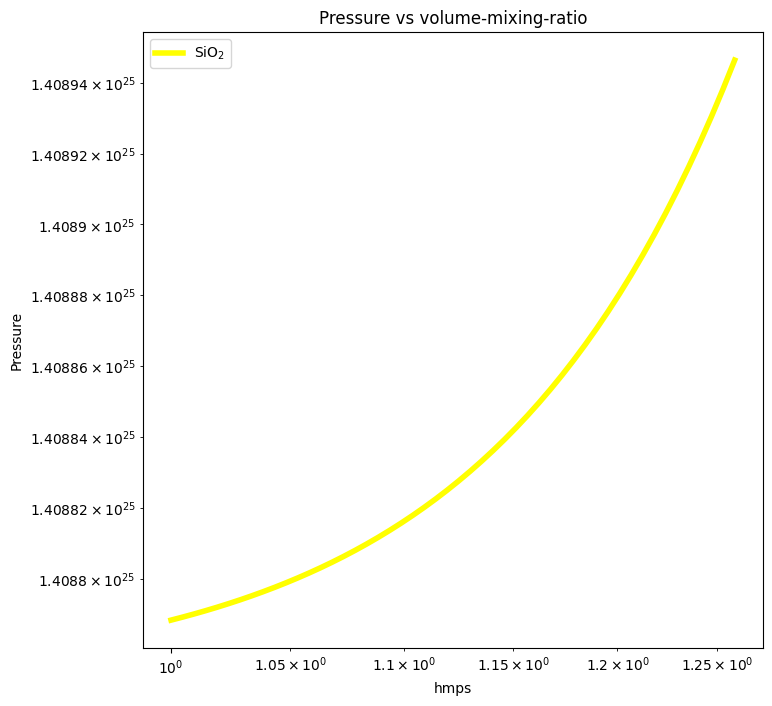

4.5
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO24.5.xlsx


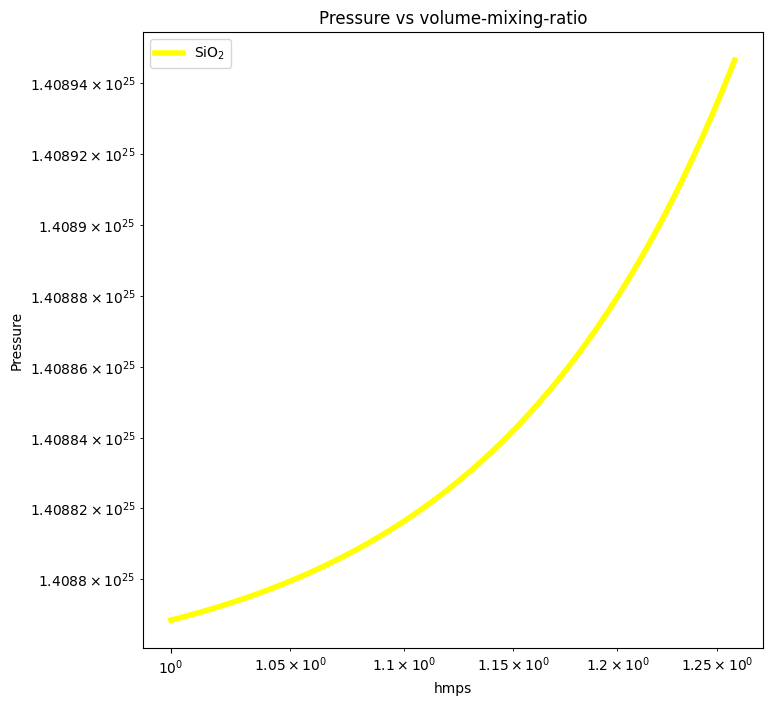

4.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO24.8.xlsx


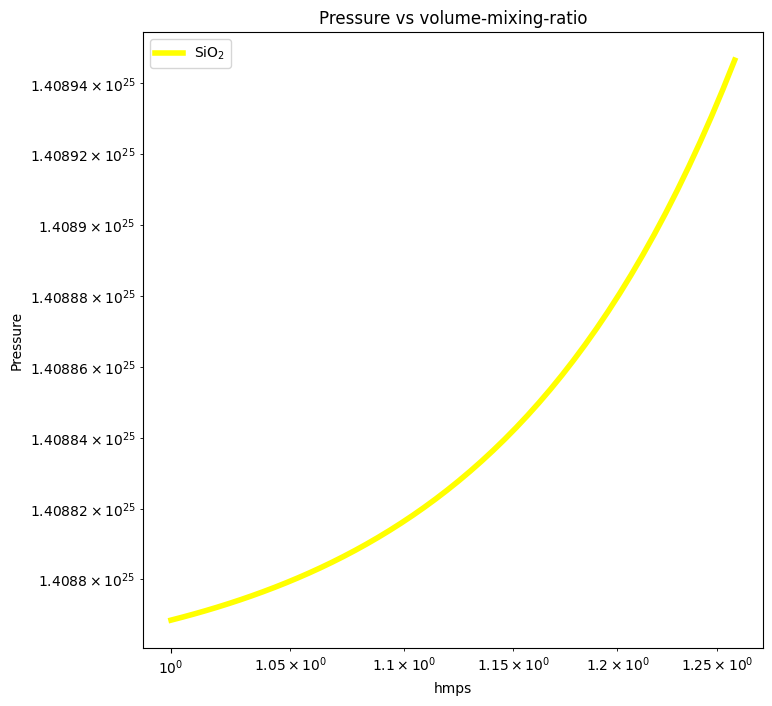

5
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO25.xlsx


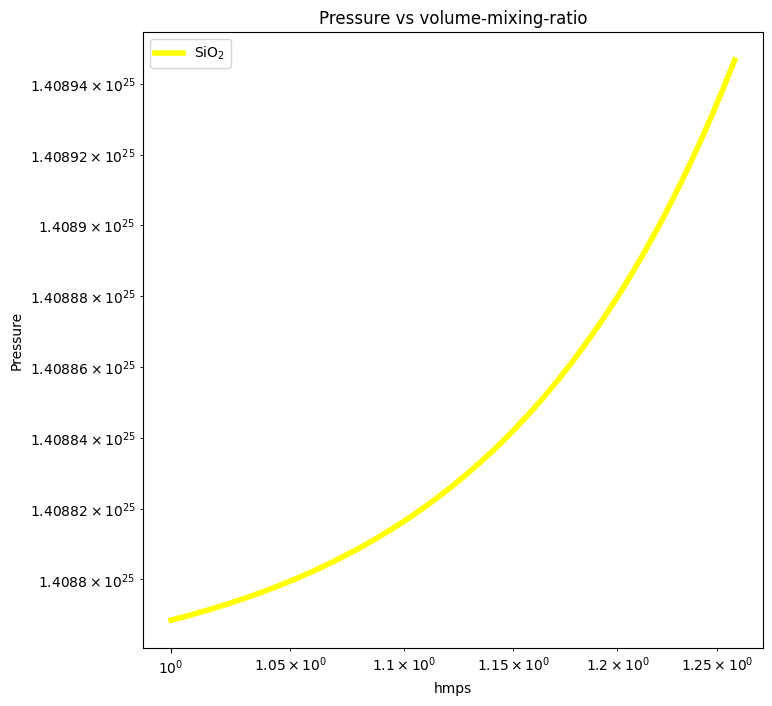

5.3
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO25.3.xlsx


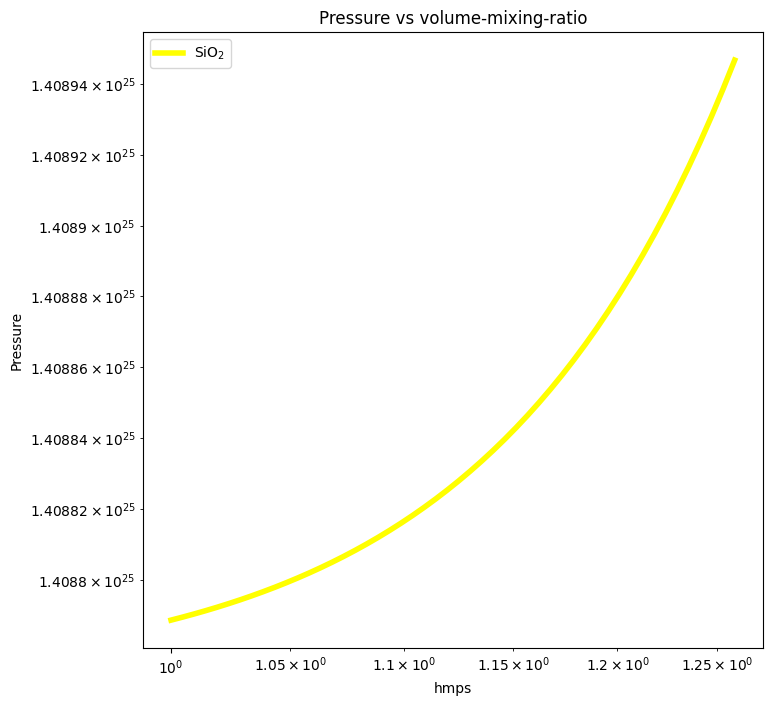

5.5
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO25.5.xlsx


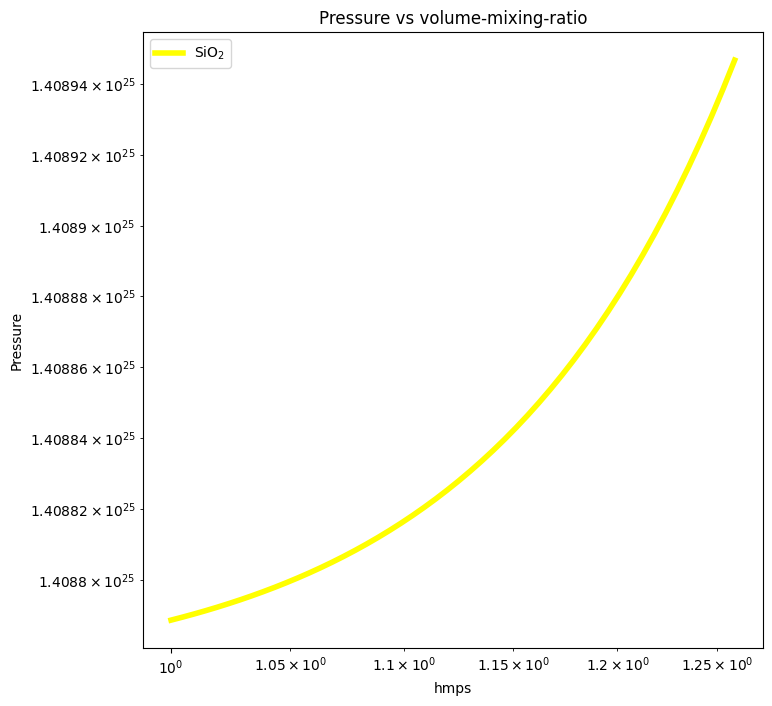

5.8
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO25.8.xlsx


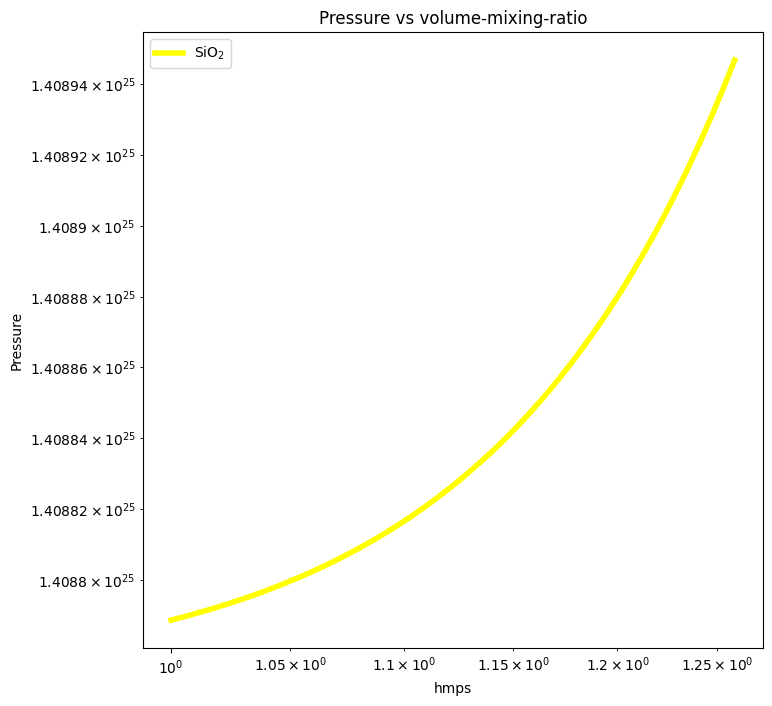

6
./excel_Uranus_solar_3000K/HOSi_magma_sol_real_1xsolar_melt100_fO26.xlsx


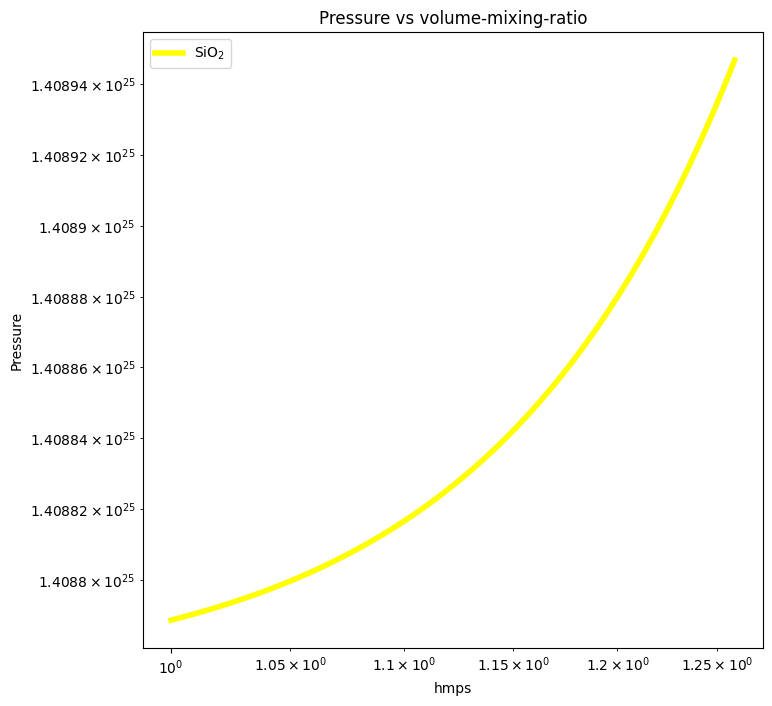

In [19]:
init_metallicity = 1
mantle_melt_fraction = 1

fO2_log10_shifts = np.linspace(-6, 6, number_of_realisations) 
for fO2_log10_shift in fO2_log10_shifts:
    shift = f"{fO2_log10_shift:.2g}"
    print(shift)
    filename = f"./excel_Uranus_solar_3000K/HOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}.xlsx"
    print(filename)
    # Pressures
    H2O_mass = pd.read_excel(filename, sheet_name="H2O_g")["total_mass"]
    H2_mass = pd.read_excel(filename, sheet_name="H2_g")["total_mass"]
    O2_mass = pd.read_excel(filename, sheet_name="O2_g")["total_mass"]
    SiO_mass = pd.read_excel(filename, sheet_name="OSi_g")["total_mass"]
    SiH4_mass = pd.read_excel(filename, sheet_name="H4Si_g")["total_mass"]
    O2Si_mass = pd.read_excel(filename, sheet_name="O2Si_cd")["total_mass"]
    tot_mass = pd.read_excel(filename, sheet_name="state")["mantle_melt_mass"]

    fig, ax = plt.subplots(figsize=(8, 8))
#    ax.plot(hmps,H2O_mass, color=color_H2O, lw=4, ls="-", label="H$_2$O")
#    ax.plot(hmps,H2_mass, color=color_H2, lw=4, ls="-", label="H$_2$")
#    ax.plot(hmps,O2_mass, color=color_O2, lw=4, ls="-", label="O$_2$")
#    ax.plot(hmps,SiO_mass, color=color_SiO, lw=4, ls="-", label="SiO")
#    ax.plot(hmps,SiH4_mass, color=color_SiH4, lw=4, ls="-", label="SiH$_4$")
    ax.plot(hmps,O2Si_mass, color=color_SiO2, lw=4, ls="-", label="SiO$_2$")

    # Set labels and title
    ax.set_xlabel('hmps')
    ax.set_ylabel('Pressure')
    ax.set_title('Pressure vs volume-mixing-ratio')
    ax.set_yscale('log') 
    ax.set_xscale('log') 
    # Add a legend
    ax.legend()

    # Show the plot
    plt.show()
    plt.close
#fig.savefig(f"images_U2/pressure_volume_mixing_ratio/HHeCNOSi_magma_sol_real_{init_metallicity}_temp_{atmosphere_temperature}_pressure_volume_mixing_ratio.png", dpi=300, bbox_inches="tight")


# Pressure - Temperature profiles

In [7]:
#Guillot 2010, computing equation

f = 1/4

T_solar = 5772
R_solar = 6.957e8
d_solar_Uranus = 2876679082000

T_irr = T_solar * np.sqrt(R_solar/d_solar_Uranus)
print(T_irr)

T_eff = 59.1 #pm 0.3 The albedo, effective temperature, and energy balance of Uranus, as determined from Voyager IRIS data
T_eq = 58.2 #pm 1 The albedo, effective temperature, and energy balance of Uranus, as determined from Voyager IRIS data
T_int = (T_eff**(4) - T_eq**(4))**(1/4)
print(T_int)

gamma_1 = 0.01
gamma_2 = 0.05
gamma_3 = 0.1
gammas = np.logspace(-4,2,7)
print(gammas)

89.76181312145127
29.19328916037848
[1.e-04 1.e-03 1.e-02 1.e-01 1.e+00 1.e+01 1.e+02]


In [118]:
tau = np.logspace(-10,10,1000)
T_new_1 = (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma_1*np.sqrt(3))) + ((gamma_1/(np.sqrt(3)))- (1/(gamma_1*np.sqrt(3))))*np.exp(-gamma_1*tau*np.sqrt(3))))**(1/4)
T_new_2 = (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma_2*np.sqrt(3))) + ((gamma_2/(np.sqrt(3)))- (1/(gamma_2*np.sqrt(3))))*np.exp(-gamma_2*tau*np.sqrt(3))))**(1/4)
T_new_3 = (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma_3*np.sqrt(3))) + ((gamma_3/(np.sqrt(3)))- (1/(gamma_3*np.sqrt(3))))*np.exp(-gamma_3*tau*np.sqrt(3))))**(1/4)

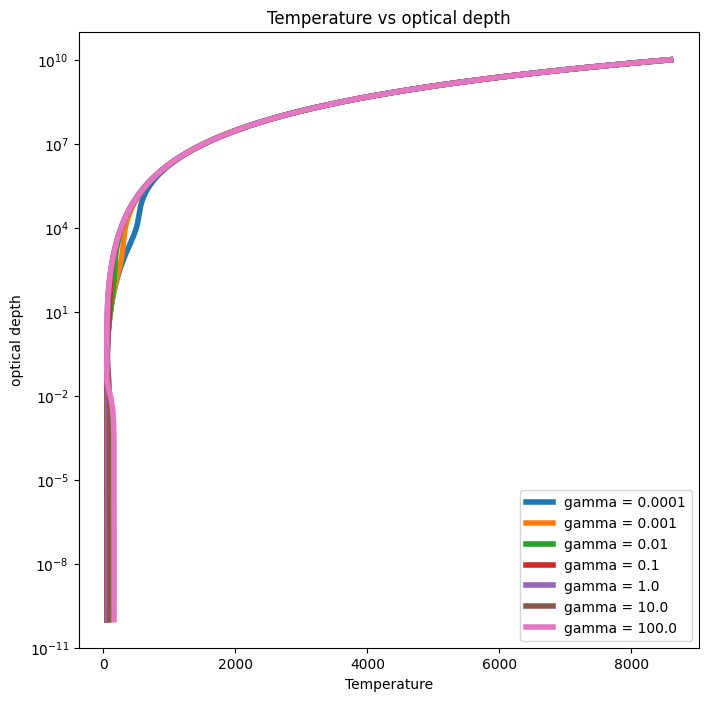

<function matplotlib.pyplot.close(fig: "None | int | str | Figure | Literal['all']" = None) -> 'None'>

In [49]:
fig, ax = plt.subplots(figsize=(8, 8))

for gamma in gammas:
    T_new = (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma*np.sqrt(3))) + ((gamma/(np.sqrt(3)))- (1/(gamma*np.sqrt(3))))*np.exp(-gamma*tau*np.sqrt(3))))**(1/4)
    ax.plot(T_new, tau, lw=4, ls="-", label=f"gamma = {gamma}")
# Set labels and title
ax.set_xlabel('Temperature')
ax.set_ylabel('optical depth')
ax.set_title('Temperature vs optical depth')
ax.set_yscale('log') 
# Add a legend
ax.legend()

# Show the plot
plt.show()
plt.close

In [55]:
G = 6.6743e-11
grav = G*M_core/(R_core**2)
print(grav)
grav_U = G*M_uranus/(R_uranus**2)
print(grav_U)

14.733543632885192
9.199903357607555


In [28]:
from scipy.optimize import fsolve, root_scalar
def Temp_profile(tau):
        return (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma*np.sqrt(3))) + ((gamma/(np.sqrt(3)))- (1/(gamma*np.sqrt(3))))*np.exp(-gamma*tau*np.sqrt(3))))**(1/4)  # Example function

def find_tau(tau, target, initial_guess):
    # Define your function
    def Temp_profile(tau):
        return (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma*np.sqrt(3))) + ((gamma/(np.sqrt(3)))- (1/(gamma*np.sqrt(3))))*np.exp(-gamma*tau*np.sqrt(3))))**(1/4)  # Example function


    # To solve f(x) = target, define g(x) = f(x) - target
    def g(tau):
        return Temp_profile(tau) - target

    # Method 1a: Using fsolve
    x_solution = fsolve(g, initial_guess)
#    print(f"Solution: tau = {x_solution[0]}")
#    print(f"T = {Temp_profile(x_solution[0])}")

    # Method 1b: Using root_scalar (often more robust)
    try:
        solution = root_scalar(g, bracket=[0.5*initial_guess, 2*initial_guess])  # Need interval with sign change
#        print(f"Solution: tau = {solution.root}")
#        print(f"T = {Temp_profile(solution.root)}")
    except ValueError:
        print("Couldn't find a solution in that interval")
    return x_solution[0]
print(find_tau(tau,3000, 10e7))

148693108.42030606


In [93]:
for gamma in gammas:
    find_tau(tau,3000)

In [94]:
for gamma in gammas:
    find_tau(tau,3000)

mantle_melt_fraction = 1
init_metallicitys = [1]
scale_factors = []
fO2_log10_shifts = np.linspace(-6, 6, 50) 
init_metallicity = 1
for fO2_log10_shift in fO2_log10_shifts:
    shift = f"{fO2_log10_shift:.2g}"
    filename = f"./excel_Uranus_solar_3000K/HOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}.xlsx"
    Pressure = pd.read_excel(filename, sheet_name="state")["pressure"]
    scale_factor = Pressure/find_tau(tau,3000)
    scale_factors.append(scale_factor.iloc[-1])
    scale_factors.append(scale_factor.iloc[0])


In [82]:
print(min(scale_factors))
print(max(scale_factors))

7.643169228221862e-06
0.0005916229615478132


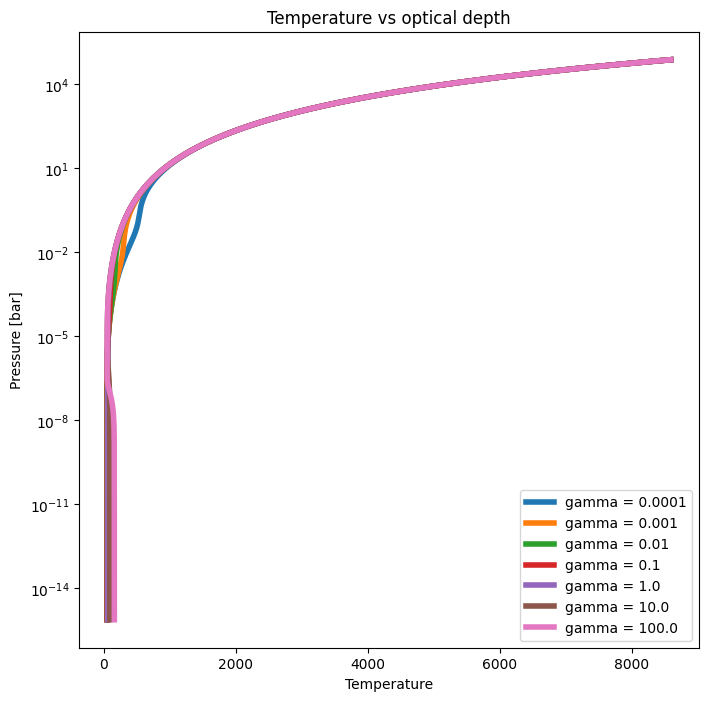

<function matplotlib.pyplot.close(fig: "None | int | str | Figure | Literal['all']" = None) -> 'None'>

In [87]:
fig, ax = plt.subplots(figsize=(8, 8))
for gamma in gammas:
    T_new = (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma*np.sqrt(3))) + ((gamma/(np.sqrt(3)))- (1/(gamma*np.sqrt(3))))*np.exp(-gamma*tau*np.sqrt(3))))**(1/4)
    ax.plot(T_new, min(scale_factors)*tau, lw=4, ls="-", label=f"gamma = {gamma}")
# Set labels and title
ax.set_xlabel('Temperature')
ax.set_ylabel('Pressure [bar]')
ax.set_title('Temperature vs optical depth')
ax.set_yscale('log') 
# Add a legend
ax.legend()

# Show the plot
plt.show()
plt.close

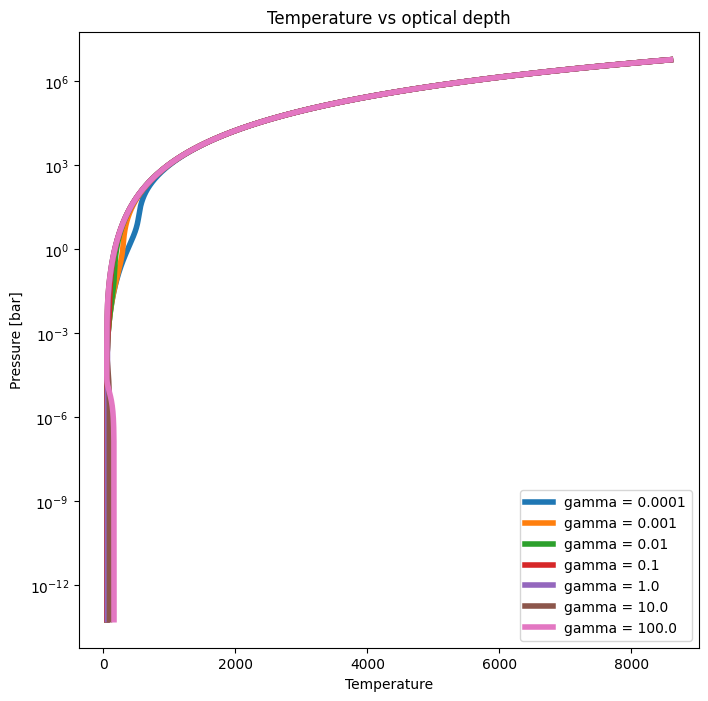

<function matplotlib.pyplot.close(fig: "None | int | str | Figure | Literal['all']" = None) -> 'None'>

In [88]:
fig, ax = plt.subplots(figsize=(8, 8))
for gamma in gammas:
    T_new = (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma*np.sqrt(3))) + ((gamma/(np.sqrt(3)))- (1/(gamma*np.sqrt(3))))*np.exp(-gamma*tau*np.sqrt(3))))**(1/4)
    ax.plot(T_new, max(scale_factors)*tau, lw=4, ls="-", label=f"gamma = {gamma}")
# Set labels and title
ax.set_xlabel('Temperature')
ax.set_ylabel('Pressure [bar]')
ax.set_title('Temperature vs optical depth')
ax.set_yscale('log') 
# Add a legend
ax.legend()

# Show the plot
plt.show()
plt.close

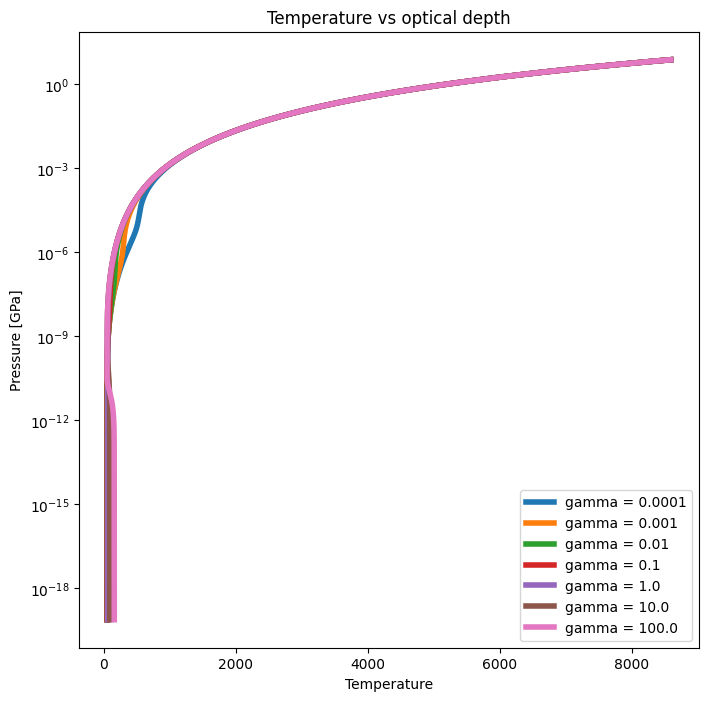

<function matplotlib.pyplot.close(fig: "None | int | str | Figure | Literal['all']" = None) -> 'None'>

In [90]:
fig, ax = plt.subplots(figsize=(8, 8))
for gamma in gammas:
    T_new = (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma*np.sqrt(3))) + ((gamma/(np.sqrt(3)))- (1/(gamma*np.sqrt(3))))*np.exp(-gamma*tau*np.sqrt(3))))**(1/4)
    ax.plot(T_new, min(scale_factors)*tau*10**(-4), lw=4, ls="-", label=f"gamma = {gamma}")
# Set labels and title
ax.set_xlabel('Temperature')
ax.set_ylabel('Pressure [GPa]')
ax.set_title('Temperature vs optical depth')
ax.set_yscale('log') 
# Add a legend
ax.legend()

# Show the plot
plt.show()
plt.close

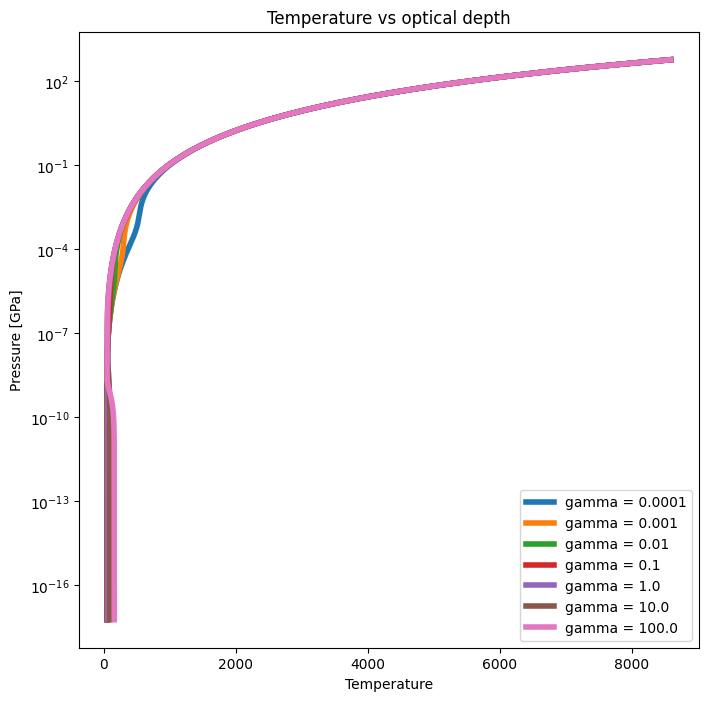

<function matplotlib.pyplot.close(fig: "None | int | str | Figure | Literal['all']" = None) -> 'None'>

In [91]:
fig, ax = plt.subplots(figsize=(8, 8))
for gamma in gammas:
    T_new = (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma*np.sqrt(3))) + ((gamma/(np.sqrt(3)))- (1/(gamma*np.sqrt(3))))*np.exp(-gamma*tau*np.sqrt(3))))**(1/4)
    ax.plot(T_new, max(scale_factors)*tau*10**(-4), lw=4, ls="-", label=f"gamma = {gamma}")
# Set labels and title
ax.set_xlabel('Temperature')
ax.set_ylabel('Pressure [GPa]')
ax.set_title('Temperature vs optical depth')
ax.set_yscale('log') 
# Add a legend
ax.legend()

# Show the plot
plt.show()
plt.close

In [102]:
print(find_tau(tau,2000, 1e7))

Couldn't find a solution in that interval
29371516.554325372


In [106]:
print(max(scale_factors)*find_tau(tau,1000, 1e4)*10**(-4))
print(min(scale_factors)*find_tau(tau,1000, 1e4)*10**(-4))

Couldn't find a solution in that interval
0.10860452719758149
Couldn't find a solution in that interval
0.0014030604528101202


In [109]:
print(max(scale_factors)*find_tau(tau,1000, 1e4))
print(min(scale_factors)*find_tau(tau,1000, 1e4))

Couldn't find a solution in that interval
1086.0452719758148
Couldn't find a solution in that interval
14.0306045281012


In [115]:
import numpy as np

def create_phase_lookup(filename):
    """
    Create a simple phase lookup function
    """
    # Load data
    data = []
    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                vals = line.split()
                float(vals[0])  # Test if numeric
                data.append([float(x) for x in vals[:11]])
            except (ValueError, IndexError):
                continue
    
    data = np.array(data)
    
    # Phase names
    phase_names = {
        -1: "Ice Ih", -2: "Ice II", -3: "Ice III",
        -5: "Ice V", -6: "Ice VI", -7: "Ice VII",
        3: "Vapor", 4: "Liquid", 5: "Supercritical"
    }
    
    # Extract columns
    temps = data[:, 1]      # Temperature in K
    press = data[:, 0] / 1e9  # Pressure in GPa
    phases = data[:, 10]     # Phase ID
    
    def lookup(T, P):
        """Return phase name at T(K) and P(GPa)"""
        # Find closest point
        distances = (temps - T)**2 + (press - P)**2
        idx = np.argmin(distances)
        phase_id = int(phases[idx])
        return phase_names.get(phase_id, f"Phase {phase_id}")
    
    return lookup

# Create the lookup function
filename = '/home/mathias/H2Oeq/AQUA/Tables/aqua_eos_pt_v1_0.dat'
get_phase = create_phase_lookup(filename)

# Use it!
print(get_phase(300, 0.001))    # Should return ice or vapor
print(get_phase(4000, 100))     # Should return supercritical

Liquid
Supercritical


In [116]:
import numpy as np
import pandas as pd

def read_aqua_simple(filename):
    """
    Read AQUA data file, skipping header lines that start with text
    """
    data = []
    line_count = 0
    skipped_count = 0
    
    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            line_count += 1
            
            # Skip empty lines
            if not line:
                continue
            
            # Try to convert to float - if it fails, skip the line
            try:
                # Split and try to convert first element to float
                vals = line.split()
                if vals:  # Check if line has content
                    float(vals[0])  # Test if first value is a number
                    # If successful, convert all values to float
                    data.append([float(x) for x in vals[:11]])
            except ValueError:
                # This line contains text - skip it
                skipped_count += 1
                continue
    
    print(f"Read {line_count} total lines")
    print(f"Skipped {skipped_count} header/comment lines")
    print(f"Loaded {len(data)} data points")
    
    if len(data) == 0:
        raise ValueError("No data points were loaded! Check file format.")
    
    # Convert to DataFrame
    df = pd.DataFrame(data, columns=[
        'press_Pa', 'temp_K', 'rho', 'ad_grad', 's', 'u', 
        'c', 'mmw', 'x_ion', 'x_d', 'phase_id'
    ])
    
    # Convert pressure to GPa for convenience
    df['press_GPa'] = df['press_Pa'] / 1e9
    
    # Ensure phase_id is integer
    df['phase_id'] = df['phase_id'].astype(int)
    
    # Phase names mapping
    phase_names = {
        -1: "Ice Ih",
        -2: "Ice II",
        -3: "Ice III",
        -5: "Ice V",
        -6: "Ice VI",
        -7: "Ice VII",
        -10: "Ice X",
        3: "Vapor",
        4: "Liquid",
        5: "Supercritical/Superionic"
    }
    
    def get_phase(T, P):
        """Get phase at temperature T(K) and pressure P(GPa)"""
        # Find closest point
        distances = np.sqrt(
            (df['temp_K'] - T)**2 + 
            (df['press_GPa'] - P)**2
        )
        idx = distances.idxmin()
        pid = df.loc[idx, 'phase_id']
        
        # Also return density and actual T,P for verification
        actual_T = df.loc[idx, 'temp_K']
        actual_P = df.loc[idx, 'press_GPa']
        density = df.loc[idx, 'rho']
        
        phase_name = phase_names.get(pid, f"Unknown Phase ({pid})")
        
        return {
            'phase': phase_name,
            'phase_id': pid,
            'density': density,
            'actual_T': actual_T,
            'actual_P': actual_P,
            'distance': distances[idx]
        }
    
    # Print summary
    print(f"\n✅ Successfully loaded {len(df):,} data points")
    print(f"   Temperature range: {df['temp_K'].min():.0f} - {df['temp_K'].max():.0f} K")
    print(f"   Pressure range: {df['press_GPa'].min():.6f} - {df['press_GPa'].max():.2f} GPa")
    print(f"   Phase IDs present: {sorted(df['phase_id'].unique())}")
    
    return df, get_phase

# Alternative: Using pandas with comment handling
def read_aqua_pandas(filename):
    """
    Alternative method using pandas with comment handling
    """
    # Try to find where the numeric data starts
    with open(filename, 'r') as f:
        for i, line in enumerate(f):
            try:
                # Try to parse first few numbers
                vals = line.strip().split()
                if vals:
                    float(vals[0])
                    float(vals[1])
                    # If successful, this is the start of data
                    skip_rows = i
                    print(f"Data starts at line {i+1}")
                    break
            except (ValueError, IndexError):
                continue
    
    # Read with pandas, skipping header rows
    df = pd.read_csv(
        filename,
        sep=r'\s+',
        skiprows=skip_rows,
        names=['press_Pa', 'temp_K', 'rho', 'ad_grad', 's', 'u', 
               'c', 'mmw', 'x_ion', 'x_d', 'phase_id'],
        engine='python'
    )
    
    df['press_GPa'] = df['press_Pa'] / 1e9
    df['phase_id'] = df['phase_id'].astype(int)
    
    return df

# ===== USAGE =====

filename = '/home/mathias/H2Oeq/AQUA/Tables/aqua_eos_pt_v1_0.dat'

# Method 1: Simple function
print("="*60)
print("LOADING AQUA DATA")
print("="*60)
df, get_phase = read_aqua_simple(filename)

# Test points
print("\n" + "="*60)
print("TEST POINTS")
print("="*60)

test_points = [
    (300, 0.0001),   # Near surface
    (500, 1),         # 1 GPa
    (1000, 10),       # 10 GPa
    (2000, 50),       # 50 GPa
    (4000, 100),      # 100 GPa
]

for T, P in test_points:
    result = get_phase(T, P)
    print(f"T={T:4.0f}K, P={P:6.2f}GPa → {result['phase']:20s} "
          f"(ρ={result['density']:8.1f} kg/m³) "
          f"[closest point: T={result['actual_T']:.0f}K, P={result['actual_P']:.3f}GPa]")

# Quick lookup function for single use
def quick_phase(T, P):
    """Quick one-line phase lookup"""
    return get_phase(T, P)['phase']

# Example of scanning a range
print("\n" + "="*60)
print("QUICK SCAN")
print("="*60)

for T in [300, 1000, 2000, 3000, 4000]:
    for P in [0.001, 0.1, 1, 10, 50, 100]:
        phase = quick_phase(T, P)
        print(f"T={T:4.0f}K, P={P:6.3f}GPa → {phase}")

LOADING AQUA DATA
Read 329012 total lines
Skipped 19 header/comment lines
Loaded 328993 data points

✅ Successfully loaded 328,993 data points
   Temperature range: 100 - 100000 K
   Pressure range: 0.000000 - 400000.00 GPa
   Phase IDs present: [np.int64(-10), np.int64(-7), np.int64(-6), np.int64(-5), np.int64(-3), np.int64(-2), np.int64(-1), np.int64(3), np.int64(4), np.int64(5)]

TEST POINTS
T= 300K, P=  0.00GPa → Liquid               (ρ=   996.0 kg/m³) [closest point: T=302K, P=0.000GPa]
T= 500K, P=  1.00GPa → Liquid               (ρ=  1139.4 kg/m³) [closest point: T=501K, P=1.003GPa]
T=1000K, P= 10.00GPa → Supercritical/Superionic (ρ=  1618.3 kg/m³) [closest point: T=1000K, P=10.034GPa]
T=2000K, P= 50.00GPa → Supercritical/Superionic (ρ=  2338.4 kg/m³) [closest point: T=1995K, P=50.297GPa]
T=4000K, P=100.00GPa → Supercritical/Superionic (ρ=  2724.1 kg/m³) [closest point: T=3981K, P=100.366GPa]

QUICK SCAN
T= 300K, P= 0.001GPa → Liquid
T= 300K, P= 0.100GPa → Liquid
T= 300K, P= 1.00

In [123]:
phases = []
for gamma in gammas:
    T_new = (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma*np.sqrt(3))) + ((gamma/(np.sqrt(3)))- (1/(gamma*np.sqrt(3))))*np.exp(-gamma*tau*np.sqrt(3))))**(1/4)
    for i in range(len(T_new)):
        phase = quick_phase(T_new[i], min(scale_factors)*tau[i]*10**(-4))
        print(f"T={T_new[i]:4.0f}K, P={min(scale_factors)*tau[i]*10**(-4):6.3f}GPa → {phase}")
        phases.append(phase)

phases = list(set(phases))
print(phases)

T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P

In [124]:
phases = []
for gamma in gammas:
    T_new = (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma*np.sqrt(3))) + ((gamma/(np.sqrt(3)))- (1/(gamma*np.sqrt(3))))*np.exp(-gamma*tau*np.sqrt(3))))**(1/4)
    for i in range(len(T_new)):
        phase = quick_phase(T_new[i], max(scale_factors)*tau[i]*10**(-4))
        print(f"T={T_new[i]:4.0f}K, P={max(scale_factors)*tau[i]*10**(-4):6.3f}GPa → {phase}")
        phases.append(phase)

phases = list(set(phases))
print(phases)

T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P= 0.000GPa → Ice Ih
T=  54K, P

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
import matplotlib.patches as mpatches

# Assuming you have your AQUA dataframe loaded
# df = pd.read_csv(...) with columns: temp_K, press_GPa, phase_id

# Your unique phases
unique_phases = ['Vapor', 'Supercritical/Superionic', 'Liquid', 'Ice Ih']

# Map phase names to IDs (adjust IDs based on your actual data)
phase_name_to_id = {
    'Vapor': 3,
    'Supercritical/Superionic': 5,
    'Liquid': 4,
    'Ice Ih': -1
}

# Create a mapping for plotting colors
phase_colors = {
    'Vapor': 'skyblue',
    'Supercritical/Superionic': 'orange',
    'Liquid': 'lightgreen',
    'Ice Ih': 'lightblue'
}

# Method 1: Scatter plot of all data points (simple)
def plot_phase_scatter(df):
    """Simple scatter plot colored by phase"""
    plt.figure(figsize=(12, 8))
    
    # Plot each phase separately for legend control
    for phase_name in unique_phases:
        phase_id = phase_name_to_id[phase_name]
        mask = df['phase_id'] == phase_id
        plt.scatter(
            df.loc[mask, 'temp_K'],
            df.loc[mask, 'press_GPa'],
            c=phase_colors[phase_name],
            label=phase_name,
            s=1,  # Small points
            alpha=0.6
        )
    
    plt.yscale('log')
    plt.xlabel('Temperature (K)')
    plt.ylabel('Pressure (GPa)')
    plt.title('Water Phase Diagram from AQUA Data')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Method 2: Create a 2D histogram/pcolormesh (cleaner)
def plot_phase_grid(df, resolution=500):
    """Create a gridded phase diagram"""
    
    # Create a grid
    T_min, T_max = df['temp_K'].min(), df['temp_K'].max()
    P_min, P_max = df['press_GPa'].min(), df['press_GPa'].max()
    
    # Create grid points
    T_grid = np.linspace(T_min, T_max, resolution)
    P_grid = np.logspace(np.log10(P_min), np.log10(P_max), resolution)
    T_mesh, P_mesh = np.meshgrid(T_grid, P_grid)
    
    # Interpolate phase IDs onto grid
    points = df[['temp_K', 'press_GPa']].values
    values = df['phase_id'].values
    
    # Use nearest neighbor interpolation for discrete phases
    phase_grid = griddata(points, values, (T_mesh, P_mesh), method='nearest')
    
    # Create custom colormap
    from matplotlib.colors import ListedColormap, BoundaryNorm
    
    # Define colors for each phase (in order of phase IDs)
    phase_ids_ordered = [-1, 3, 4, 5]  # Ice Ih, Vapor, Liquid, Supercritical
    colors = [phase_colors['Ice Ih'], 
              phase_colors['Vapor'], 
              phase_colors['Liquid'], 
              phase_colors['Supercritical/Superionic']]
    
    cmap = ListedColormap(colors)
    norm = BoundaryNorm([-1.5, 2.5, 3.5, 4.5, 5.5], cmap.N)  # Adjust boundaries
    
    plt.figure(figsize=(12, 8))
    
    # Plot the grid
    im = plt.pcolormesh(T_grid, P_grid, phase_grid, 
                        cmap=cmap, norm=norm, shading='auto')
    
    # Add phase boundaries (optional - you can draw approximate lines)
    # This is where you'd add known phase boundary lines from literature
    
    plt.yscale('log')
    plt.xlabel('Temperature (K)')
    plt.ylabel('Pressure (GPa)')
    plt.title('Water Phase Diagram from AQUA Data')
    
    # Create custom legend
    patches = [mpatches.Patch(color=color, label=name) 
               for name, color in phase_colors.items()]
    plt.legend(handles=patches, bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Method 3: Contour plot of phase regions
def plot_phase_contours(df):
    """Create contour regions for each phase"""
    
    from scipy.spatial import ConvexHull
    import matplotlib.patches as mpatches
    
    plt.figure(figsize=(12, 8))
    
    # For each phase, create a convex hull of its points
    for phase_name in unique_phases:
        phase_id = phase_name_to_id[phase_name]
        mask = df['phase_id'] == phase_id
        
        if mask.sum() > 3:  # Need at least 3 points for a hull
            points = df.loc[mask, ['temp_K', 'press_GPa']].values
            
            # For log-scale pressure, use log of pressure for hull calculation
            points_log = np.column_stack([points[:, 0], np.log10(points[:, 1])])
            
            try:
                hull = ConvexHull(points_log)
                hull_points = points[hull.vertices]
                
                # Sort by angle for proper polygon
                center = np.mean(hull_points, axis=0)
                angles = np.arctan2(hull_points[:,1] - center[1], 
                                   hull_points[:,0] - center[0])
                hull_points = hull_points[np.argsort(angles)]
                
                # Fill the hull
                plt.fill(hull_points[:, 0], hull_points[:, 1],
                        alpha=0.3, color=phase_colors[phase_name],
                        label=phase_name)
            except:
                # If hull fails, just scatter plot
                plt.scatter(points[:, 0], points[:, 1],
                          c=phase_colors[phase_name],
                          s=1, alpha=0.3, label=phase_name)
    
    plt.yscale('log')
    plt.xlabel('Temperature (K)')
    plt.ylabel('Pressure (GPa)')
    plt.title('Water Phase Diagram - Phase Regions')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Method 4: Simple heatmap with phase labels
def plot_phase_heatmap(df):
    """Create a 2D histogram showing phase density"""
    
    # Create bins
    T_bins = np.linspace(df['temp_K'].min(), df['temp_K'].max(), 100)
    P_bins = np.logspace(np.log10(df['press_GPa'].min()), 
                         np.log10(df['press_GPa'].max()), 100)
    
    # Create a 2D histogram of phases (majority vote per bin)
    phase_grid = np.zeros((len(P_bins)-1, len(T_bins)-1))
    
    for i in range(len(P_bins)-1):
        for j in range(len(T_bins)-1):
            mask = ((df['temp_K'] >= T_bins[j]) & (df['temp_K'] < T_bins[j+1]) &
                   (df['press_GPa'] >= P_bins[i]) & (df['press_GPa'] < P_bins[i+1]))
            
            if mask.sum() > 0:
                # Get most common phase in this bin
                phase_grid[i, j] = df.loc[mask, 'phase_id'].mode()[0]
            else:
                phase_grid[i, j] = np.nan
    
    plt.figure(figsize=(12, 8))
    
    # Create custom colormap
    colors = [phase_colors['Ice Ih'], 
              phase_colors['Vapor'], 
              phase_colors['Liquid'], 
              phase_colors['Supercritical/Superionic']]
    cmap = ListedColormap(colors)
    
    im = plt.imshow(phase_grid, 
                   extent=[T_bins[0], T_bins[-1], P_bins[0], P_bins[-1]],
                   aspect='auto', origin='lower', cmap=cmap,
                   interpolation='nearest')
    
    plt.yscale('log')
    plt.xlabel('Temperature (K)')
    plt.ylabel('Pressure (GPa)')
    plt.title('Water Phase Diagram - Phase Regions')
    
    # Add legend
    patches = [mpatches.Patch(color=color, label=name) 
               for name, color in phase_colors.items()]
    plt.legend(handles=patches, bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.tight_layout()
    plt.show()

# ===== USAGE =====

# Assuming you have your dataframe loaded
# df = pd.read_csv('your_aqua_data.csv', ...)

# Choose one of the plotting methods
#plot_phase_scatter(df)      # Simple - shows all data points
#plot_phase_grid(df)        # Clean - creates a uniform grid
#plot_phase_contours(df)    # Shows approximate regions
# plot_phase_heatmap(df)     # Statistical approach

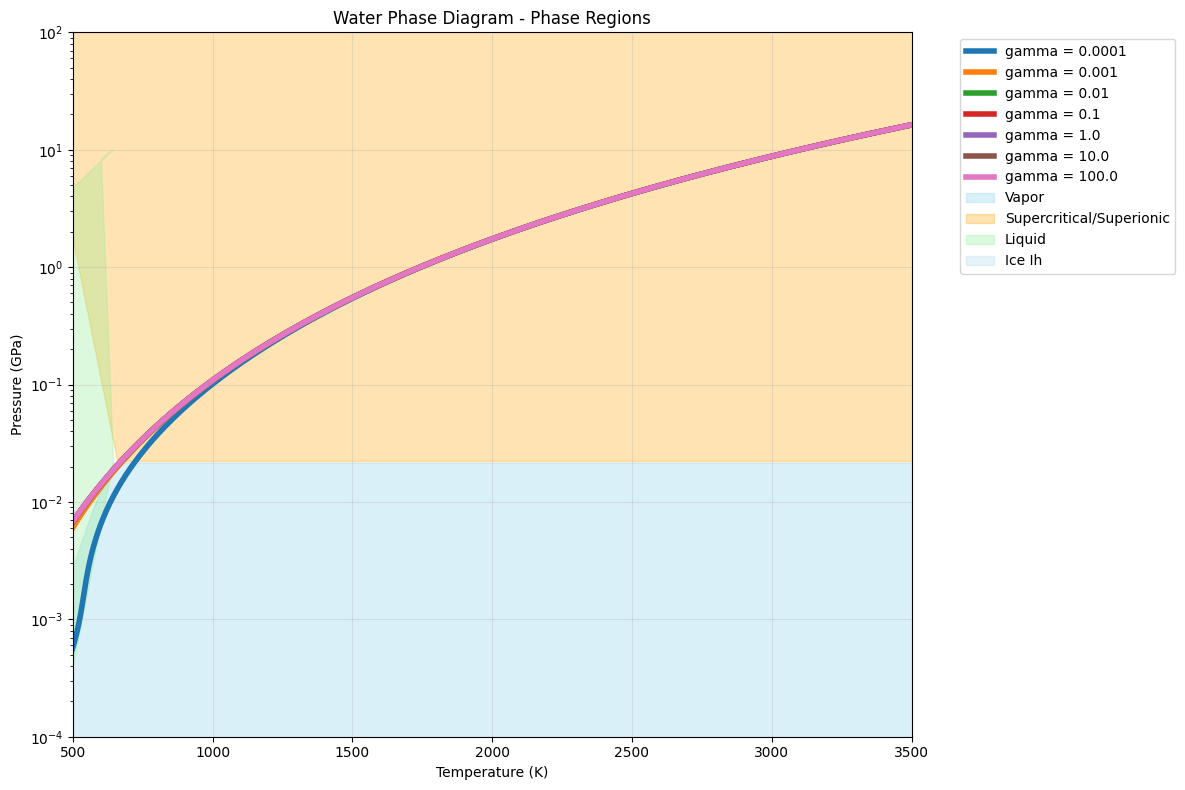

In [133]:
from scipy.spatial import ConvexHull
import matplotlib.patches as mpatches
    
plt.figure(figsize=(12, 8))
for gamma in gammas:
    T_new = (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma*np.sqrt(3))) + ((gamma/(np.sqrt(3)))- (1/(gamma*np.sqrt(3))))*np.exp(-gamma*tau*np.sqrt(3))))**(1/4)
    plt.plot(T_new, max(scale_factors)*tau*10**(-4), lw=4, ls="-", label=f"gamma = {gamma}")    
# For each phase, create a convex hull of its points
for phase_name in unique_phases:
    phase_id = phase_name_to_id[phase_name]
    mask = df['phase_id'] == phase_id
        
    if mask.sum() > 3:  # Need at least 3 points for a hull
        points = df.loc[mask, ['temp_K', 'press_GPa']].values
            
        # For log-scale pressure, use log of pressure for hull calculation
        points_log = np.column_stack([points[:, 0], np.log10(points[:, 1])])
            
        try:
            hull = ConvexHull(points_log)
            hull_points = points[hull.vertices]
                
            # Sort by angle for proper polygon
            center = np.mean(hull_points, axis=0)
            angles = np.arctan2(hull_points[:,1] - center[1], 
                                hull_points[:,0] - center[0])
            hull_points = hull_points[np.argsort(angles)]
                
            # Fill the hull
            plt.fill(hull_points[:, 0], hull_points[:, 1],
                    alpha=0.3, color=phase_colors[phase_name],
                    label=phase_name)
        except:
            # If hull fails, just scatter plot
            plt.scatter(points[:, 0], points[:, 1],
                        c=phase_colors[phase_name],
                        s=1, alpha=0.3, label=phase_name)
    
plt.yscale('log')
plt.xlabel('Temperature (K)')
plt.xlim(500, 3500)
plt.ylim(1e-4, 1e2)
plt.ylabel('Pressure (GPa)')
plt.title('Water Phase Diagram - Phase Regions')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

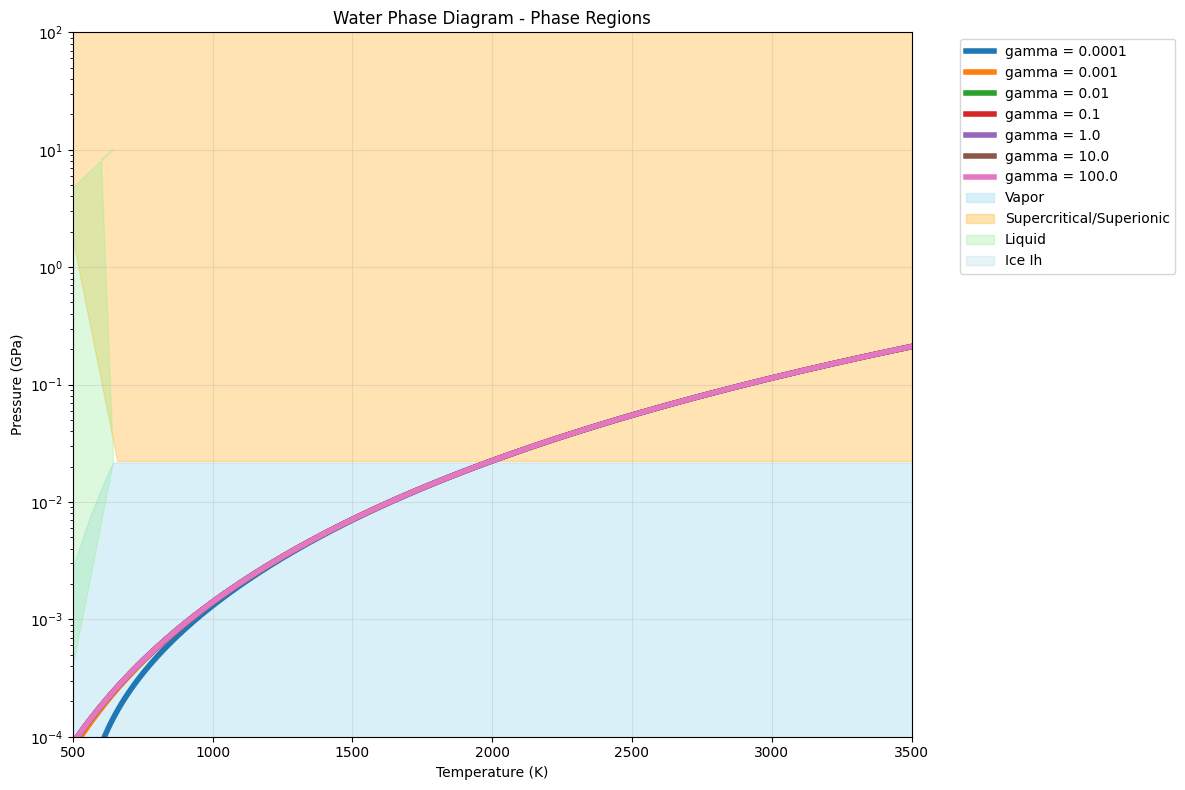

In [134]:
plt.figure(figsize=(12, 8))
for gamma in gammas:
    T_new = (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma*np.sqrt(3))) + ((gamma/(np.sqrt(3)))- (1/(gamma*np.sqrt(3))))*np.exp(-gamma*tau*np.sqrt(3))))**(1/4)
    plt.plot(T_new, min(scale_factors)*tau*10**(-4), lw=4, ls="-", label=f"gamma = {gamma}")    
# For each phase, create a convex hull of its points
for phase_name in unique_phases:
    phase_id = phase_name_to_id[phase_name]
    mask = df['phase_id'] == phase_id
        
    if mask.sum() > 3:  # Need at least 3 points for a hull
        points = df.loc[mask, ['temp_K', 'press_GPa']].values
            
        # For log-scale pressure, use log of pressure for hull calculation
        points_log = np.column_stack([points[:, 0], np.log10(points[:, 1])])
            
        try:
            hull = ConvexHull(points_log)
            hull_points = points[hull.vertices]
                
            # Sort by angle for proper polygon
            center = np.mean(hull_points, axis=0)
            angles = np.arctan2(hull_points[:,1] - center[1], 
                                hull_points[:,0] - center[0])
            hull_points = hull_points[np.argsort(angles)]
                
            # Fill the hull
            plt.fill(hull_points[:, 0], hull_points[:, 1],
                    alpha=0.3, color=phase_colors[phase_name],
                    label=phase_name)
        except:
            # If hull fails, just scatter plot
            plt.scatter(points[:, 0], points[:, 1],
                        c=phase_colors[phase_name],
                        s=1, alpha=0.3, label=phase_name)
    
plt.yscale('log')
plt.xlabel('Temperature (K)')
plt.xlim(500, 3500)
plt.ylim(1e-4, 1e2)
plt.ylabel('Pressure (GPa)')
plt.title('Water Phase Diagram - Phase Regions')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
tau = np.logspace(-10,10,1000)
T_new_1 = (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma_1*np.sqrt(3))) + ((gamma_1/(np.sqrt(3)))- (1/(gamma_1*np.sqrt(3))))*np.exp(-gamma_1*tau*np.sqrt(3))))**(1/4)
T_new_2 = (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma_2*np.sqrt(3))) + ((gamma_2/(np.sqrt(3)))- (1/(gamma_2*np.sqrt(3))))*np.exp(-gamma_2*tau*np.sqrt(3))))**(1/4)
T_new_3 = (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma_3*np.sqrt(3))) + ((gamma_3/(np.sqrt(3)))- (1/(gamma_3*np.sqrt(3))))*np.exp(-gamma_3*tau*np.sqrt(3))))**(1/4)

In [10]:
print(T_new_2)

[  54.51070450981699    54.51070450990937    54.51070451000606
   54.51070451010739    54.510704510213465   54.51070451032456
   54.51070451044089    54.510704510562654   54.51070451069024
   54.51070451082379    54.5107045109637     54.51070451111015
   54.51070451126354    54.51070451142416    54.510704511592365
   54.5107045117685     54.51070451195293    54.51070451214607
   54.510704512348354   54.51070451256015    54.51070451278196
   54.5107045130142     54.510704513257416   54.5107045135121
   54.51070451377879    54.51070451405806    54.51070451435056
   54.51070451465679    54.51070451497749    54.51070451531332
   54.51070451566502    54.510704516033286   54.51070451641891
   54.51070451682274    54.51070451724564    54.510704517688495
   54.5107045181522     54.5107045186378     54.510704519146344
   54.510704519678846   54.51070452023645    54.51070452082042
   54.51070452143187    54.510704522072224   54.51070452274274
   54.51070452344495    54.510704524180255   54.51070

# Atmosphere modelling

In [20]:
gamma = 0.05
mantle_melt_fraction = 1
init_metallicitys = [1]
scale_factors = []
fO2_log10_shifts = np.linspace(-6, 6, 50) 
init_metallicity = 1
for fO2_log10_shift in fO2_log10_shifts:
    shift = f"{fO2_log10_shift:.2g}"
    filename = f"./excel_Uranus_solar_3000K/HOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}.xlsx"
    Pressure = pd.read_excel(filename, sheet_name="state")["pressure"]
    scale_factor = Pressure/find_tau(tau,3000, 10e7)
    scale_factors.append(scale_factor.iloc[-1])
    scale_factors.append(scale_factor.iloc[0])

In [21]:
print(max(scale_factors))
print(min(scale_factors))

0.0005916239876265923
7.643182484120057e-06


In [29]:
Lower_Pressures = tau*min(scale_factors)
Higher_Pressures = tau*max(scale_factors)
Temperatures = Temp_profile(tau)

[5.916239876265923e-14 6.195349256941557e-14 6.487626130486040e-14
 6.793691697333524e-14 7.114196464178906e-14 7.449821626554001e-14
 7.801280516629264e-14 8.169320119318189e-14 8.554722659906694e-14
 8.958307266581800e-14 9.380931711393155e-14 9.823494233347542e-14
 1.028693544751123e-13 1.077224034417767e-13 1.128044038234957e-13
 1.181261568198485e-13 1.236989731966568e-13 1.295346973256997e-13
 1.356457323585457e-13 1.420450665880060e-13 1.487463010532371e-13
 1.557636784471645e-13 1.631121133876670e-13 1.708072241168587e-13
 1.788653656958425e-13 1.873036647654868e-13 1.961400559471046e-13
 2.053933199604010e-13 2.150831235397046e-13 2.252300612333191e-13
 2.358556991748361e-13 2.469826209194384e-13 2.586344754426155e-13
 2.708360274033040e-13 2.836132097782851e-13 2.969931789797042e-13
 3.110043725728605e-13 3.256765697169379e-13 3.410409544571373e-13
 3.571301820027312e-13 3.739784481319050e-13 3.916215618708989e-13
 4.100970216019199e-13 4.294440947615831e-13 4.497039012992730

In [36]:
indices = [i for i, v in enumerate(Temperatures) if 500 < v < 3000]
Temp_new = Temperatures[indices]
Lower_Pressures = tau[indices]*min(scale_factors)
Higher_Pressures = tau[indices]*max(scale_factors)
tau_new = tau[indices]
print(Temp_new)
print(Lower_Pressures)
print(tau_new)
print(Higher_Pressures)



[ 504.73881682521505  510.5760959253191   516.4814833599437
  522.4557534386666   528.4996899549492   534.6140862792212
  540.7997454535832   547.0574802881291   553.3881134588918
  559.7924776074169   566.2714154419676   572.8257798403664
  579.4564339544767   586.1642513163325   592.9501159459202
  599.8149224606178   606.7595761863013   613.7849932701212
  620.8921007949604   628.0818368955784   635.355150876452
  642.7130033313192   650.1563662644386   657.6862232135684
  665.3035693746815   673.0094117284218   680.8047691683134
  688.6906726307368   696.6681652266793   704.7383023752745
  712.902151939142    721.1607943615395   729.5153228053423
  737.9668432938611   746.5164748535142   755.1653496583664
  763.9146131765515   772.7654243185907   781.7189555876249
  790.7763932315751   799.9389373972475   809.2078022864001
  818.584216313787    828.0694222671993   837.6646774695182
  847.3712539428002   857.1904385744114   867.1235332852325
  877.1718551999458   887.3367368194398  

In [49]:
Lower_Pressures_Scaling = Lower_Pressures/max(Lower_Pressures)
Higher_Pressures_Scaling = Higher_Pressures/max(Higher_Pressures)
print(Lower_Pressures_Scaling)
print(Higher_Pressures_Scaling)

[8.258799387844256e-04 8.648423275731711e-04 9.056428379445277e-04
 9.483681866285908e-04 9.931091813749782e-04 1.039960913954118e-03
 1.089022962263728e-03 1.140399601970031e-03 1.194200028133530e-03
 1.250538587290389e-03 1.309535020482665e-03 1.371314717753943e-03
 1.436008984651258e-03 1.503755321299735e-03 1.574697714643084e-03
 1.648986944471062e-03 1.726780903884353e-03 1.808244934877948e-03
 1.893552179756292e-03 1.982883949127068e-03 2.076430107255771e-03
 2.174389475600076e-03 2.276970255381676e-03 2.384390470093716e-03
 2.496878428884322e-03 2.614673211801087e-03 2.738025177927852e-03
 2.867196497493764e-03 3.002461709085543e-03 3.144108303147259e-03
 3.292437333007762e-03 3.447764054734458e-03 3.610418597173331e-03
 3.780746663599342e-03 3.959110266468451e-03 4.145888496832903e-03
 4.341478330055084e-03 4.546295469532391e-03 4.760775230226359e-03
 4.985373463873885e-03 5.220567527846966e-03 5.466857299720170e-03
 5.724766239702168e-03 5.994842503189397e-03 6.277660105806488

In [51]:
# setup atmodeller planet object as atmosphere with no magma (melt fraction = 0)
atm_scalings = np.logspace(-10, 0, num=len(Temp_new))
atm_scalings = Lower_Pressures_Scaling
mantle_melt_fraction = 1
state: ThermodynamicStateProtocol = ThermodynamicState(Temp_new, Lower_Pressures)
init_metallicitys = [1]  # metallicity in x solar units
model_atm_magma_sol_real = EquilibriumModel(species_HOSi_magma_sol_real)
fO2_log10_shift = -6
shift = -6

# Magma - Solubility - Real Gas
filename = f"./excel_Uranus_solar_3000K/HOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}.xlsx"
H_mass_atm_magma_sol_real = pd.read_excel(filename, sheet_name="element_H")[
    "gas_mass"
][0]
Si_mass_atm_magma_sol_real = pd.read_excel(filename, sheet_name="element_Si")[
    "gas_mass"
][0]
O_mass_atm_magma_sol_real = pd.read_excel(filename, sheet_name="element_O")[
    "gas_mass"
][0]
tot_pressure_magma_sol_real = pd.read_excel(filename, sheet_name="state")["pressure"][
    0
]

mass_constraints = {
    "H": H_mass_atm_magma_sol_real * atm_scalings,
    "O": O_mass_atm_magma_sol_real * atm_scalings,
    "Si": Si_mass_atm_magma_sol_real * atm_scalings,
}

model_atm_magma_sol_real.solve(
    state=state,
    mass_constraints=mass_constraints,
    solver_parameters=SolverParameters(multistart=50),
)
output_atm_magma_sol_real = model_atm_magma_sol_real.output

output_atm_magma_sol_real.quick_look()

output_atm_magma_sol_real.to_excel(
    f"./excel_Uranus_solar_3000K/TEST.xlsx"
)


[22:01:13 - atmodeller.classes             - INFO     ] - species_network = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'OSi_g: CombinedRealGas, NoSolubility', 'H4Si_g: CombinedRealGas, NoSolubility', 'O2Si_cd: CondensateActivity, NoSolubility')
[22:01:13 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[22:01:13 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2O_g = 2.0 H2_g + 1.0 O2_g',
 1: '3.0 H2_g + 1.0 OSi_g = 1.0 H2O_g + 1.0 H4Si_g',
 2: '1.0 H2O_g + 1.0 OSi_g = 1.0 H2_g + 1.0 O2Si_cd'}
[22:02:53 - atmodeller.classes             - INFO     ] - Solve (robust) complete: 153 (98.71%) successful model(s)
[22:02:53 - atmodeller.classes             - WARNING  ] - 2 (1.29%) model(s) still failed
[22:02:53 - atmodeller.classes             - INFO     ] - Multistart summary: 2 (1.29%) models(s) required 0 attempt